In [ ]:
import os
import itertools
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_style('darkgrid')
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.metrics import classification_report, roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.preprocessing import label_binarize
from itertools import cycle
import cv2
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm
import torchvision.transforms as transforms
from torchvision import models
from torchvision.datasets import ImageFolder
from felaswin_net import FeLASwinNet
import Training_Evaluation_Fuctions  
from Training_Evaluation_Fuctions import (
    train_model,
    evaluate_model,
    evaluate_model_with_metrics,
    run_corruption_analysis,
    run_uncertainty_analysis,
)
# ignore the warnings 
import warnings
warnings.filterwarnings('ignore')

# Dataset Loading

In [2]:
data_dir = "D:\\lung cancer dataset\\Preprocessed1"

In [3]:
# Custom dataset loader for image data
class CustomImageDataset(Dataset):
    def __init__(self, filepaths, labels, transform=None):
        self.filepaths = filepaths
        self.labels = labels
        self.transform = transform
    
    def __len__(self):
        return len(self.filepaths)
    
    def __getitem__(self, idx):
        image = cv2.imread(self.filepaths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

# Load data

def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)
        for file in filelist:
            fpath = os.path.join(foldpath, file)
            
            filepaths.append(fpath)
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

# data_dir = "F:\\Ml files\\XAI\\Grape\\Combined (D4)"
df = loading_the_data(data_dir)

       Class  Number of Images
0     Benign               587
1  Malignant              1611
2     Normal               416


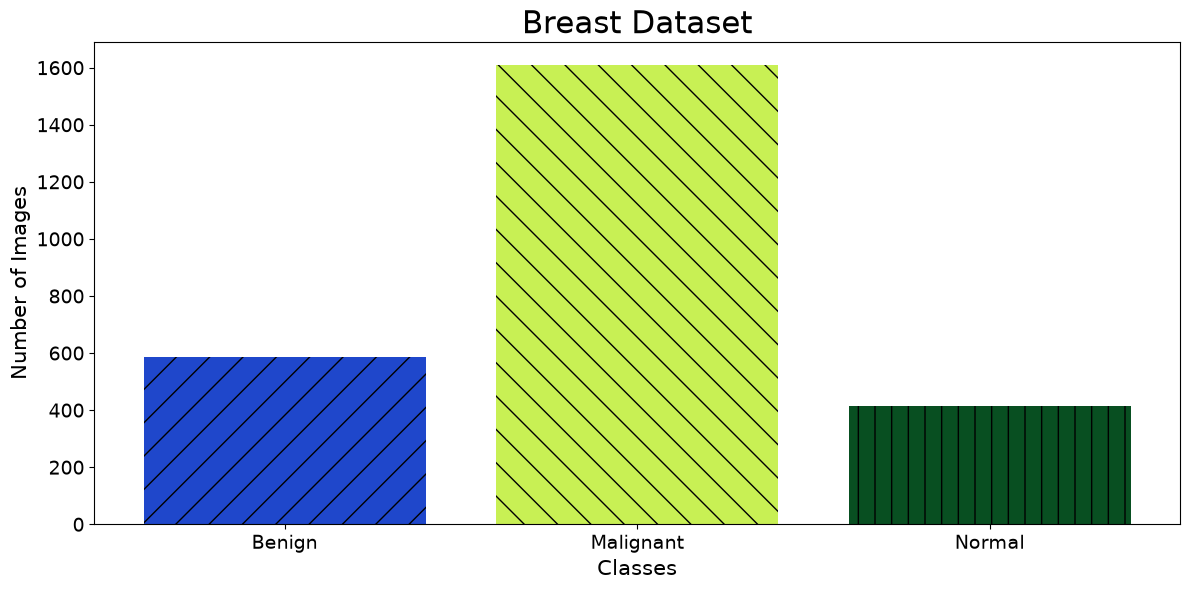

In [4]:
import random
plt.style.use('default')

# Get the list of categories (subfolder names)
categories = [folder for folder in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, folder))]

# Count the number of images in each category
image_counts = []
for category in categories:
    category_path = os.path.join(data_dir, category)
    image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]
    image_counts.append(len(image_files))

# Create a dataframe to show the number of images per class
data = pd.DataFrame({"Class": categories, "Number of Images": image_counts})
print(data)


# Create a bar chart to visualize the number of images in each category
plt.figure(figsize=(12, 6))
patterns = ["/", "\\", "|", "-", "+", "x", "o", "*"]  # Define patterns for bars
colors = ["#" + ''.join(random.choices('0123456789ABCDEF', k=6)) for _ in categories]  # Generate unique colors
bars = plt.bar(categories, image_counts, color=colors)
for bar, pattern in zip(bars, patterns):
    bar.set_hatch(pattern)

plt.title("Breast Dataset", fontsize=22)
plt.xlabel("Classes", fontsize=15)
plt.ylabel("Number of Images", fontsize=15)
plt.xticks(rotation=0, fontsize=14)
plt.yticks(fontsize=14)
plt.tight_layout()
plt.savefig('D:\\CapstoneProjectModel\\KidneyDist.png', format='png', dpi=600)
plt.show()


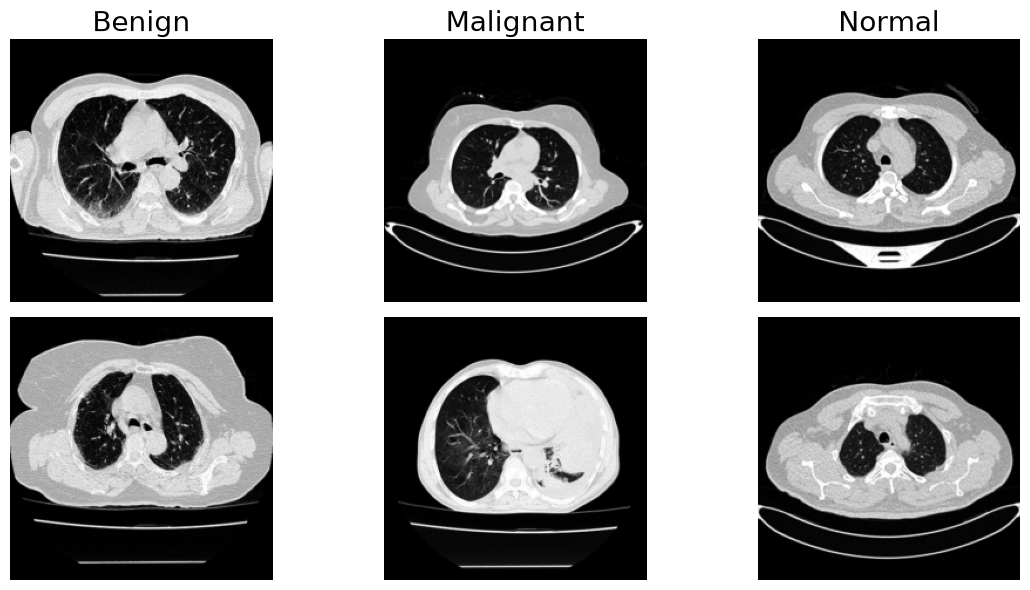

In [5]:
from PIL import Image

# Define a transform to resize images and convert them to tensors
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # Resize images to 512x512 for uniformity
    transforms.ToTensor()
])

# Number of rows and columns
rows, cols = 2, 3

# Ensure categories list contains at least `cols` categories
if len(categories) < cols:
    raise ValueError("Not enough categories to display.")

# Initialize a figure for visualization
plt.figure(figsize=(12, 6))  # Adjusted figure size for better clarity with 2 rows and 5 columns

# Iterate twice to create two rows with different images from the same categories
for row in range(rows):
    for col, category in enumerate(categories[:cols]):  # Use the first `cols` categories
        # Get the path of the category folder
        category_path = os.path.join(data_dir, category)

        # Get the list of image files in the category folder
        image_files = [file for file in os.listdir(category_path) if file.lower().endswith(('png', 'jpg', 'jpeg', 'bmp', 'tiff'))]

        # Ensure there is at least one image in the category
        if not image_files:
            print(f"No images found in category: {category}")
            continue

        # Randomly select an image from the category
        image_path = os.path.join(category_path, random.choice(image_files))
        image = Image.open(image_path).convert("RGB")

        # Apply the transform
        image = transform(image)

        # Convert the tensor back to a PIL image for visualization
        image = transforms.ToPILImage()(image)

        # Add the image to the plot
        plt.subplot(rows, cols, row * cols + col + 1)
        plt.imshow(image)
        
        # Set title only for the first row
        if row == 0:
            plt.title(category, fontsize=20)
        
        plt.axis('off')

# Adjust layout and display the plot
plt.tight_layout()
plt.savefig('D:\\CapstoneProjectModel\\lung.png', format='png', dpi=600)
plt.show()

# Data Preprocessing 

In [13]:
import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image

# ==========================================
# 1. DIRECTORY CONFIGURATION
# ==========================================
data_dir = r"D:\lung cancer dataset\Original"
output_dir = r"D:\lung cancer dataset\Preprocessed"

# ==========================================
# 2. X-RAY OPTIMIZED PREPROCESSING (CLAHE)
# ==========================================
def apply_target_contrast_enhancement(pil_img: Image.Image) -> Image.Image:
    """
    Ignores black background padding when calculating contrast percentiles 
    and applies gamma correction to force lung parenchyma into deep black.
    """
    gray = np.array(pil_img.convert("L"), dtype=np.float32)

    # 1. Isolate non-background pixels (>15) to calculate true percentile thresholds
    non_bg_pixels = gray[gray > 15]
    
    if len(non_bg_pixels) > 0:
        p_low = np.percentile(non_bg_pixels, 20)  # Target the lung interior gray levels
        p_high = np.percentile(non_bg_pixels, 98)
    else:
        p_low, p_high = 0, 255

    # 2. Dynamic range contrast stretching
    if p_high - p_low > 0:
        stretched = np.clip((gray - p_low) / (p_high - p_low) * 255.0, 0, 255)
    else:
        stretched = gray

    # 3. Gamma correction to suppress remaining mid-gray haze to deep black
    gamma = 1.4
    gamma_corrected = np.power(stretched / 255.0, gamma) * 255.0
    gamma_corrected = np.clip(gamma_corrected, 0, 255).astype(np.uint8)

    # 4. Sharpen high-frequency vessel and edge structures
    blurred = cv2.GaussianBlur(gamma_corrected, (3, 3), 1.0)
    sharpened = cv2.addWeighted(gamma_corrected, 1.4, blurred, -0.4, 0)
    sharpened = np.clip(sharpened, 0, 255).astype(np.uint8)

    # 5. Convert to 3-channel grayscale for PyTorch models
    rgb = cv2.cvtColor(sharpened, cv2.COLOR_GRAY2RGB)

    return Image.fromarray(rgb)


# ==========================================
# 3. LOAD DATA
# ==========================================
def loading_the_data(data_dir):
    filepaths = []
    labels = []
    folds = os.listdir(data_dir)
    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        if os.path.isdir(foldpath):
            filelist = os.listdir(foldpath)
            for file in filelist:
                fpath = os.path.join(foldpath, file)
                filepaths.append(fpath)
                labels.append(fold)
    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

df = loading_the_data(data_dir)
print(f"Total images to process: {len(df)}")

# ==========================================
# 4. PROCESS AND SAVE IMAGES
# ==========================================
os.makedirs(output_dir, exist_ok=True)
processed_count = 0

for index, row in df.iterrows():
    src_path = row['filepaths']
    label = row['labels']
    filename = os.path.basename(src_path)
    
    class_out_dir = os.path.join(output_dir, label)
    os.makedirs(class_out_dir, exist_ok=True)
    
    dest_path = os.path.join(class_out_dir, filename)
    
    try:
        img = Image.open(src_path)
            
        # Apply high-contrast processing
        img = apply_target_contrast_enhancement(img)
        
        # Save output image
        img.save(dest_path, quality=95, subsampling=0)
        
        processed_count += 1
        if processed_count % 100 == 0:
            print(f"Processed {processed_count} / {len(df)} images...")
            
    except Exception as e:
        print(f"Error processing {src_path}: {e}")

print("\n✅ Target Contrast Enhancement Complete!")
print(f"Your preprocessed dataset is ready at: {output_dir}")

Total images to process: 2614
Processed 100 / 2614 images...
Processed 200 / 2614 images...
Processed 300 / 2614 images...
Processed 400 / 2614 images...
Processed 500 / 2614 images...
Processed 600 / 2614 images...
Processed 700 / 2614 images...
Processed 800 / 2614 images...
Processed 900 / 2614 images...
Processed 1000 / 2614 images...
Processed 1100 / 2614 images...
Processed 1200 / 2614 images...
Processed 1300 / 2614 images...
Processed 1400 / 2614 images...
Processed 1500 / 2614 images...
Processed 1600 / 2614 images...
Processed 1700 / 2614 images...
Processed 1800 / 2614 images...
Processed 1900 / 2614 images...
Processed 2000 / 2614 images...
Processed 2100 / 2614 images...
Processed 2200 / 2614 images...
Processed 2300 / 2614 images...
Processed 2400 / 2614 images...
Processed 2500 / 2614 images...
Processed 2600 / 2614 images...

✅ Target Contrast Enhancement Complete!
Your preprocessed dataset is ready at: D:\lung cancer dataset\Preprocessed


#  Data Transformation & Splitting

In [5]:
data_transform = transforms.Compose([
    transforms.ToTensor(),  # Convert to Tensor first
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

In [6]:
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['labels'], random_state=42)  # 80% train, 20% temp
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df['labels'], random_state=42)  # 75% of temp (15% of total) for test


In [7]:
import pandas as pd

# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)

           Training  Validation  Testing  Total
labels                                         
Malignant      1289         161      161   1611
Benign          469          59       59    587
Normal          333          41       42    416


# Train set Augmentation

In [8]:
from PIL import Image
import albumentations as A

# --------------------------------------------------
# AUGMENTATION PIPELINE
# Albumentations replacement for the imgaug pipeline
# --------------------------------------------------
train_aug = A.Compose([
    # 1. Spatial Transforms (Mimics patient misalignment & breathing)
    A.ShiftScaleRotate(
        shift_limit=0.1,   # Minor centering shifts
        scale_limit=0.1,   # Minor distance variations
        rotate_limit=15,     # Restrict rotation to 15 degrees max
        border_mode=cv2.BORDER_CONSTANT, 
        value=0, 
        p=0.5
    ),
    A.ElasticTransform(
        alpha=300, 
        sigma=10, 
        alpha_affine=0, 
        p=0.3
    ), # Simulates varying lung capacities
    
    # 2. Pixel-level Transforms (Mimics machine exposure & noise)
    A.RandomBrightnessContrast(
        brightness_limit=0.1, 
        contrast_limit=0.1, 
        p=0.5
    ),
    A.GaussNoise(
        var_limit=(5.0, 15.0), 
        p=0.3
    ),
])

# --------------------------------------------------
# OFFLINE TRAIN AUGMENTATION FUNCTION
# --------------------------------------------------
def offline_augment_train(train_df, output_root, target_per_class=2000):

    os.makedirs(output_root, exist_ok=True)

    for label in train_df['labels'].unique():

        print(f"\nProcessing class: {label}")

        class_df = train_df[train_df['labels'] == label]
        class_images = class_df['filepaths'].values

        class_output_dir = os.path.join(output_root, label)
        os.makedirs(class_output_dir, exist_ok=True)

        original_count = len(class_images)

        # --------------------------------------------------
        # Copy original images first
        # --------------------------------------------------
        for idx, img_path in enumerate(class_images):

            img = Image.open(img_path).convert("RGB")

            save_path = os.path.join(
                class_output_dir,
                f"original_{idx}.jpg"
            )

            img.save(save_path, quality=100)

        print(f"Original images saved: {original_count}")

        # --------------------------------------------------
        # Determine augmentations needed
        # --------------------------------------------------
        if original_count >= target_per_class:
            print("No augmentation needed (already balanced).")
            continue

        augment_needed = target_per_class - original_count

        augment_per_image = augment_needed // original_count + 1

        augmented_count = 0

        # --------------------------------------------------
        # Generate augmented images
        # --------------------------------------------------
        for idx, img_path in enumerate(tqdm(class_images)):

            image = np.array(
                Image.open(img_path).convert("RGB")
            )

            for j in range(augment_per_image):

                # Albumentations augmentation
                augmented = train_aug(image=image)

                augmented_image = augmented["image"]

                augmented_pil = Image.fromarray(
                    augmented_image
                )

                save_path = os.path.join(
                    class_output_dir,
                    f"aug_{idx}_{j}.jpg"
                )

                augmented_pil.save(
                    save_path,
                    quality=100
                )

                augmented_count += 1

                # Stop exactly at target_per_class
                if original_count + augmented_count >= target_per_class:
                    break

            if original_count + augmented_count >= target_per_class:
                break

        print(f"Augmented images created: {augmented_count}")
        print(
            f"Total images in class '{label}': "
            f"{original_count + augmented_count}"
        )

In [15]:
expanded_train_dir = "D:\\lung cancer dataset\\TrainAug"

offline_augment_train(
    train_df,
    expanded_train_dir,
    target_per_class=2000   # ← choose desired class size
)


Processing class: Malignant cases
Original images saved: 1289


 55%|█████▌    | 710/1289 [00:10<00:08, 66.60it/s]


Augmented images created: 711
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:26<00:05, 10.48it/s]


Augmented images created: 1667
Total images in class 'Normal cases': 2000

Processing class: Benign cases
Original images saved: 469


 81%|████████▏ | 382/469 [00:21<00:04, 17.47it/s]

Augmented images created: 1531
Total images in class 'Benign cases': 2000




In [29]:
def visualize_augmentations(image_path, output_path="augmentation_samples.jpg"):
    image = np.array(Image.open(image_path).convert("RGB"))

    transform_dict = {
        "Original": None,
        "ShiftScaleRotate": A.Compose([
            A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, 
                               border_mode=cv2.BORDER_CONSTANT, p=1.0)
        ]),
        "ElasticTransform": A.Compose([
            A.ElasticTransform(alpha=300, sigma=10, alpha_affine=0, p=1.0)
        ]),
        "RandomBrightnessContrast": A.Compose([
            A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=1.0)
        ]),
        "GaussNoise": A.Compose([
            A.GaussNoise(var_limit=(5.0, 15.0), p=1.0)
        ])
    }

    fig, axes = plt.subplots(1, 5, figsize=(24, 8), dpi=600)
    axes = axes.flatten()

    for ax in axes:
        ax.axis("off")

    for ax, (title, transform) in zip(axes, transform_dict.items()):
        if transform is None:
            aug_img = image
        else:
            aug_img = transform(image=image)["image"]

        ax.imshow(aug_img)
        ax.set_title(title, fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.savefig(output_path, dpi=600, bbox_inches="tight")
    plt.show()

visualize_augmentations(r"D:\lung cancer dataset\Preprocessed1\Benign cases\Bengin case (1).jpg")

In [16]:
def loading_the_data(data_dir):
    filepaths = []
    labels = []

    folds = os.listdir(data_dir)

    for fold in folds:
        foldpath = os.path.join(data_dir, fold)
        filelist = os.listdir(foldpath)

        for file in filelist:
            filepaths.append(os.path.join(foldpath, file))
            labels.append(fold)

    return pd.DataFrame({"filepaths": filepaths, "labels": labels})

In [17]:
expanded_train_df = loading_the_data(expanded_train_dir)

In [8]:
label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}

train_labels = train_df['labels'].map(label_mapping).values
val_labels = val_df['labels'].map(label_mapping).values
test_labels = test_df['labels'].map(label_mapping).values

In [19]:
from my_dataset import CustomImageDataset
train_dataset = CustomImageDataset(
    expanded_train_df['filepaths'].values,
    expanded_train_df['labels'].map(label_mapping).values,
    transform=data_transform
)

val_dataset = CustomImageDataset(
    val_df['filepaths'].values,
    val_labels,
    transform=data_transform
)

test_dataset = CustomImageDataset(
    test_df['filepaths'].values,
    test_labels,
    transform=data_transform
)

In [9]:
from my_dataset import CustomImageDataset
train_dataset = CustomImageDataset(
    train_df['filepaths'].values,
    train_df['labels'].map(label_mapping).values,
    transform=data_transform
)

val_dataset = CustomImageDataset(
    val_df['filepaths'].values,
    val_labels,
    transform=data_transform
)

test_dataset = CustomImageDataset(
    test_df['filepaths'].values,
    test_labels,
    transform=data_transform
)

In [10]:
train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True, num_workers=4, pin_memory=True)

val_loader = DataLoader(val_dataset, batch_size=32,
                        shuffle=False, num_workers=4, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=32,
                         shuffle=False, num_workers=0, pin_memory=True)

In [21]:
# Assuming train_df, val_df, and test_df have a 'labels' column
train_counts = expanded_train_df['labels'].value_counts()
val_counts = val_df['labels'].value_counts()
test_counts = test_df['labels'].value_counts()

# Combine into a single DataFrame
class_counts = pd.DataFrame({
    'Training': train_counts,
    'Validation': val_counts,
    'Testing': test_counts
}).fillna(0).astype(int)  # Fill NaN with 0 and convert to integer

# Add a column for total counts (optional)
class_counts['Total'] = class_counts.sum(axis=1)

# Display the table
print(class_counts)


                 Training  Validation  Testing  Total
labels                                               
Benign cases         2000          59       59   2118
Malignant cases      2000         161      161   2322
Normal cases         2000          41       42   2083


In [11]:
# Model setup
if not torch.cuda.is_available():
    raise RuntimeError('CUDA device is not available. Please ensure a GPU is available to train the model.')
device = torch.device('cuda')

# Ablation Study Function

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef, confusion_matrix

# ══════════════════════════════════════════════════════════════════════════════
# 1. Ablation-Ready Modules
# ══════════════════════════════════════════════════════════════════════════════

class StandardDownsample(nn.Module):
    """Baseline replacement for AMSFA using standard strided convolution."""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.down = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.GELU()
        )
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.down(x)


class ResNetFetleBlockAblation(nn.Module):
    """FETLE Block with toggle support for Ablation Experiments."""
    def __init__(self, channels: int, use_fetle: bool = True):
        super().__init__()
        self.use_fetle = use_fetle
        
        self.resnet_path = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.GELU(),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels)
        )
        
        if self.use_fetle:
            self.fetle_path = FETLE(channels)
            self.branch_w = nn.Parameter(torch.ones(2))
        else:
            self.branch_w = nn.Parameter(torch.ones(1))
            
        self.final_activation = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        w = F.softmax(self.branch_w, dim=0)
        if self.use_fetle:
            out = x + (w[0] * self.resnet_path(x)) + (w[1] * self.fetle_path(x))
        else:
            out = x + (w[0] * self.resnet_path(x))
        return self.final_activation(out)


# ══════════════════════════════════════════════════════════════════════════════
# 2. Configurable Modular Architecture
# ══════════════════════════════════════════════════════════════════════════════

class FetleSwinHybridAblation(nn.Module):
    def __init__(
        self, 
        num_classes: int = 3, 
        drop_path_rate: float = 0.1, 
        attn_drop_rate: float = 0.1,
        use_fetle: bool = True,
        use_amsfa: bool = True
    ):
        super().__init__()
        self.use_fetle = use_fetle
        self.use_amsfa = use_amsfa
        
        # Stem: 224x224 -> 56x56
        self.stem = nn.Sequential(
            nn.Conv2d(3, 48, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(48),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        
        # Stage 1: 56x56 -> 28x28
        self.stage1_fetle = ResNetFetleBlockAblation(48, use_fetle=use_fetle)
        self.stage1_down = AMSFA(48, 96) if use_amsfa else StandardDownsample(48, 96)
        
        # Stage 2: 28x28 -> 14x14
        self.stage2_fetle = ResNetFetleBlockAblation(96, use_fetle=use_fetle)
        self.stage2_down = AMSFA(96, 128) if use_amsfa else StandardDownsample(96, 128)
        
        # Swin components
        dpr = [x.item() for x in torch.linspace(0, drop_path_rate, 6)]

        # Stage 3 (Swin Bottleneck 1)
        self.stage3_swin = nn.Sequential(
            SwinBlockNative(128, num_heads=4, window_size=7, shift_size=0, input_resolution=(14, 14), 
                            attn_drop_rate=attn_drop_rate, drop_path_rate=dpr[0]),
            SwinBlockNative(128, num_heads=4, window_size=7, shift_size=3, input_resolution=(14, 14), 
                            attn_drop_rate=attn_drop_rate, drop_path_rate=dpr[1]),
            SwinBlockNative(128, num_heads=4, window_size=7, shift_size=0, input_resolution=(14, 14), 
                            attn_drop_rate=attn_drop_rate, drop_path_rate=dpr[2]),
            SwinBlockNative(128, num_heads=4, window_size=7, shift_size=3, input_resolution=(14, 14), 
                            attn_drop_rate=attn_drop_rate, drop_path_rate=dpr[3])
        )
        
        # Stage 4: 14x14 -> 7x7
        self.stage4_down = AMSFA(128, 256) if use_amsfa else StandardDownsample(128, 256)
        
        # Stage 4 Swin
        self.stage4_swin = nn.Sequential(
            SwinBlockNative(256, num_heads=8, window_size=7, shift_size=0, input_resolution=(7, 7), 
                            attn_drop_rate=attn_drop_rate, drop_path_rate=dpr[4]),
            SwinBlockNative(256, num_heads=8, window_size=7, shift_size=0, input_resolution=(7, 7), 
                            attn_drop_rate=attn_drop_rate, drop_path_rate=dpr[5])
        )
        
        # Classifier
        self.norm = nn.LayerNorm(256)
        self.head = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.stage1_down(self.stage1_fetle(x))
        x = self.stage2_down(self.stage2_fetle(x))
        
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        x = self.stage3_swin(x)
        
        x = x.transpose(1, 2).view(B, C, H, W)
        x = self.stage4_down(x)
        
        B, C, H, W = x.shape
        x = x.flatten(2).transpose(1, 2)
        x = self.stage4_swin(x)
        
        x = self.norm(x)
        x = x.mean(dim=1)
        return self.head(x)


# ══════════════════════════════════════════════════════════════════════════════
# 3. Evaluation & Metrics Engine
# ══════════════════════════════════════════════════════════════════════════════

def compute_ablation_metrics(model: nn.Module, dataloader: torch.utils.data.DataLoader, device: str) -> dict:
    """Evaluates model and computes Accuracy, F1 Score, MCC, and Specificity."""
    model.eval()
    all_labels, all_preds = [], []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            preds = torch.argmax(outputs, dim=1)

            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)

    # Calculate requested metrics
    acc = accuracy_score(all_labels, all_preds)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)

    # Compute Macro Specificity
    cm = confusion_matrix(all_labels, all_preds)
    specs = []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        specs.append(tn / (tn + fp) if (tn + fp) > 0 else 0.0)
    specificity = np.mean(specs)

    return {
        "Accuracy": acc,
        "F1 Score": f1,
        "MCC": mcc,
        "Specificity": specificity
    }


In [29]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, 
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize
import numpy as np
import pandas as pd

# Set random seed for reproducibility
def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)

# ══════════════════════════════════════════════════════════════════════════════
# 1. Integrated Evaluation Function (Your Metric Setup)
# ══════════════════════════════════════════════════════════════════════════════
def evaluate_model_with_metrics(model, dataloader, device, num_classes=3, verbose=True):
    model.eval()
    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            probs = torch.softmax(outputs, dim=1)  # for PR AUC

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    # Base metrics
    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)

    # PR AUC (weighted average using one-hot targets for multi-class)
    try:
        y_onehot = label_binarize(all_labels, classes=list(range(num_classes)))
        pr_auc = average_precision_score(y_onehot, all_probs, average="weighted")
    except Exception:
        pr_auc = float('nan')

    # Cohen's Kappa
    kappa = cohen_kappa_score(all_labels, all_preds)

    # Specificity (macro average)
    cm = confusion_matrix(all_labels, all_preds)
    TN = []
    FP = []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        TN.append(tn)
        FP.append(fp)
    specificity_per_class = [TN[i] / (TN[i] + FP[i]) if (TN[i] + FP[i]) > 0 else 0 for i in range(len(cm))]
    specificity = np.average(specificity_per_class)  # macro average

    if verbose:
        print(f"Accuracy:    {accuracy:.5f}")
        print(f"Recall:      {recall:.5f}")
        print(f"Precision:   {precision:.5f}")
        print(f"F1 Score:    {f1:.5f}")
        print(f"MCC:         {mcc:.5f}")
        print(f"PR AUC:      {pr_auc:.5f}")
        print(f"Kappa:       {kappa:.5f}")
        print(f"Specificity: {specificity:.5f}")

    return {
        "Accuracy": accuracy,
        "Recall": recall,
        "Precision": precision,
        "F1 Score": f1,
        "MCC": mcc,
        "PR AUC": pr_auc,
        "Kappa": kappa,
        "Specificity": specificity
    }

# ══════════════════════════════════════════════════════════════════════════════
# 2. Parameter Grouping Engine
# ══════════════════════════════════════════════════════════════════════════════
def get_parameter_groups(model, weight_decay=0.04):
    no_decay = ['bias', 'LayerNorm', 'BatchNorm', 'norm', 'gamma']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0
        }
    ]
    return grouped_parameters

# ══════════════════════════════════════════════════════════════════════════════
# 3. Main Ablation Training & Evaluation Runner
# ══════════════════════════════════════════════════════════════════════════════
def run_full_ablation_study(
    train_loader, 
    val_loader, 
    test_loader, 
    num_classes, 
    device, 
    num_epochs=30, 
    warmup_epochs=5,
    pretrained_full_path=None
):
    variants = {
        #"Proposed Model (Full)":         {"use_fetle": True,  "use_amsfa": True},
        "w/o FETLE Module":              {"use_fetle": False, "use_amsfa": True},
        "w/o AMSFA Module":              {"use_fetle": True,  "use_amsfa": False},
        "Baseline (w/o FETLE & AMSFA)": {"use_fetle": False, "use_amsfa": False},
    }

    ablation_results = []

    for variant_name, flags in variants.items():
        print(f"\n========================================================")
        print(f" Starting Experiment: {variant_name}")
        print(f"========================================================")
        
        # Reset seed to preserve deterministic initialization state across variants
        set_seed(42)

        # 1. Instantiate Model Variant
        model = FetleSwinHybridAblation(
            num_classes=num_classes,
            drop_path_rate=0.1,
            attn_drop_rate=0.1,
            use_fetle=flags["use_fetle"],
            use_amsfa=flags["use_amsfa"]
        ).to(device)

        save_path = f"best_{variant_name.replace(' ', '_').replace('/', '_')}.pth"

        # Check if pre-trained full model exists to optionally skip retraining
        if variant_name == "Proposed Model (Full)" and pretrained_full_path and os.path.exists(pretrained_full_path):
            print(f"Loading existing checkpoint for {variant_name} from '{pretrained_full_path}'...")
            model.load_state_dict(torch.load(pretrained_full_path, map_location=device))
        else:
            # 2. Loss & Optimizer Setup
            criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
            optimizer = optim.AdamW(
                get_parameter_groups(model, weight_decay=0.04), 
                lr=5e-4, 
                betas=(0.9, 0.999), 
                eps=1e-8
            )

            # 3. Two-Stage Scheduler Setup
            warmup_scheduler = LinearLR(
                optimizer, start_factor=0.05, end_factor=1.0, total_iters=warmup_epochs
            )
            cosine_scheduler = CosineAnnealingLR(
                optimizer, T_max=(num_epochs - warmup_epochs), eta_min=1e-6
            )
            scheduler = SequentialLR(
                optimizer, 
                schedulers=[warmup_scheduler, cosine_scheduler], 
                milestones=[warmup_epochs]
            )

            # 4. Train Variant
            train_model(
                model, 
                train_loader, 
                val_loader, 
                criterion, 
                optimizer, 
                scheduler, 
                num_epochs=num_epochs, 
                patience=5, 
                min_delta=0.001
            )


        # 5. Evaluate Model Variant on Test Set using evaluate_model_with_metrics
        print(f"\n--- Test Evaluation: {variant_name} ---")
        metrics = evaluate_model_with_metrics(model, test_loader, device=device, num_classes=num_classes, verbose=True)
        metrics["Model Variant"] = variant_name
        ablation_results.append(metrics)

    # Compile Summary Table
    df = pd.DataFrame(ablation_results)
    df = df[["Model Variant", "Accuracy", "Recall", "Precision", "F1 Score", "MCC", "PR AUC", "Kappa", "Specificity"]]
    
    print("\n========================================================")
    print("               FINAL ABLATION STUDY RESULTS             ")
    print("========================================================")
    print(df.to_string(index=False))
    
    return df


# Proposed Model Initialization and Classification Result

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

# --- 1. Total Epoch & Warmup Config ---
NUM_EPOCHS = 30
WARMUP_EPOCHS = 5
num_classes = len(label_mapping)

# --- 2. Model & Loss ---
model = FeLASwinNet(num_classes=num_classes, drop_path_rate=0.1, attn_drop_rate=0.1).to(device)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# --- 3. Parameter Grouping (Excludes Biases, Norms, & LayerScale Gamma) ---
def get_parameter_groups(model, weight_decay=0.03):
    no_decay = ['bias', 'LayerNorm', 'BatchNorm', 'norm', 'gamma']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0
        }
    ]
    return grouped_parameters

# --- 4. AdamW Optimizer ---
# Peak LR reduced to 1e-4 to keep backpropagation naturally stable without clipping
optimizer = optim.AdamW(
    get_parameter_groups(model, weight_decay=0.04), 
    lr=1e-4,
    betas=(0.9, 0.999),
    eps=1e-8
)

# --- 5. Two-Stage Scheduler ---
warmup_scheduler = LinearLR(
    optimizer, 
    start_factor=0.05, 
    end_factor=1.0, 
    total_iters=WARMUP_EPOCHS
)

cosine_scheduler = CosineAnnealingLR(
    optimizer, 
    T_max=(NUM_EPOCHS - WARMUP_EPOCHS), 
    eta_min=1e-6
)

scheduler = SequentialLR(
    optimizer, 
    schedulers=[warmup_scheduler, cosine_scheduler], 
    milestones=[WARMUP_EPOCHS]
)

In [63]:
torch.cuda.empty_cache()


Epoch 1/30
------------------------------


Validation Loss: 0.8424, Validation Accuracy: 0.6667
Training Loss: 0.9855, Training Accuracy: 0.5717

Epoch 2/30
------------------------------


Validation Loss: 0.5696, Validation Accuracy: 0.8889
Training Loss: 0.7664, Training Accuracy: 0.7280

Epoch 3/30
------------------------------


Validation Loss: 0.6688, Validation Accuracy: 0.7816
Training Loss: 0.5871, Training Accuracy: 0.8487
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.4330, Validation Accuracy: 0.9349
Training Loss: 0.4777, Training Accuracy: 0.9162

Epoch 5/30
------------------------------


Validation Loss: 0.4294, Validation Accuracy: 0.9195
Training Loss: 0.4251, Training Accuracy: 0.9332

Epoch 6/30
------------------------------


... (10 outputs left out)

Validation Loss: 0.3440, Validation Accuracy: 0.9770
Training Loss: 0.3136, Training Accuracy: 0.9905
Patience Counter: 2/5

Epoch 17/30
------------------------------


Validation Loss: 0.3372, Validation Accuracy: 0.9847
Training Loss: 0.3065, Training Accuracy: 0.9953
Patience Counter: 3/5

Epoch 18/30
------------------------------


Validation Loss: 0.3378, Validation Accuracy: 0.9808
Training Loss: 0.2995, Training Accuracy: 0.9980
Patience Counter: 4/5

Epoch 19/30
------------------------------


Validation Loss: 0.3290, Validation Accuracy: 0.9847
Training Loss: 0.3010, Training Accuracy: 0.9967
Patience Counter: 5/5
Early stopping triggered at epoch 19.


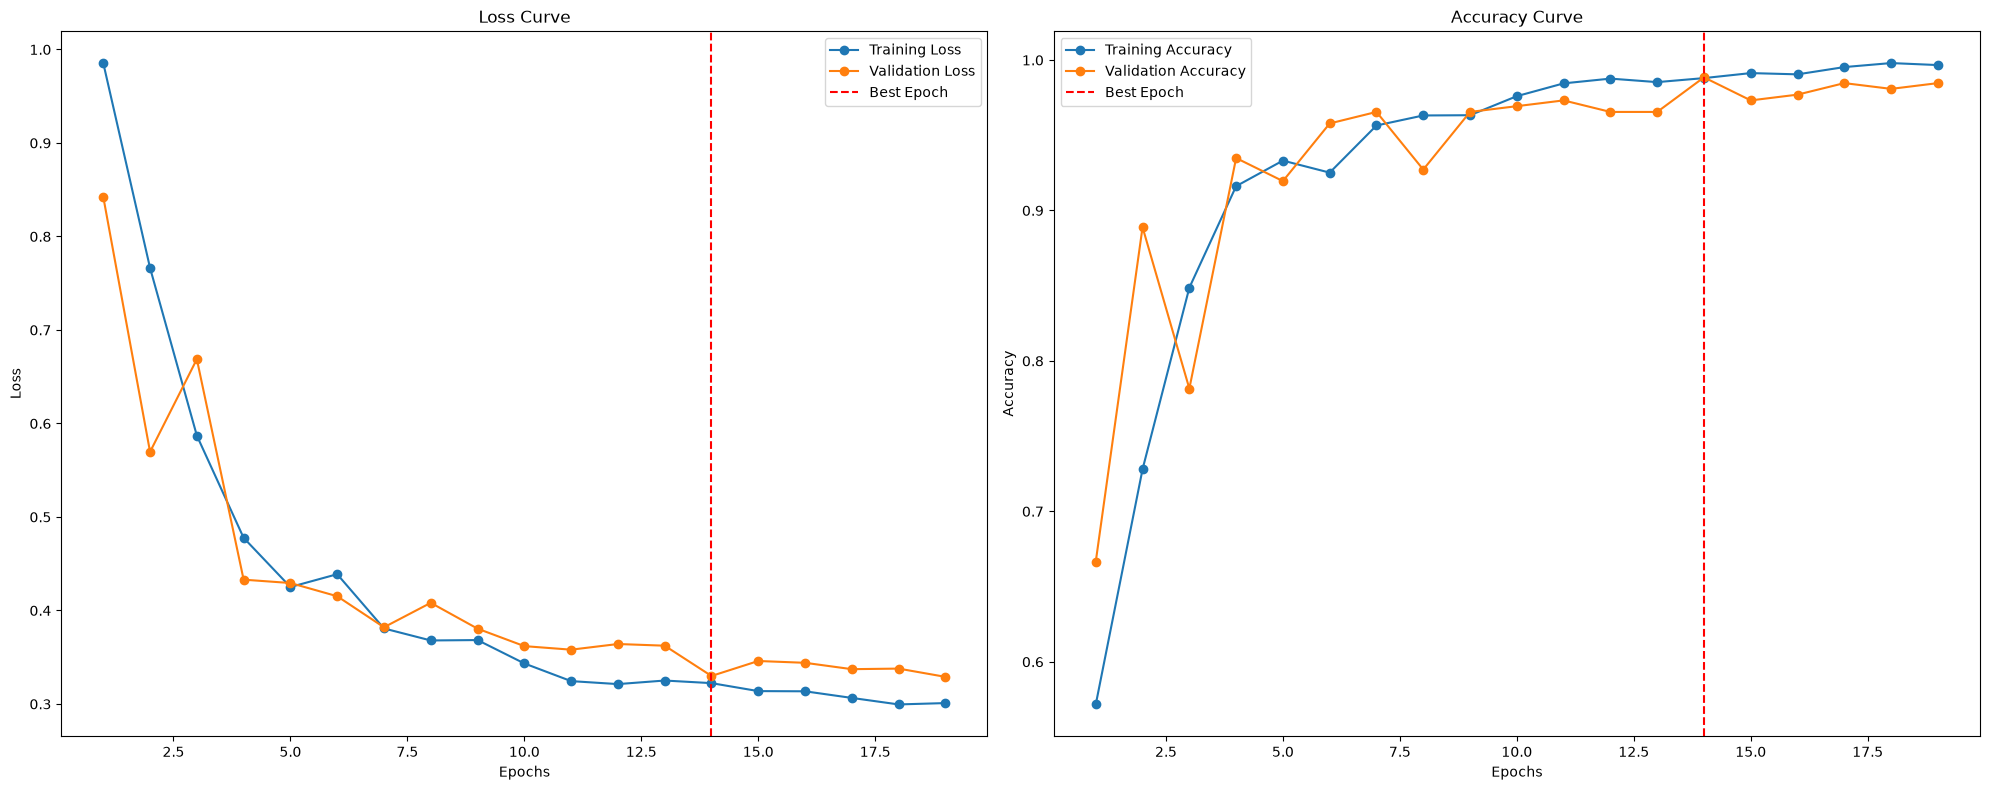


Training Report:
Total training time: 00:07:37
Total epochs run: 19
Best Training Loss: 0.3223 at epoch 14
Best Training Accuracy: 0.9880

Validation Report:
Best Validation Loss: 0.3299 at epoch 14
Best Validation Accuracy: 0.9885
Final Validation Loss: 0.3290
Final Validation Accuracy: 0.9847

Inference Report:
Total Inference Time (Validation only): 00:01:15


In [91]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [24]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98855
Recall:      0.98434
Precision:   0.98434
F1 Score:    0.98434
MCC:         0.97903
PR AUC:      0.99802
Kappa:       0.97903
Specificity: 0.99354


Accuracy: 0.9885
              precision    recall  f1-score   support

      Benign     0.9831    0.9831    0.9831        59
   Malignant     0.9938    0.9938    0.9938       161
      Normal     0.9762    0.9762    0.9762        42

    accuracy                         0.9885       262
   macro avg     0.9843    0.9843    0.9843       262
weighted avg     0.9885    0.9885    0.9885       262



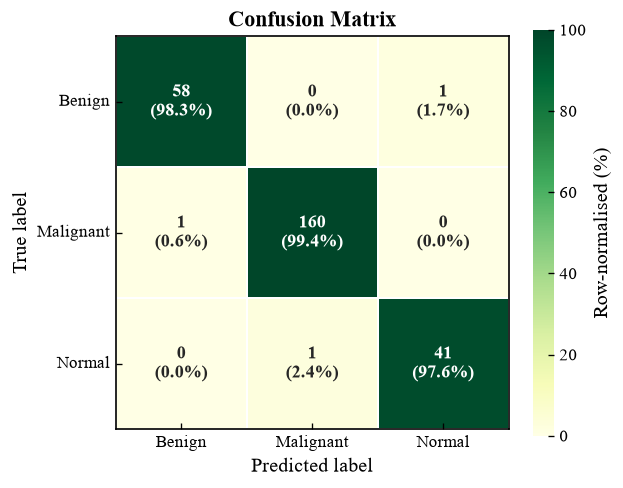

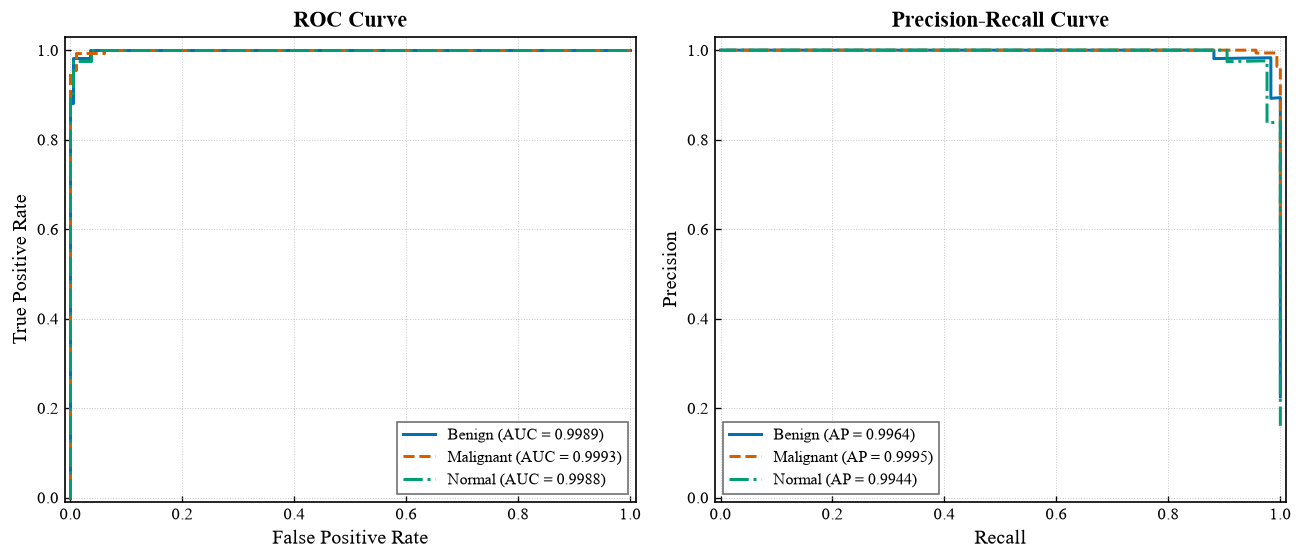

In [20]:
evaluate_model(model, test_loader, label_mapping, device=device, save_dir='figures', dpi=600)

In [25]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98855
Recall:      0.98434
Precision:   0.98434
F1 Score:    0.98434
MCC:         0.97903
PR AUC:      0.99802
Kappa:       0.97903
Specificity: 0.99354


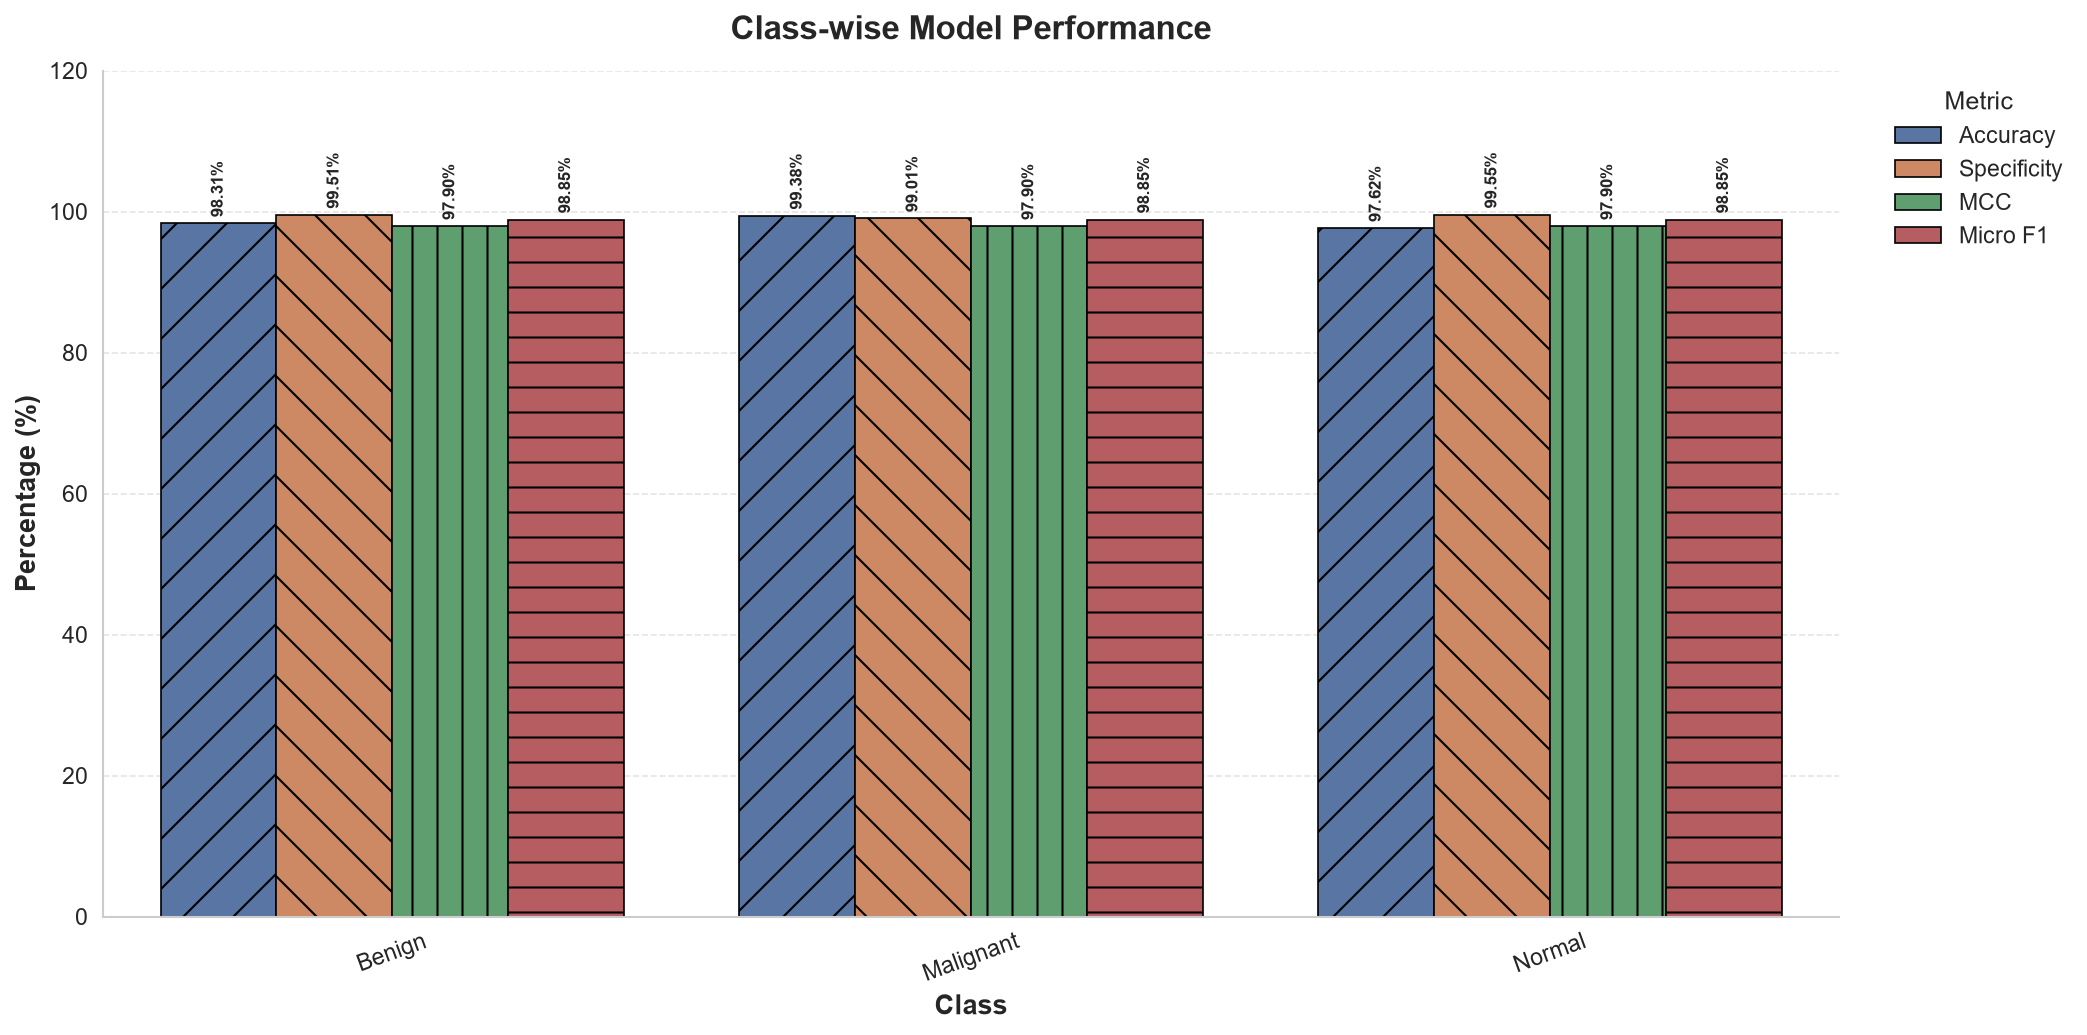

In [22]:
plot_model_performance(model, test_loader, label_mapping=label_mapping, device='cuda', save_path='class_performanceLung.png')

In [38]:
print(label_mapping)

{'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}


# Proposed Model's Uncertainty, Robustness and Misprediction Results

MC DROPOUT UNCERTAINTY ANALYSIS
[Diagnostic] Mean per-sample MC-pass disagreement rate: 0.03%
[Diagnostic] Samples with ANY disagreement across 30 passes: 0.38%
Accuracy: 0.98855 | Macro F1: 0.98434
ECE: 0.05856 | MCE: 0.43704 | Brier: 0.02995 | NLL: 0.10949
Mean predictive entropy: 0.29544 | Aleatoric: 0.29388 | Epistemic: 0.00156

TTA UNCERTAINTY ANALYSIS
Accuracy: 0.95038 | Macro F1: 0.93822
ECE: 0.12383 | MCE: 0.39936 | Brier: 0.10170 | NLL: 0.22612
Mean predictive entropy: 0.46505 | Aleatoric: 0.31492 | Epistemic: 0.15013

Saved: FetleSwinHybrid_uncertainty1_summary.csv


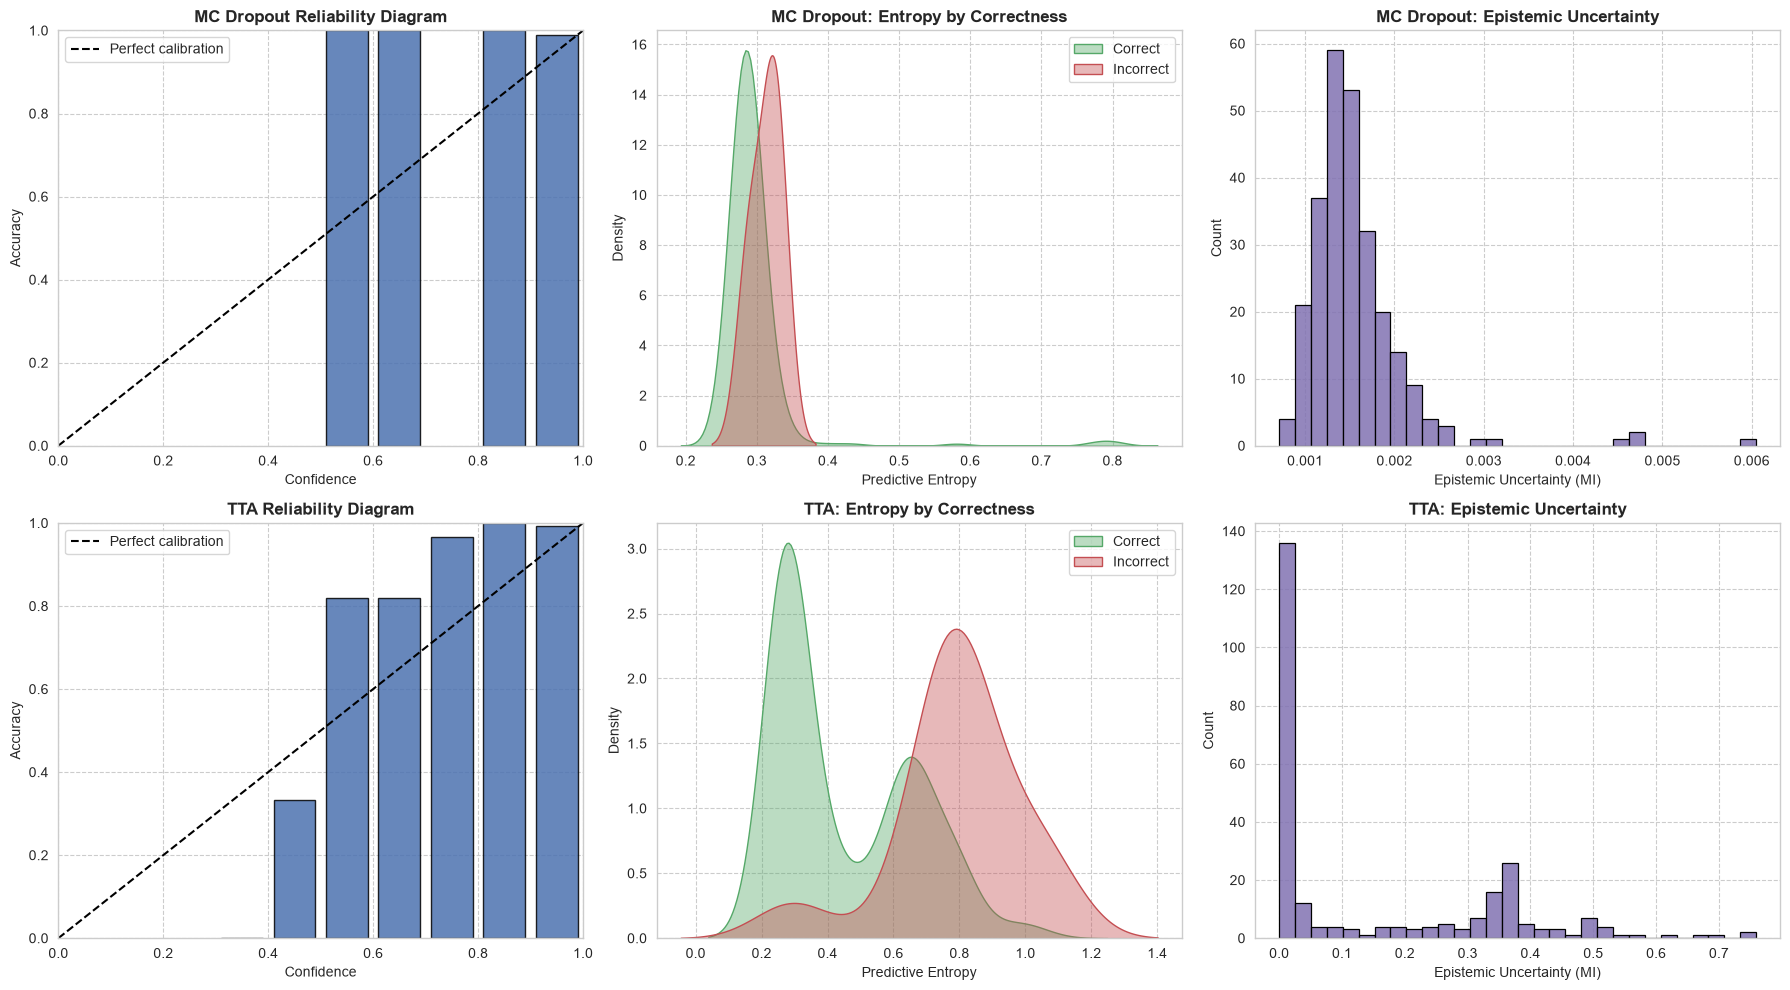

Saved: FetleSwinHybrid_uncertainty1_figures.png / .pdf


In [55]:
test_dataset.transform = data_transform  # fix corrupted state first

class_names = [k for k, v in sorted(label_mapping.items(), key=lambda x: x[1])]
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # confirm these match your data_transform

results = run_uncertainty_analysis(
    model=model,
    dataloader=test_loader,
    tta_dataset=test_dataset,
    device=device,
    class_names=class_names,
    mean=mean, std=std,
    mc_samples=30,
    save_prefix='FetleSwinHybrid_uncertainty1'
)

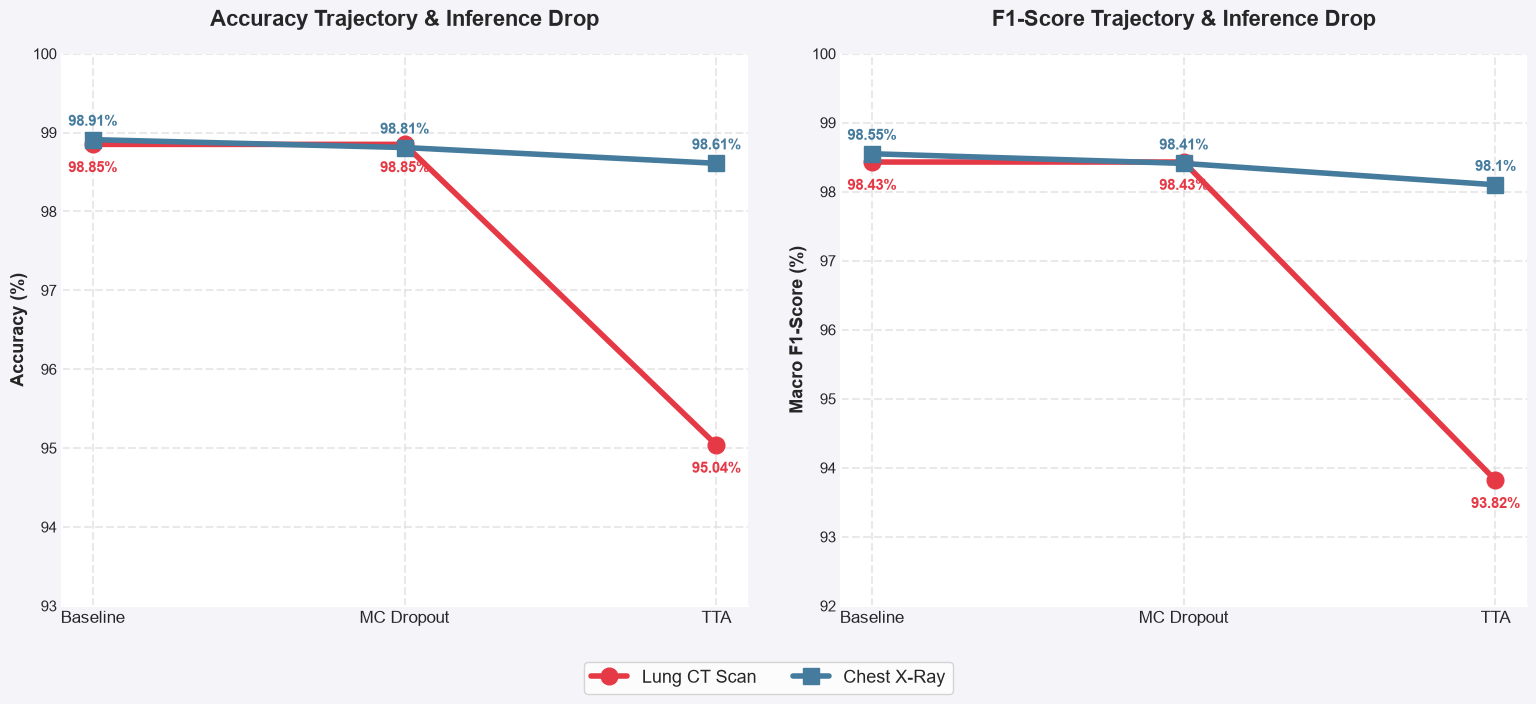

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# Performance Data
methods = ['Baseline', 'MC Dropout', 'TTA']

# Accuracy Data
lung_ct_acc = [98.85, 98.85, 95.04]
chest_xr_acc = [98.91, 98.81, 98.61]

# F1-Score Data
lung_ct_f1 = [98.43, 98.43, 93.82]
chest_xr_f1 = [98.55, 98.41, 98.10]

# Styling setup
plt.style.use('seaborn-v0_8-darkgrid')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), facecolor='#f4f4f9')

# Color palette (High contrast for visual impact)
color_lung = '#E63946'  # Bold Crimson for Lung CT (highlights the drop)
color_chest = '#457B9D' # Deep Steel Blue for Chest X-Ray (shows stability)

# ----------------- Subplot 1: Accuracy -----------------
ax1.plot(methods, lung_ct_acc, marker='o', markersize=12, linewidth=4, 
         color=color_lung, label='Lung CT Scan', zorder=3)
ax1.plot(methods, chest_xr_acc, marker='s', markersize=12, linewidth=4, 
         color=color_chest, label='Chest X-Ray', zorder=3)

ax1.set_title('Accuracy Trajectory & Inference Drop', fontsize=16, fontweight='bold', pad=20)
ax1.set_ylabel('Accuracy (%)', fontsize=13, fontweight='bold')
ax1.set_ylim(93, 100)
ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelsize=11)

# Annotations for Accuracy
for i, (l_val, c_val) in enumerate(zip(lung_ct_acc, chest_xr_acc)):
    ax1.annotate(f'{l_val}%', (i, l_val), textcoords="offset points", xytext=(0, -20), 
                 ha='center', fontsize=11, fontweight='bold', color=color_lung)
    ax1.annotate(f'{c_val}%', (i, c_val), textcoords="offset points", xytext=(0, 10), 
                 ha='center', fontsize=11, fontweight='bold', color=color_chest)

# ----------------- Subplot 2: Macro F1-Score -----------------
ax2.plot(methods, lung_ct_f1, marker='o', markersize=12, linewidth=4, 
         color=color_lung, label='Lung CT Scan', zorder=3)
ax2.plot(methods, chest_xr_f1, marker='s', markersize=12, linewidth=4, 
         color=color_chest, label='Chest X-Ray', zorder=3)

ax2.set_title('F1-Score Trajectory & Inference Drop', fontsize=16, fontweight='bold', pad=20)
ax2.set_ylabel('Macro F1-Score (%)', fontsize=13, fontweight='bold')
ax2.set_ylim(92, 100)
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=11)

# Annotations for F1-Score
for i, (l_val, c_val) in enumerate(zip(lung_ct_f1, chest_xr_f1)):
    ax2.annotate(f'{l_val}%', (i, l_val), textcoords="offset points", xytext=(0, -20), 
                 ha='center', fontsize=11, fontweight='bold', color=color_lung)
    ax2.annotate(f'{c_val}%', (i, c_val), textcoords="offset points", xytext=(0, 10), 
                 ha='center', fontsize=11, fontweight='bold', color=color_chest)

# Universal formatting
for ax in [ax1, ax2]:
    ax.set_facecolor('#ffffff')
    ax.grid(color='#e0e0e0', linestyle='--', linewidth=1.5, alpha=0.7)
    # Remove top and right spines for a cleaner look
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.5)
    ax.spines['bottom'].set_linewidth(1.5)

# Unified Legend
handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=13, 
           bbox_to_anchor=(0.5, -0.05), frameon=True, facecolor='#ffffff', edgecolor='#cccccc')

plt.tight_layout(pad=3.0)
plt.savefig('comparisonUncertainty.png', dpi=600, bbox_inches='tight')
plt.show()

CLINICALLY-REALISTIC CORRUPTION ROBUSTNESS
Clean                | Acc=0.9885 | F1=0.9843 | MCC=0.9790
Gaussian Noise       | sev=1 | Acc=0.9847 | F1=0.9795 | MCC=0.9722
Gaussian Noise       | sev=2 | Acc=0.9847 | F1=0.9795 | MCC=0.9722
Gaussian Noise       | sev=3 | Acc=0.9809 | F1=0.9757 | MCC=0.9653
Gaussian Noise       | sev=4 | Acc=0.9809 | F1=0.9728 | MCC=0.9653
Gaussian Blur        | sev=1 | Acc=0.9771 | F1=0.9729 | MCC=0.9582
Gaussian Blur        | sev=2 | Acc=0.9427 | F1=0.9217 | MCC=0.8945
Gaussian Blur        | sev=3 | Acc=0.8321 | F1=0.6822 | MCC=0.6872
Gaussian Blur        | sev=4 | Acc=0.7710 | F1=0.5576 | MCC=0.5586
Brightness Shift     | sev=1 | Acc=0.9771 | F1=0.9696 | MCC=0.9580
Brightness Shift     | sev=2 | Acc=0.9771 | F1=0.9729 | MCC=0.9582
Brightness Shift     | sev=3 | Acc=0.9733 | F1=0.9674 | MCC=0.9511
Brightness Shift     | sev=4 | Acc=0.9618 | F1=0.9522 | MCC=0.9300
JPEG Compression     | sev=1 | Acc=0.9885 | F1=0.9843 | MCC=0.9790
JPEG Compression     | sev=

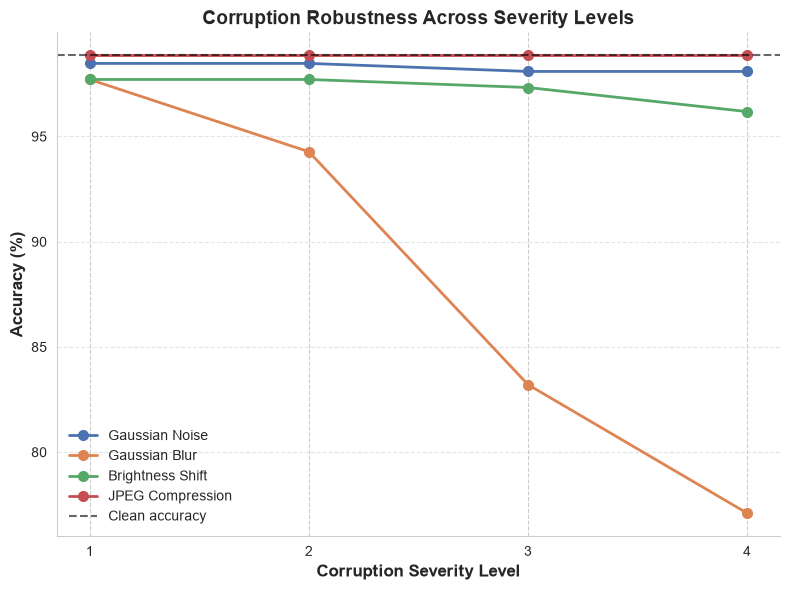

Saved figure: FetleSwinHybrid_corruption_figure.png / .pdf


In [35]:
# ============================================================
# USAGE
# ============================================================
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # match your data_transform exactly

summary_df, per_severity_df = run_corruption_analysis(
     model=model,
     dataset=test_dataset,     # your CustomImageDataset instance
     device=device,
     mean=mean, std=std,
     save_prefix='FetleSwinHybrid_corruption'
)

In [23]:
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score, 
    matthews_corrcoef, average_precision_score, cohen_kappa_score, confusion_matrix
)
from sklearn.preprocessing import label_binarize
from sklearn.manifold import TSNE
import matplotlib.gridspec as gridspec
import numpy as np
import torch
class_names = [k for k, v in sorted(label_mapping.items(), key=lambda x: x[1])]

def evaluate_model_with_metrics_and_separate_plots(
    model, dataloader, device, class_names=class_names):
    model.eval()
    all_labels, all_preds, all_probs, all_confs, all_features = [], [], [], [], []
    misclassified_imgs, misclassified_trues, misclassified_preds, misclassified_confs = [], [], [], []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            
            probs = torch.softmax(outputs, dim=1)
            confs, preds = torch.max(probs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())
            all_confs.extend(confs.cpu().numpy())
            all_features.extend(outputs.cpu().numpy())

            # Collect up to 3 misclassified samples
            batch_labels = labels.cpu().numpy()
            batch_preds = preds.cpu().numpy()
            batch_confs = confs.cpu().numpy()
            batch_inputs = inputs.cpu().numpy()
            
            for i in range(len(batch_labels)):
                if batch_labels[i] != batch_preds[i] and len(misclassified_imgs) < 3:
                    misclassified_imgs.append(batch_inputs[i])
                    misclassified_trues.append(batch_labels[i])
                    misclassified_preds.append(batch_preds[i])
                    misclassified_confs.append(batch_confs[i])

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)
    all_confs = np.array(all_confs)
    all_features = np.array(all_features)

    # ---------------------------------------------------------
    # 1. Base Metrics Computation
    # ---------------------------------------------------------
    accuracy = accuracy_score(all_labels, all_preds)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    mcc = matthews_corrcoef(all_labels, all_preds)
    kappa = cohen_kappa_score(all_labels, all_preds)

    try:
        n_classes = len(class_names)
        y_onehot = label_binarize(all_labels, classes=list(range(n_classes)))
        pr_auc = average_precision_score(y_onehot, all_probs, average="weighted")
    except Exception:
        pr_auc = float('nan')

    cm = confusion_matrix(all_labels, all_preds)
    specificity_per_class = []
    for i in range(len(cm)):
        tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
        fp = cm[:, i].sum() - cm[i, i]
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificity_per_class.append(spec)
    specificity = np.average(specificity_per_class)

    print(f"Accuracy:    {accuracy:.5f}")
    print(f"Recall:      {recall:.5f}")
    print(f"Precision:   {precision:.5f}")
    print(f"F1 Score:    {f1:.5f}")
    print(f"MCC:         {mcc:.5f}")
    print(f"PR AUC:      {pr_auc:.5f}")
    print(f"Kappa:       {kappa:.5f}")
    print(f"Specificity: {specificity:.5f}")

    correct_mask = (all_labels == all_preds)
    misclassified_mask = (all_labels != all_preds)

    # ---------------------------------------------------------
    # 2. Figure 1: Misclassified Images Grid (600 DPI)
    # ---------------------------------------------------------
    if len(misclassified_imgs) > 0:
        fig1, axes = plt.subplots(1, len(misclassified_imgs), figsize=(4 * len(misclassified_imgs), 4))
        if len(misclassified_imgs) == 1:
            axes = [axes]
            
        for i, ax in enumerate(axes):
            img = misclassified_imgs[i]
            if img.ndim == 3 and img.shape[0] in [1, 3]:
                img = np.transpose(img, (1, 2, 0))
            img = (img - img.min()) / (img.max() - img.min() + 1e-8)
            
            ax.imshow(img.squeeze(), cmap='gray' if (img.ndim == 2 or img.shape[-1] == 1) else None)
            t_class = class_names[misclassified_trues[i]]
            p_class = class_names[misclassified_preds[i]]
            conf = misclassified_confs[i]
            
            ax.set_title(f"True: {t_class}\nPred: {p_class}\nConf: {conf:.4f}", fontsize=10, fontweight='bold')
            ax.axis('off')
            
        plt.tight_layout()
        plt.savefig('misclassified_images.png', dpi=600, bbox_inches='tight')
        plt.show()

    # ---------------------------------------------------------
    # 3. Figure 2: Prediction Confidence Boxplot (600 DPI)
    # ---------------------------------------------------------
    fig2, ax_box = plt.subplots(figsize=(6, 5))
    correct_confs = all_confs[correct_mask]
    misclass_confs = all_confs[misclassified_mask]
    
    data_to_plot = [correct_confs]
    tick_labels = ['Correct']
    if len(misclass_confs) > 0:
        data_to_plot.append(misclass_confs)
        tick_labels.append('Misclassified')
        
    ax_box.boxplot(data_to_plot, showmeans=True)
    ax_box.set_xticks(range(1, len(tick_labels) + 1))
    ax_box.set_xticklabels(tick_labels, fontweight='bold')
    ax_box.set_title('Prediction Confidence: Correct vs Misclassified Images', fontsize=11, fontweight='bold')
    ax_box.set_ylabel('Prediction Confidence')
    ax_box.grid(True, axis='y', linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig('prediction_confidence_boxplot.png', dpi=600, bbox_inches='tight')
    plt.show()

    # ---------------------------------------------------------
    # 4. Figure 3: t-SNE Feature Space Scatter Plot (600 DPI)
    # ---------------------------------------------------------
    fig3, ax_tsne = plt.subplots(figsize=(6.5, 5))
    tsne = TSNE(n_components=2, random_state=42, perplexity=min(30, max(5, len(all_features) - 1)))
    tsne_results = tsne.fit_transform(all_features)
    
    ax_tsne.scatter(
        tsne_results[correct_mask, 0], tsne_results[correct_mask, 1], 
        alpha=0.6, label='Correct', marker='o', edgecolors='none', s=25
    )
    if np.any(misclassified_mask):
        ax_tsne.scatter(
            tsne_results[misclassified_mask, 0], tsne_results[misclassified_mask, 1], 
            alpha=0.9, label='Misclassified', marker='x', color='red', s=40
        )
    
    ax_tsne.set_title('t-SNE Feature Space: Correct vs Misclassified Predictions', fontsize=11, fontweight='bold')
    ax_tsne.set_xlabel('t-SNE Dimension 1')
    ax_tsne.set_ylabel('t-SNE Dimension 2')
    ax_tsne.legend()
    ax_tsne.grid(True, linestyle='--', alpha=0.5)
    
    plt.tight_layout()
    plt.savefig('tsne_feature_space.png', dpi=600, bbox_inches='tight')
    plt.show()

Accuracy:    0.98855
Recall:      0.98434
Precision:   0.98434
F1 Score:    0.98434
MCC:         0.97903
PR AUC:      0.99802
Kappa:       0.97903
Specificity: 0.99354


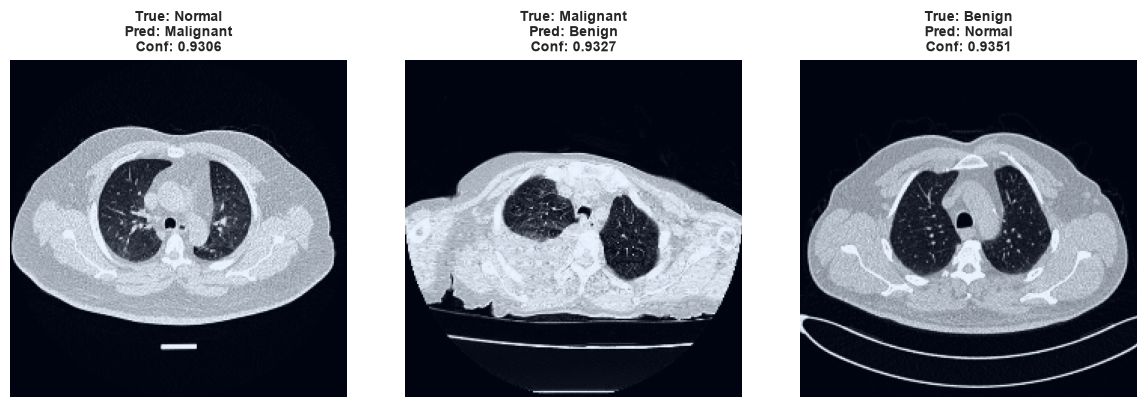

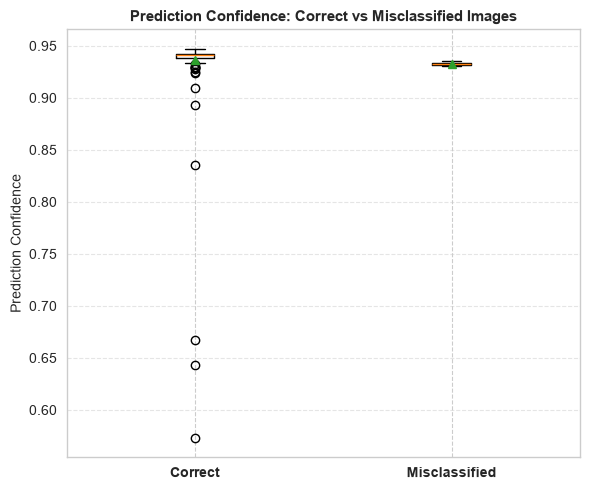

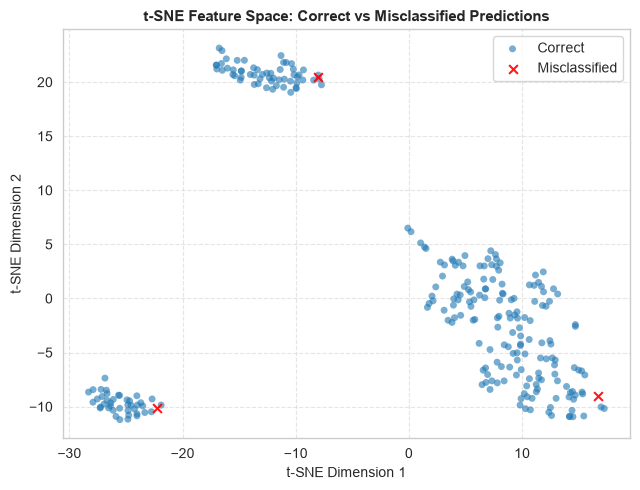

In [24]:
evaluate_model_with_metrics_and_separate_plots(model, test_loader, device, class_names=class_names)

# Ablation Study Result


 Starting Experiment: w/o FETLE Module

Epoch 1/30
------------------------------


Validation Loss: 0.8742, Validation Accuracy: 0.6475
Training Loss: 0.9470, Training Accuracy: 0.5825

Epoch 2/30
------------------------------


Validation Loss: 0.6760, Validation Accuracy: 0.7433
Training Loss: 0.6841, Training Accuracy: 0.7768

Epoch 3/30
------------------------------


Validation Loss: 0.4098, Validation Accuracy: 0.9349
Training Loss: 0.4978, Training Accuracy: 0.9018

Epoch 4/30
------------------------------


Validation Loss: 0.4889, Validation Accuracy: 0.9080
Training Loss: 0.4043, Training Accuracy: 0.9538
Patience Counter: 1/5

Epoch 5/30
------------------------------


Validation Loss: 0.4162, Validation Accuracy: 0.9310
Training Loss: 0.4138, Training Accuracy: 0.9400
Patience Counter: 2/5

Epoch 6/30
------------------------------


... (16 outputs left out)

Validation Loss: 0.3312, Validation Accuracy: 0.9847
Training Loss: 0.2963, Training Accuracy: 0.9993
Patience Counter: 2/5

Epoch 23/30
------------------------------


Validation Loss: 0.3301, Validation Accuracy: 0.9847
Training Loss: 0.2966, Training Accuracy: 0.9987
Patience Counter: 3/5

Epoch 24/30
------------------------------


Validation Loss: 0.3269, Validation Accuracy: 0.9847
Training Loss: 0.2963, Training Accuracy: 0.9990
Patience Counter: 4/5

Epoch 25/30
------------------------------


Validation Loss: 0.3274, Validation Accuracy: 0.9847
Training Loss: 0.2960, Training Accuracy: 0.9990
Patience Counter: 5/5
Early stopping triggered at epoch 25.


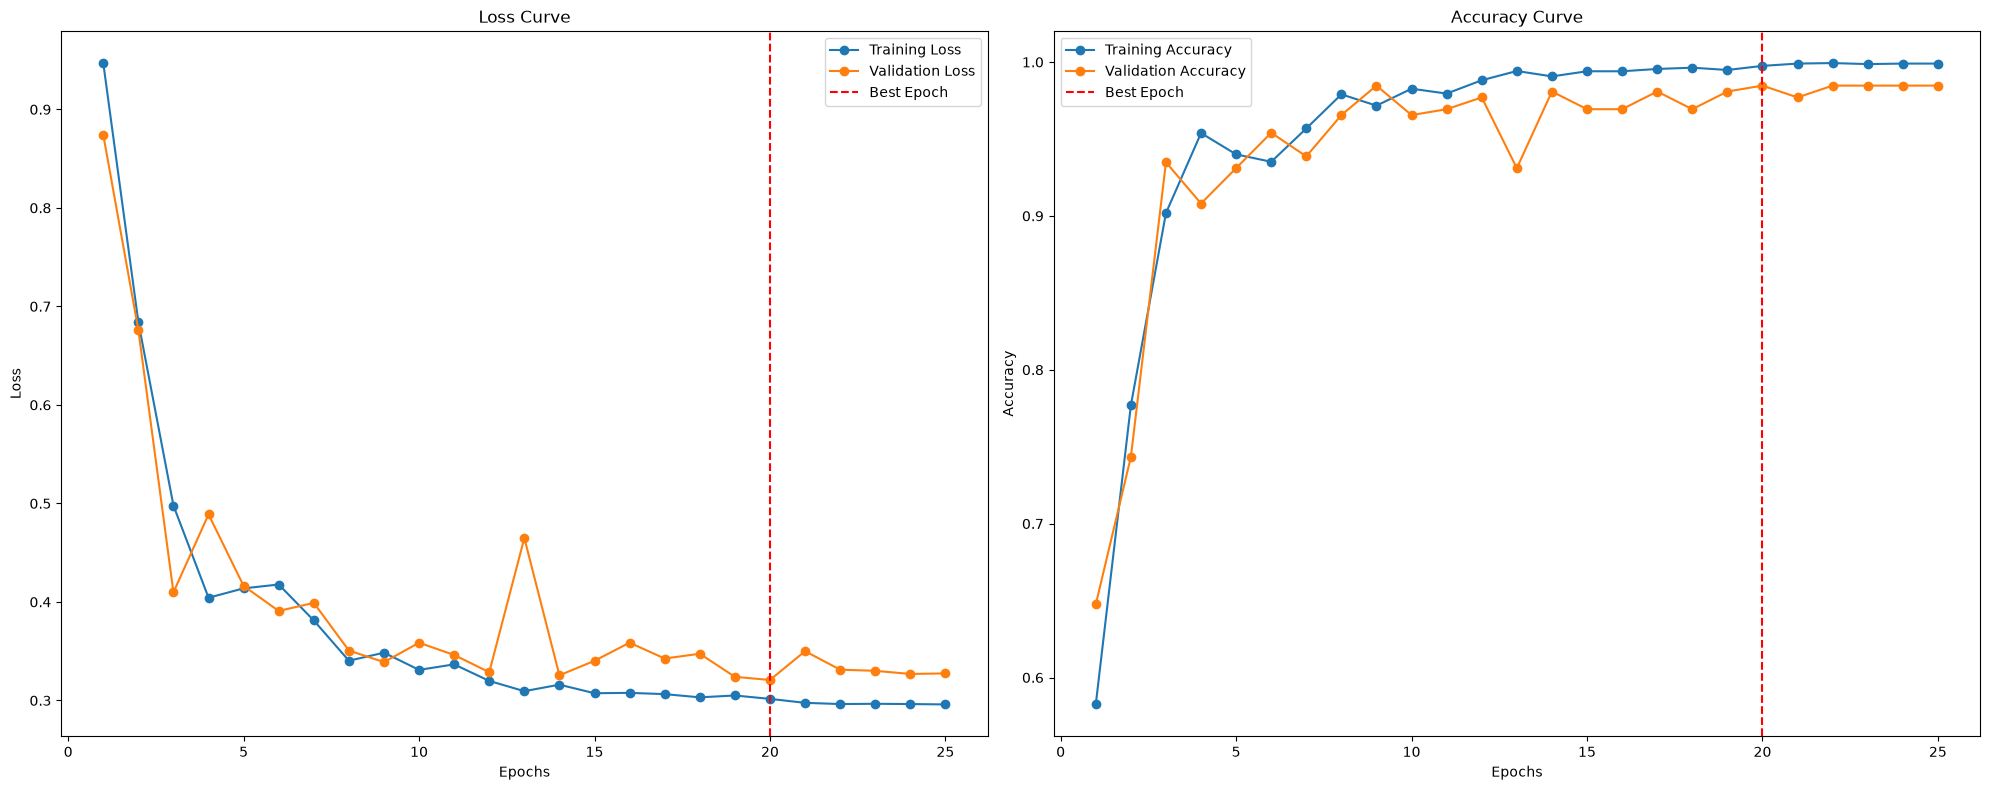


Training Report:
Total training time: 00:08:10
Total epochs run: 25
Best Training Loss: 0.3016 at epoch 20
Best Training Accuracy: 0.9975

Validation Report:
Best Validation Loss: 0.3208 at epoch 20
Best Validation Accuracy: 0.9847
Final Validation Loss: 0.3274
Final Validation Accuracy: 0.9847

Inference Report:
Total Inference Time (Validation only): 00:01:36

--- Test Evaluation: w/o FETLE Module ---
Accuracy:    0.98473
Recall:      0.97869
Precision:   0.98220
F1 Score:    0.98042
MCC:         0.97199
PR AUC:      0.99543
Kappa:       0.97196
Specificity: 0.99024

 Starting Experiment: w/o AMSFA Module

Epoch 1/30
------------------------------


Validation Loss: 0.8300, Validation Accuracy: 0.6552
Training Loss: 0.8955, Training Accuracy: 0.6328

Epoch 2/30
------------------------------


Validation Loss: 0.5042, Validation Accuracy: 0.9042
Training Loss: 0.6907, Training Accuracy: 0.7682

Epoch 3/30
------------------------------


Validation Loss: 0.4587, Validation Accuracy: 0.9272
Training Loss: 0.5313, Training Accuracy: 0.8772

Epoch 4/30
------------------------------


Validation Loss: 0.4112, Validation Accuracy: 0.9425
Training Loss: 0.4535, Training Accuracy: 0.9242

Epoch 5/30
------------------------------


Validation Loss: 0.3824, Validation Accuracy: 0.9502
Training Loss: 0.4102, Training Accuracy: 0.9513

Epoch 6/30
------------------------------


... (18 outputs left out)

Validation Loss: 0.3327, Validation Accuracy: 0.9770
Training Loss: 0.2963, Training Accuracy: 0.9988
Patience Counter: 2/5

Epoch 25/30
------------------------------


Validation Loss: 0.3313, Validation Accuracy: 0.9770
Training Loss: 0.2955, Training Accuracy: 0.9992
Patience Counter: 3/5

Epoch 26/30
------------------------------


Validation Loss: 0.3316, Validation Accuracy: 0.9808
Training Loss: 0.2959, Training Accuracy: 0.9992
Patience Counter: 4/5

Epoch 27/30
------------------------------


Validation Loss: 0.3301, Validation Accuracy: 0.9847
Training Loss: 0.2955, Training Accuracy: 0.9990
Patience Counter: 5/5
Early stopping triggered at epoch 27.


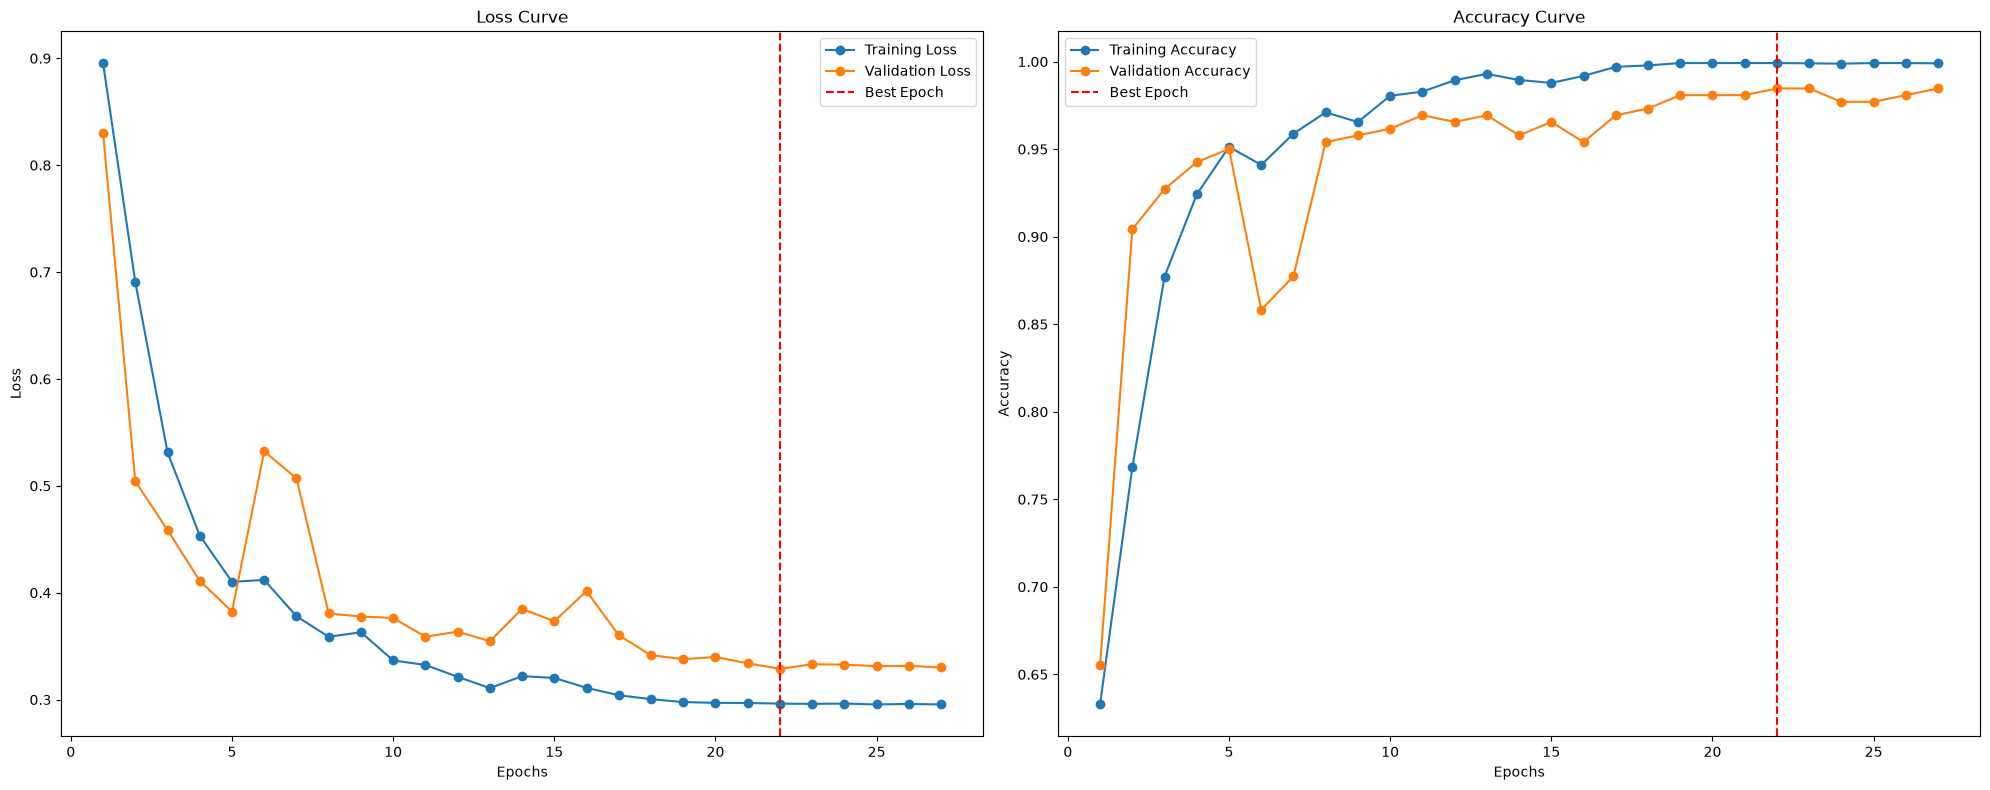


Training Report:
Total training time: 00:08:54
Total epochs run: 27
Best Training Loss: 0.2962 at epoch 22
Best Training Accuracy: 0.9992

Validation Report:
Best Validation Loss: 0.3287 at epoch 22
Best Validation Accuracy: 0.9847
Final Validation Loss: 0.3301
Final Validation Accuracy: 0.9847

Inference Report:
Total Inference Time (Validation only): 00:01:46

--- Test Evaluation: w/o AMSFA Module ---
Accuracy:    0.98092
Recall:      0.97304
Precision:   0.97645
F1 Score:    0.97472
MCC:         0.96498
PR AUC:      0.98328
Kappa:       0.96495
Specificity: 0.98860

 Starting Experiment: Baseline (w/o FETLE & AMSFA)

Epoch 1/30
------------------------------


Validation Loss: 0.7778, Validation Accuracy: 0.7203
Training Loss: 0.8934, Training Accuracy: 0.6352

Epoch 2/30
------------------------------


Validation Loss: 0.4457, Validation Accuracy: 0.9157
Training Loss: 0.6699, Training Accuracy: 0.7895

Epoch 3/30
------------------------------


Validation Loss: 0.4232, Validation Accuracy: 0.9425
Training Loss: 0.5148, Training Accuracy: 0.8892

Epoch 4/30
------------------------------


Validation Loss: 0.5574, Validation Accuracy: 0.8621
Training Loss: 0.4441, Training Accuracy: 0.9335
Patience Counter: 1/5

Epoch 5/30
------------------------------


Validation Loss: 0.7062, Validation Accuracy: 0.8123
Training Loss: 0.4165, Training Accuracy: 0.9435
Patience Counter: 2/5

Epoch 6/30
------------------------------


... (14 outputs left out)

Validation Loss: 0.3646, Validation Accuracy: 0.9693
Training Loss: 0.3010, Training Accuracy: 0.9977
Patience Counter: 2/5

Epoch 21/30
------------------------------


Validation Loss: 0.3607, Validation Accuracy: 0.9732
Training Loss: 0.2985, Training Accuracy: 0.9985
Patience Counter: 3/5

Epoch 22/30
------------------------------


Validation Loss: 0.3707, Validation Accuracy: 0.9655
Training Loss: 0.2972, Training Accuracy: 0.9990
Patience Counter: 4/5

Epoch 23/30
------------------------------


Validation Loss: 0.3650, Validation Accuracy: 0.9693
Training Loss: 0.2960, Training Accuracy: 0.9993
Patience Counter: 5/5
Early stopping triggered at epoch 23.


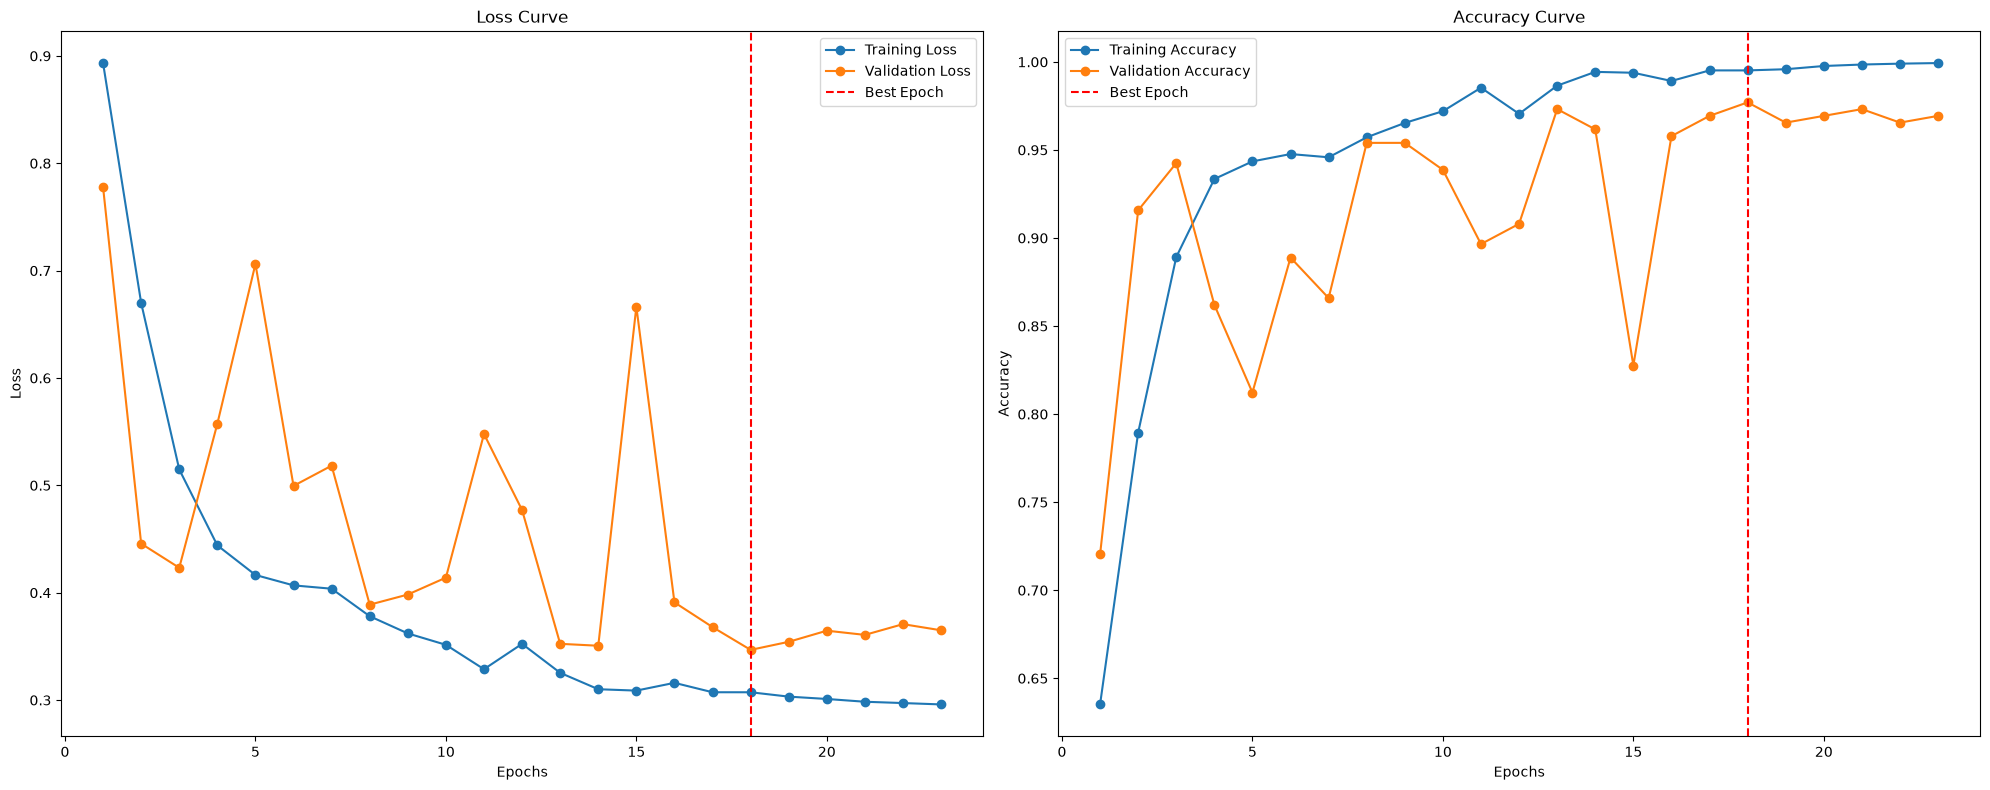


Training Report:
Total training time: 00:07:16
Total epochs run: 23
Best Training Loss: 0.3073 at epoch 18
Best Training Accuracy: 0.9952

Validation Report:
Best Validation Loss: 0.3468 at epoch 18
Best Validation Accuracy: 0.9770
Final Validation Loss: 0.3650
Final Validation Accuracy: 0.9693

Inference Report:
Total Inference Time (Validation only): 00:01:30

--- Test Evaluation: Baseline (w/o FETLE & AMSFA) ---
Accuracy:    0.97710
Recall:      0.96739
Precision:   0.96868
F1 Score:    0.96790
MCC:         0.95804
PR AUC:      0.99748
Kappa:       0.95796
Specificity: 0.98708

               FINAL ABLATION STUDY RESULTS             
               Model Variant  Accuracy   Recall  Precision  F1 Score     MCC   PR AUC    Kappa  Specificity
            w/o FETLE Module  0.984733 0.978694   0.982201  0.980421 0.97199 0.995429 0.971961     0.990242
            w/o AMSFA Module  0.980916 0.973044   0.976454  0.974723 0.96498 0.983283 0.964951     0.988600
Baseline (w/o FETLE & AMSFA)  

In [30]:
num_classes = len(label_mapping)
df_results = run_full_ablation_study(
     train_loader, val_loader, test_loader, 
     num_classes=num_classes, device=device, 
     num_epochs=30, warmup_epochs=5
)

In [31]:
def count_parameters(model):
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total_params = sum(p.numel() for p in model.parameters())
    return trainable_params, total_params

def get_ablation_parameter_counts(num_classes=3):
    variants = {
        "Proposed Model (Full)":         {"use_fetle": True,  "use_amsfa": True},
        "w/o FETLE Module":              {"use_fetle": False, "use_amsfa": True},
        "w/o AMSFA Module":              {"use_fetle": True,  "use_amsfa": False},
        "Baseline (w/o FETLE & AMSFA)": {"use_fetle": False, "use_amsfa": False},
    }

    param_summary = []

    for name, flags in variants.items():
        # Instantiate variant without moving to GPU to quickly measure parameter sizes
        model = FetleSwinHybridAblation(
            num_classes=num_classes,
            use_fetle=flags["use_fetle"],
            use_amsfa=flags["use_amsfa"]
        )
        
        trainable, total = count_parameters(model)
        
        param_summary.append({
            "Model Variant": name,
            "Trainable Params": f"{trainable:,}",
            "Trainable (M)": f"{trainable / 1e6:.3f} M",
            "Total (M)": f"{total / 1e6:.3f} M"
        })

    df_params = pd.DataFrame(param_summary)
    return df_params

# Execute count script
df_param_counts = get_ablation_parameter_counts(num_classes=3)
print(df_param_counts.to_string(index=False))

               Model Variant Trainable Params Trainable (M) Total (M)
       Proposed Model (Full)        2,811,225       2.811 M   2.811 M
            w/o FETLE Module        2,808,193       2.808 M   2.808 M
            w/o AMSFA Module        3,047,405       3.047 M   3.047 M
Baseline (w/o FETLE & AMSFA)        3,044,373       3.044 M   3.044 M


In [20]:
model.load_state_dict(torch.load("fetle_swin_hybrid_model.pth"))

<All keys matched successfully>

In [28]:
torch.cuda.empty_cache()

# Cross-Validation Result of FeLASwin-Net

Full dataset: 2614 images across 3 classes
Running 5-fold CV on the entire dataset (no held-out test set)

FOLD 2/5  (train=2091, val=523)

Processing class: Bengin cases
Original images saved: 469


 81%|████████▏ | 382/469 [00:22<00:05, 17.35it/s]


Augmented images created: 1531
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1289


 55%|█████▌    | 710/1289 [00:10<00:08, 69.56it/s] 


Augmented images created: 711
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:26<00:05, 10.42it/s]


... (20 outputs left out)

Validation Loss: 0.3640, Validation Accuracy: 0.9637
Training Loss: 0.3007, Training Accuracy: 0.9982
Patience Counter: 4/7

Epoch 21/30
------------------------------


Validation Loss: 0.3674, Validation Accuracy: 0.9675
Training Loss: 0.2973, Training Accuracy: 0.9993
Patience Counter: 5/7

Epoch 22/30
------------------------------


Validation Loss: 0.3780, Validation Accuracy: 0.9618
Training Loss: 0.2959, Training Accuracy: 0.9997
Patience Counter: 6/7

Epoch 23/30
------------------------------


Validation Loss: 0.3643, Validation Accuracy: 0.9713
Training Loss: 0.2957, Training Accuracy: 0.9997
Patience Counter: 7/7
Early stopping triggered at epoch 23.


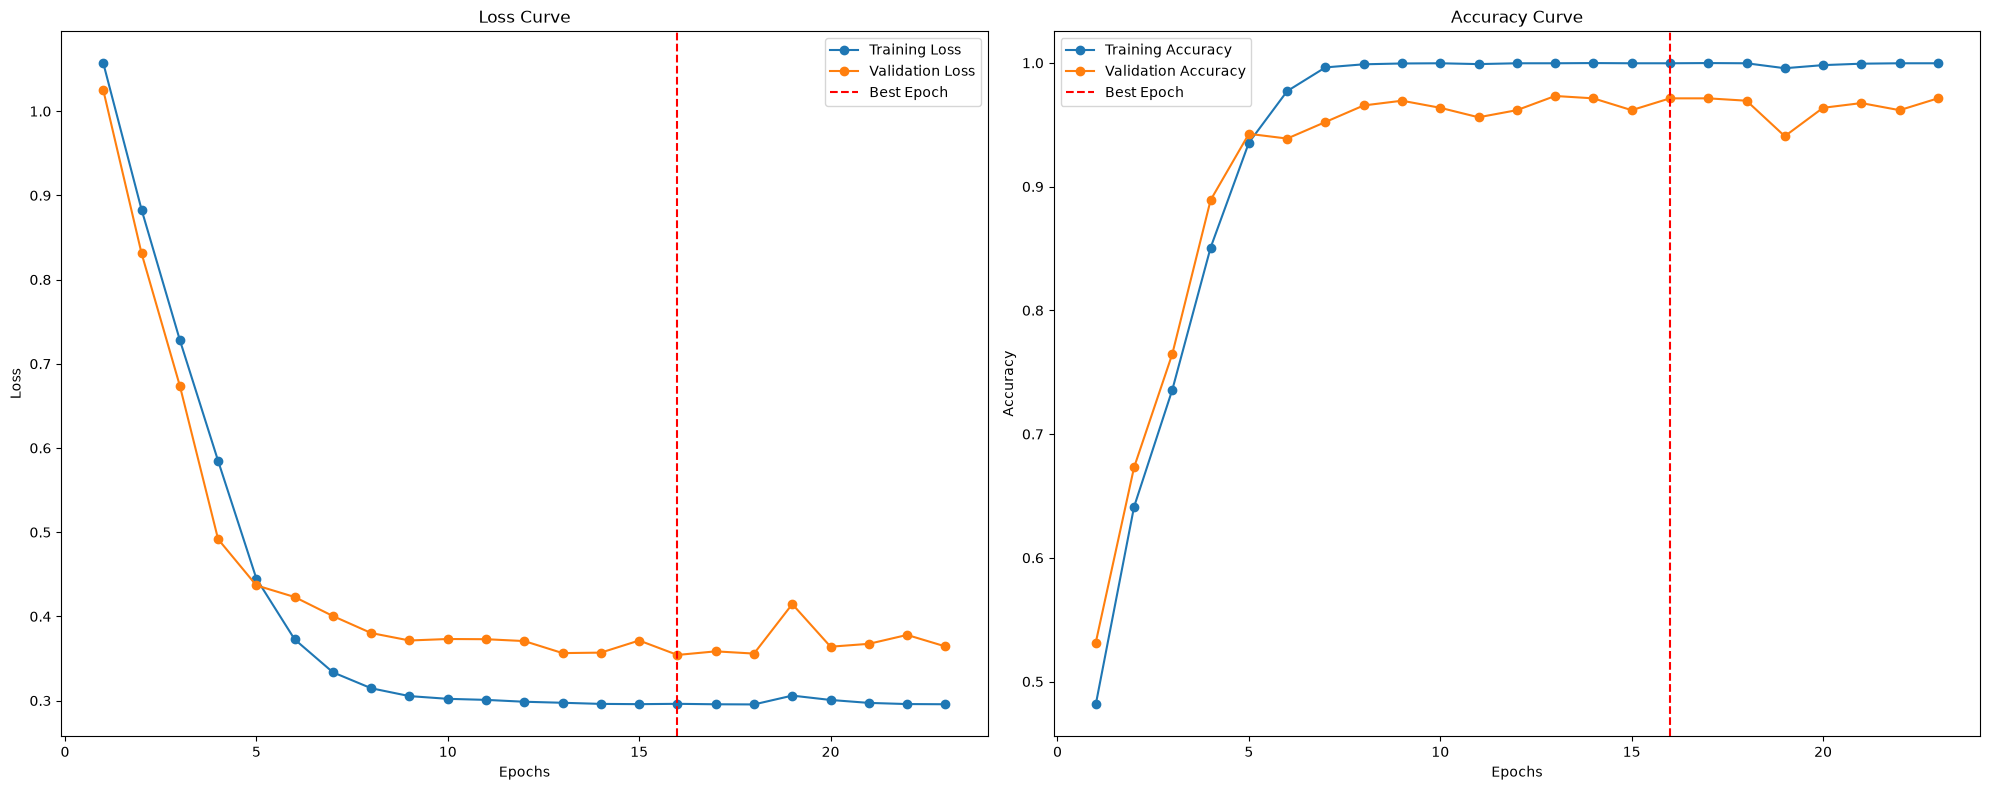


Training Report:
Total training time: 00:07:51
Total epochs run: 23
Best Training Loss: 0.2962 at epoch 16
Best Training Accuracy: 0.9997

Validation Report:
Best Validation Loss: 0.3542 at epoch 16
Best Validation Accuracy: 0.9713
Final Validation Loss: 0.3643
Final Validation Accuracy: 0.9713

Inference Report:
Total Inference Time (Validation only): 00:01:33
Accuracy:    0.97132
Recall:      0.97552
Precision:   0.96764
F1 Score:    0.97143
MCC:         0.94790
PR AUC:      0.98421
Kappa:       0.94772
Specificity: 0.98348
Saved fold 2 checkpoint -> model_fold2.pth

FOLD 3/5  (train=2091, val=523)

Processing class: Bengin cases
Original images saved: 470


 81%|████████▏ | 382/470 [00:24<00:05, 15.69it/s]


Augmented images created: 1530
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1288


 55%|█████▌    | 711/1288 [00:10<00:08, 66.20it/s] 


Augmented images created: 712
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:26<00:05, 10.43it/s]


... (20 outputs left out)

Validation Loss: 0.3375, Validation Accuracy: 0.9732
Training Loss: 0.2955, Training Accuracy: 0.9995
Patience Counter: 4/7

Epoch 21/30
------------------------------


Validation Loss: 0.3430, Validation Accuracy: 0.9732
Training Loss: 0.2958, Training Accuracy: 0.9993
Patience Counter: 5/7

Epoch 22/30
------------------------------


Validation Loss: 0.3377, Validation Accuracy: 0.9771
Training Loss: 0.2954, Training Accuracy: 0.9995
Patience Counter: 6/7

Epoch 23/30
------------------------------


Validation Loss: 0.3367, Validation Accuracy: 0.9771
Training Loss: 0.2951, Training Accuracy: 0.9995
Patience Counter: 7/7
Early stopping triggered at epoch 23.


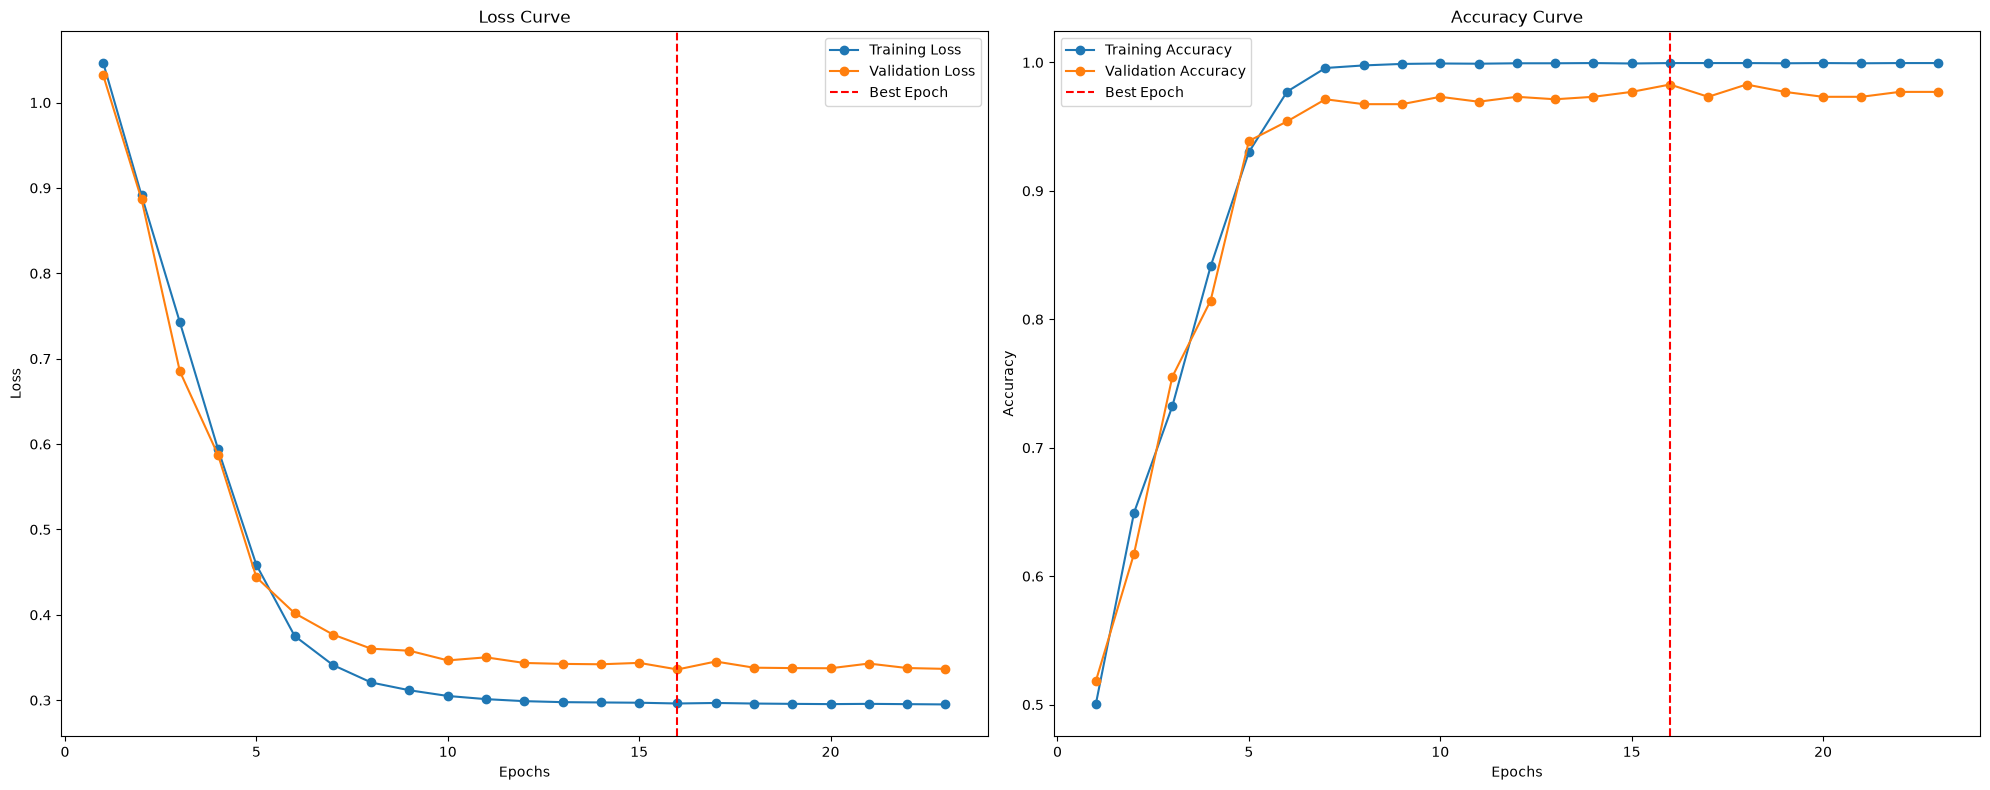


Training Report:
Total training time: 00:07:53
Total epochs run: 23
Best Training Loss: 0.2962 at epoch 16
Best Training Accuracy: 0.9995

Validation Report:
Best Validation Loss: 0.3361 at epoch 16
Best Validation Accuracy: 0.9828
Final Validation Loss: 0.3367
Final Validation Accuracy: 0.9771

Inference Report:
Total Inference Time (Validation only): 00:01:33
Accuracy:    0.97706
Recall:      0.97671
Precision:   0.97261
F1 Score:    0.97461
MCC:         0.95787
PR AUC:      0.99214
Kappa:       0.95785
Specificity: 0.98605
Saved fold 3 checkpoint -> model_fold3.pth


In [25]:
import os
import gc
import shutil
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR
from torch.utils.data import DataLoader
from sklearn.model_selection import StratifiedKFold

# Ensure to import FetleSwinHybrid, evaluate_model_with_metrics, 
# offline_augment_train, loading_the_data, data_transform, and train_model from your modules
from my_dataset import CustomImageDataset

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS            = 5
TARGET_PER_CLASS   = 2000
RANDOM_STATE       = 42
BASE_AUG_DIR       = "D:\\lung cancer dataset\\CV_TrainAug"
CLEANUP_BETWEEN_FOLDS = True        

NUM_EPOCHS         = 30
PATIENCE           = 7
MIN_DELTA          = 0.001
WARMUP_EPOCHS      = 5  # Updated to 5 based on your settings
BASE_LR            = 1e-4
WEIGHT_DECAY       = 0.04 # Updated to 0.04 based on your settings
BATCH_SIZE         = 32
NUM_WORKERS        = 4

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
# Assuming df is loaded here
# df = pd.read_csv('...') 

label_mapping = {label: idx for idx, label in enumerate(df['labels'].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(f"Running {N_FOLDS}-fold CV on the entire dataset (no held-out test set)")

# ──────────────────────────────────────────────────────────────────────────
# PARAMETER GROUPING
# ──────────────────────────────────────────────────────────────────────────
def get_parameter_groups(model, weight_decay=0.03):
    no_decay = ['bias', 'LayerNorm', 'BatchNorm', 'norm', 'gamma']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0
        }
    ]
    return grouped_parameters

# ──────────────────────────────────────────────────────────────────────────
# OPTIMIZER / SCHEDULER BUILDER (fresh instance needed every fold)
# ──────────────────────────────────────────────────────────────────────────
def build_optimizer_scheduler(model):
    param_groups = get_parameter_groups(model, weight_decay=WEIGHT_DECAY)
    
    optimizer = optim.AdamW(
        param_groups, 
        lr=BASE_LR,
        betas=(0.9, 0.999),
        eps=1e-8
    )

    warmup_scheduler = LinearLR(
        optimizer, 
        start_factor=0.05, 
        end_factor=1.0, 
        total_iters=WARMUP_EPOCHS
    )
    
    cosine_scheduler = CosineAnnealingLR(
        optimizer, 
        T_max=(NUM_EPOCHS - WARMUP_EPOCHS), 
        eta_min=1e-6
    )
    
    scheduler = SequentialLR(
        optimizer, 
        schedulers=[warmup_scheduler, cosine_scheduler],
        milestones=[WARMUP_EPOCHS]
    )
    
    return optimizer, scheduler

# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
          f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}")

    # ---- offline augmentation, isolated per fold ----
    fold_aug_dir = os.path.join(BASE_AUG_DIR, f"fold_{fold_idx}")
    if os.path.exists(fold_aug_dir):
        shutil.rmtree(fold_aug_dir)

    offline_augment_train(fold_train_df, fold_aug_dir, target_per_class=TARGET_PER_CLASS)
    fold_train_expanded_df = loading_the_data(fold_aug_dir)

    # ---- datasets / loaders ----
    fold_train_labels = fold_train_expanded_df['labels'].map(label_mapping).values
    fold_val_labels = fold_val_df['labels'].map(label_mapping).values

    fold_train_dataset = CustomImageDataset(
        fold_train_expanded_df['filepaths'].values, fold_train_labels, transform=data_transform
    )
    fold_val_dataset = CustomImageDataset(
        fold_val_df['filepaths'].values, fold_val_labels, transform=data_transform
    )

    fold_train_loader = DataLoader(fold_train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                                    num_workers=NUM_WORKERS, pin_memory=True)
    fold_val_loader = DataLoader(fold_val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                                  num_workers=NUM_WORKERS, pin_memory=True)

    # ---- fresh model, optimizer, scheduler ----
    model = FetleSwinHybrid(num_classes=num_classes, drop_path_rate=0.1, attn_drop_rate=0.1).to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer, scheduler = build_optimizer_scheduler(model)

    train_model(model, fold_train_loader, fold_val_loader, criterion, optimizer,
                scheduler, num_epochs=NUM_EPOCHS, patience=PATIENCE, min_delta=MIN_DELTA)

    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None - make it `return {...}` "
            "a dict of scalar metrics so fold results can be aggregated."
        )

    checkpoint_path = f"model_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # ---- cleanup ----
    if CLEANUP_BETWEEN_FOLDS:
        shutil.rmtree(fold_aug_dir)

    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics

# ──────────────────────────────────────────────────────────────────────────
#MAIN CV LOOP
#──────────────────────────────────────────────────────────────────────────
# skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# fold_results = []
# for fold_idx, (train_idx, val_idx) in enumerate(
#     skf.split(df['filepaths'], df['labels']), start=1
# ):
#     fold_train_df = df.iloc[train_idx].reset_index(drop=True)
#     fold_val_df = df.iloc[val_idx].reset_index(drop=True)

#     metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
#     metrics["fold"] = fold_idx
#     fold_results.append(metrics)

# # ──────────────────────────────────────────────────────────────────────────
# # AGGREGATE RESULTS
# # ──────────────────────────────────────────────────────────────────────────
# def summarize_cv_results(fold_results):
#     results_df = pd.DataFrame(fold_results).set_index("fold")
#     summary = results_df.agg(['mean', 'std'])

#     print("\nPer-fold results:")
#     print(results_df.round(4))
#     print(f"\nMean ± Std across {len(results_df)} folds:")
#     for col in results_df.columns:
#         print(f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}")

#     return results_df, summary

# cv_results_df, cv_summary = summarize_cv_results(fold_results)
# cv_results_df.to_csv("cv_fold_results_Lung.csv")

# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP (Modified to isolate Folds 2 and 3)
# ──────────────────────────────────────────────────────────────────────────

In [15]:
import gc
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader
import torchvision.transforms as transforms

from my_dataset1 import CustomImageDataset

# Ensure FetleSwinHybrid and evaluate_model_with_metrics are imported
# from my_module import FetleSwinHybrid, evaluate_model_with_metrics

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
N_FOLDS = 5
RANDOM_STATE = 42
BATCH_SIZE = 32
NUM_WORKERS = 4
IMAGE_SIZE = 224

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ──────────────────────────────────────────────────────────────────────────
# TRANSFORMS & LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
val_test_transform = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]
        ),
    ]
)

# Auto-detect label column in DataFrame
possible_label_cols = ["labels", "label", "class", "target", "category"]
label_col = next((col for col in possible_label_cols if col in df.columns), None)

if label_col is None:
    raise KeyError(
        f"Could not find label column. Available columns in df: {list(df.columns)}"
    )

if label_col != "labels":
    df = df.rename(columns={label_col: "labels"})
    print(f"Auto-detected and renamed column '{label_col}' -> 'labels'")

label_mapping = {label: idx for idx, label in enumerate(df["labels"].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)


# ──────────────────────────────────────────────────────────────────────────
# MODEL BUILDER
# ──────────────────────────────────────────────────────────────────────────
def build_model(num_classes, device):
    model = FetleSwinHybrid(
        num_classes=num_classes, drop_path_rate=0.1, attn_drop_rate=0.1
    ).to(device)
    return model


# ──────────────────────────────────────────────────────────────────────────
# 1. EVALUATE EACH SAVED FOLD CHECKPOINT ON ITS VALIDATION SPLIT ONLY
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
fold_results = []

for fold_idx, (_, val_idx) in enumerate(
    skf.split(df["filepaths"], df["labels"]), start=1
):
    checkpoint_path = f"model_fold{fold_idx}.pth"

    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(
            f"Checkpoint file not found: {checkpoint_path}. Ensure all .pth files exist."
        )

    # Slice ONLY the validation subset for this specific fold
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)
    fold_val_labels = fold_val_df["labels"].map(label_mapping).values

    print(
        f"Evaluating Fold {fold_idx}/{N_FOLDS} on VALIDATION SPLIT ONLY "
        f"({len(fold_val_df)} images) using {checkpoint_path}..."
    )

    # Validation DataLoader built strictly from the validation split
    fold_val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        fold_val_labels,
        transform=val_test_transform,
    )
    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    # Load checkpoint weights
    model = build_model(num_classes, device)
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.eval()

    # Calculate metrics strictly on fold_val_loader
    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            f"evaluate_model_with_metrics returned None for Fold {fold_idx}"
        )

    fold_metrics["Fold"] = fold_idx
    fold_results.append(fold_metrics)

    del model
    gc.collect()
    torch.cuda.empty_cache()

# ──────────────────────────────────────────────────────────────────────────
# 2. CALCULATE MEAN, STD, AND FORMAT PUBLICATION TABLE
# ──────────────────────────────────────────────────────────────────────────
df_raw = pd.DataFrame(fold_results).set_index("Fold")

# Calculate Mean and Standard Deviation across validation folds
means = df_raw.mean()
stds = df_raw.std()

# Format individual fold metrics to 4 decimal places
df_formatted = df_raw.map(lambda x: f"{x:.4f}")

# Create "Mean ± Std" summary row
summary_row = [f"{m:.4f} ± {s:.4f}" for m, s in zip(means, stds)]
df_formatted.loc["Mean ± Std"] = summary_row

# Display formatted output table
print(
    "\n====================================================================================================="
)
print(
    "                               OUT-OF-FOLD VALIDATION RESULTS                                        "
)
print(
    "====================================================================================================="
)
print(df_formatted.to_string())
print(
    "=====================================================================================================\n"
)

# Export publication table to CSV
df_formatted.to_csv("cv_publication_table.csv")
print("Saved validation table to 'cv_publication_table.csv'")

Evaluating Fold 1/5 on VALIDATION SPLIT ONLY (523 images) using model_fold1.pth...
Accuracy:    0.98279
Recall:      0.98173
Precision:   0.98049
F1 Score:    0.98110
MCC:         0.96843
PR AUC:      0.99879
Kappa:       0.96842
Specificity: 0.98932
Evaluating Fold 2/5 on VALIDATION SPLIT ONLY (523 images) using model_fold2.pth...
Accuracy:    0.95602
Recall:      0.95173
Precision:   0.95490
F1 Score:    0.95329
MCC:         0.91909
PR AUC:      0.98014
Kappa:       0.91906
Specificity: 0.97111
Evaluating Fold 3/5 on VALIDATION SPLIT ONLY (523 images) using model_fold3.pth...
Accuracy:    0.97132
Recall:      0.97180
Precision:   0.96322
F1 Score:    0.96740
MCC:         0.94754
PR AUC:      0.99348
Kappa:       0.94747
Specificity: 0.98365
Evaluating Fold 4/5 on VALIDATION SPLIT ONLY (523 images) using model_fold4.pth...
Accuracy:    0.98662
Recall:      0.98801
Precision:   0.98414
F1 Score:    0.98596
MCC:         0.97563
PR AUC:      0.99135
Kappa:       0.97554
Specificity: 0.99

In [16]:
import pandas as pd

# 1. Load the raw results
data = {
    "Fold": [1, 2, 3, 4, 5],
    "Accuracy": [0.98279, 0.97132, 0.97706, 0.986615679, 0.97893],
    "F1 Score": [0.98110, 0.97143, 0.97461, 0.985960485, 0.97526],
    "MCC": [0.96843, 0.94790, 0.95787, 0.975633266, 0.96170],
    "PR AUC": [0.99879, 0.98421, 0.99214, 0.991599074, 0.99317],
    "Specificity": [0.98932, 0.98348, 0.98605, 0.99257816, 0.98945]
}

df = pd.DataFrame(data).set_index("Fold")

# 2. Calculate Mean and Standard Deviation
means = df.mean()
stds = df.std()

# 3. Format the individual folds to 4 decimal places for publication using .map()
df_formatted = df.map(lambda x: f"{x:.4f}")

# 4. Create the "Mean ± Std" summary row
summary_row = [f"{m:.4f} ± {s:.4f}" for m, s in zip(means, stds)]
df_formatted.loc["Mean ± Std"] = summary_row

# 5. Output formats for the paper
print("=====================================================================================================")
print("                                    CROSS-VALIDATION RESULTS                                         ")
print("=====================================================================================================")
print(df_formatted.to_string())
print("=====================================================================================================\n")

# Export to CSV (for Word/Excel)
df_formatted.to_csv("cv_publication_table.csv")
print("Saved table to 'cv_publication_table.csv'")

                                    CROSS-VALIDATION RESULTS                                         
                   Accuracy         F1 Score              MCC           PR AUC      Specificity
Fold                                                                                           
1                    0.9828           0.9811           0.9684           0.9988           0.9893
2                    0.9713           0.9714           0.9479           0.9842           0.9835
3                    0.9771           0.9746           0.9579           0.9921           0.9860
4                    0.9866           0.9860           0.9756           0.9916           0.9926
5                    0.9789           0.9753           0.9617           0.9932           0.9895
Mean ± Std  0.9793 ± 0.0058  0.9777 ± 0.0058  0.9623 ± 0.0105  0.9920 ± 0.0052  0.9882 ± 0.0035

Saved table to 'cv_publication_table.csv'


# Explainable AI Visualization Code

In [28]:
"""
xai_pipeline.py
Top-level orchestrator: runs Grad-CAM++, Score-CAM, and Transition Matrix Heatmap
qualitative visualization and quantitative faithfulness evaluation (Deletion/Insertion AUC).
Writes paper-ready figures, a CSV, and a formatted results table.
"""

import os
import csv
import random

import numpy as np
import torch

from xai_cam import GradCAMPlusPlus, ScoreCAM, TransitionMatrixHeatmap, overlay_cam_on_image
from xai_metrics import deletion_insertion
from xai_visualize import plot_qualitative_grid, plot_deletion_insertion_curves


def _denormalize_to_01(img_chw, mean, std):
    if mean is None:
        return img_chw.clamp(0, 1)
    mean_t = torch.tensor(mean, device=img_chw.device).view(-1, 1, 1)
    std_t = torch.tensor(std, device=img_chw.device).view(-1, 1, 1)
    return (img_chw * std_t + mean_t).clamp(0, 1)


def _to_hwc_numpy(img_chw01):
    return img_chw01.permute(1, 2, 0).cpu().numpy()


def _index_by_class(dataset, num_classes):
    buckets = {c: [] for c in range(num_classes)}
    for i in range(len(dataset)):
        _, label = dataset[i]
        label = int(label)
        buckets[label].append(i)
    return buckets


def run_xai_evaluation(model, test_dataset, class_names, target_layer, device="cuda",
                       mean=None, std=None,
                       n_qual_samples_per_class=1,
                       n_quant_samples_per_class=8,
                       deletion_insertion_step_frac=0.02,
                       scorecam_max_channels=64,
                       save_dir="xai_outputs",
                       reshape_transform=None,
                       use_predicted_class=True,
                       seed=0, num_workers=0):
    """
    Runs qualitative & quantitative XAI evaluation across Grad-CAM++, Score-CAM,
    and Transition Matrix Heatmap.
    """
    os.makedirs(save_dir, exist_ok=True)
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)
        torch.manual_seed(seed)

    model.to(device)
    model.eval()
    num_classes = len(class_names)
    buckets = _index_by_class(test_dataset, num_classes)

    # ----------------------------------------------------------------
    # 1. QUALITATIVE: Grad-CAM++, Score-CAM, and Transition Matrix Heatmap
    # ----------------------------------------------------------------
    qual_samples = []
    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_qual_samples_per_class, len(idxs)))
        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            orig_hwc = _to_hwc_numpy(img_01)

            target_cls = None if use_predicted_class else int(label)

            # Grad-CAM++
            gradcam_pp = GradCAMPlusPlus(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, _, _ = gradcam_pp(img.unsqueeze(0), target_class=target_cls)
            gradcam_pp.remove_hooks()

            # Score-CAM
            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                max_channels=scorecam_max_channels)
            sc_cam, _, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            # Transition Matrix Heatmap
            transcam = TransitionMatrixHeatmap(model, target_layer, reshape_transform=reshape_transform)
            tm_cam, _, _ = transcam(img.unsqueeze(0), target_class=target_cls)
            transcam.remove_hooks()

            gc_overlay = overlay_cam_on_image(orig_hwc, gc_cam[0])
            sc_overlay = overlay_cam_on_image(orig_hwc, sc_cam)
            tm_overlay = overlay_cam_on_image(orig_hwc, tm_cam[0])

            qual_samples.append({
                "class_name": class_names[c],
                "orig": orig_hwc,
                "gradcam_pp_overlay": gc_overlay,
                "scorecam_overlay": sc_overlay,
                "trans_heatmap_overlay": tm_overlay,
            })

    qual_path = os.path.join(save_dir, "qualitative_cam_grid1.png")
    plot_qualitative_grid(qual_samples, qual_path)

    # ----------------------------------------------------------------
    # 2. QUANTITATIVE: Deletion/Insertion Faithfulness AUC
    # ----------------------------------------------------------------
    per_class_results = {c: {
        "gradcam_pp_deletion_auc": [], "gradcam_pp_insertion_auc": [],
        "scorecam_deletion_auc": [], "scorecam_insertion_auc": [],
        "trans_heatmap_deletion_auc": [], "trans_heatmap_insertion_auc": [],
    } for c in range(num_classes)}

    per_class_mean_curves = {}

    for c in range(num_classes):
        idxs = buckets[c]
        if len(idxs) == 0:
            continue
        chosen = random.sample(idxs, min(n_quant_samples_per_class, len(idxs)))

        del_curves, ins_curves = [], []

        for idx in chosen:
            img, label = test_dataset[idx]
            img = img.to(device)
            img_01 = _denormalize_to_01(img, mean, std)
            target_cls = None if use_predicted_class else int(label)

            # Grad-CAM++
            gradcam_pp = GradCAMPlusPlus(model, target_layer, reshape_transform=reshape_transform)
            gc_cam, gc_class, _ = gradcam_pp(img.unsqueeze(0), target_class=target_cls)
            gradcam_pp.remove_hooks()
            gc_class = int(gc_class[0])

            # Score-CAM
            scorecam = ScoreCAM(model, target_layer, reshape_transform=reshape_transform,
                                max_channels=scorecam_max_channels)
            sc_cam, sc_class, _ = scorecam(img.unsqueeze(0), target_class=target_cls)
            scorecam.remove_hooks()

            # Transition Matrix Heatmap
            transcam = TransitionMatrixHeatmap(model, target_layer, reshape_transform=reshape_transform)
            tm_cam, tm_class, _ = transcam(img.unsqueeze(0), target_class=target_cls)
            transcam.remove_hooks()
            tm_class = int(tm_class[0])

            # Faithfulness Evaluation
            gc_res = deletion_insertion(model, img_01, gc_cam[0], gc_class, device,
                                         step_frac=deletion_insertion_step_frac, mean=mean, std=std)
            sc_res = deletion_insertion(model, img_01, sc_cam, sc_class, device,
                                         step_frac=deletion_insertion_step_frac, mean=mean, std=std)
            tm_res = deletion_insertion(model, img_01, tm_cam[0], tm_class, device,
                                         step_frac=deletion_insertion_step_frac, mean=mean, std=std)

            per_class_results[c]["gradcam_pp_deletion_auc"].append(gc_res["deletion_auc"])
            per_class_results[c]["gradcam_pp_insertion_auc"].append(gc_res["insertion_auc"])
            per_class_results[c]["scorecam_deletion_auc"].append(sc_res["deletion_auc"])
            per_class_results[c]["scorecam_insertion_auc"].append(sc_res["insertion_auc"])
            per_class_results[c]["trans_heatmap_deletion_auc"].append(tm_res["deletion_auc"])
            per_class_results[c]["trans_heatmap_insertion_auc"].append(tm_res["insertion_auc"])

            del_curves.append(gc_res["deletion_curve"])
            ins_curves.append(gc_res["insertion_curve"])

        if del_curves:
            min_len = min(len(x) for x in del_curves)
            del_stack = np.stack([x[:min_len] for x in del_curves])
            ins_stack = np.stack([x[:min_len] for x in ins_curves])
            per_class_mean_curves[class_names[c]] = {
                "deletion_curve": del_stack.mean(axis=0),
                "deletion_auc": float(np.mean(per_class_results[c]["gradcam_pp_deletion_auc"])),
                "insertion_curve": ins_stack.mean(axis=0),
                "insertion_auc": float(np.mean(per_class_results[c]["gradcam_pp_insertion_auc"])),
            }

    di_path = os.path.join(save_dir, "deletion_insertion_curves.png")
    plot_deletion_insertion_curves(per_class_mean_curves, di_path)

    # ----------------------------------------------------------------
    # 3. Aggregate + Write CSV + Print Paper-Ready Table
    # ----------------------------------------------------------------
    def summarize(values):
        arr = np.array(values, dtype=float)
        if len(arr) == 0:
            return None, None
        return float(arr.mean()), float(arr.std())

    csv_path = os.path.join(save_dir, "xai_quantitative_results.csv")
    fieldnames = ["class", 
                  "gradcam_pp_deletion_auc", "gradcam_pp_insertion_auc",
                  "scorecam_deletion_auc", "scorecam_insertion_auc",
                  "trans_heatmap_deletion_auc", "trans_heatmap_insertion_auc"]

    rows = []
    overall = {k: [] for k in fieldnames if k != "class"}

    for c in range(num_classes):
        r = per_class_results[c]
        row = {"class": class_names[c]}
        for key, values in [
            ("gradcam_pp_deletion_auc", r["gradcam_pp_deletion_auc"]),
            ("gradcam_pp_insertion_auc", r["gradcam_pp_insertion_auc"]),
            ("scorecam_deletion_auc", r["scorecam_deletion_auc"]),
            ("scorecam_insertion_auc", r["scorecam_insertion_auc"]),
            ("trans_heatmap_deletion_auc", r["trans_heatmap_deletion_auc"]),
            ("trans_heatmap_insertion_auc", r["trans_heatmap_insertion_auc"]),
        ]:
            m, s = summarize(values)
            row[key] = f"{m:.4f} ± {s:.4f}" if m is not None else "N/A"
            if m is not None:
                overall[key].extend(values)

        rows.append(row)

    overall_row = {"class": "OVERALL"}
    for key in fieldnames:
        if key == "class":
            continue
        if not overall[key]:
            overall_row[key] = "N/A"
        else:
            m, s = summarize(overall[key])
            overall_row[key] = f"{m:.4f} ± {s:.4f}"
    rows.append(overall_row)

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)

    print("\n=== XAI Quantitative Evaluation (paper-ready table) ===\n")
    header = "| Class | Del. AUC (GC++) | Ins. AUC (GC++) | Del. AUC (SC) | Ins. AUC (SC) | Del. AUC (TM) | Ins. AUC (TM) |"
    sep = "|---|---|---|---|---|---|---|"
    print(header)
    print(sep)
    for row in rows:
        line = f"| {row['class']} | {row['gradcam_pp_deletion_auc']} | {row['gradcam_pp_insertion_auc']} | " \
               f"{row['scorecam_deletion_auc']} | {row['scorecam_insertion_auc']} | " \
               f"{row['trans_heatmap_deletion_auc']} | {row['trans_heatmap_insertion_auc']} |"
        print(line)

    print(f"\nSaved: {qual_path}")
    print(f"Saved: {di_path}")
    print(f"Saved: {csv_path}")

    return {
        "qualitative_path": qual_path,
        "deletion_insertion_path": di_path,
        "csv_path": csv_path,
        "per_class_results": per_class_results,
        "rows": rows,
    }

In [26]:
print(label_mapping)

{'Bengin cases': 0, 'Malignant cases': 1, 'Normal cases': 2}


In [33]:
def swin_reshape_transform(x):
    """
    Transforms 3D sequence tokens (B, L, C) -> 4D spatial feature maps (B, C, H, W).
    For stage4_swin: L = 49, C = 256 -> reshapes to (B, 256, 7, 7).
    """
    if x.dim() == 3:
        B, L, C = x.shape
        H = W = int(L ** 0.5)  # 49 tokens -> 7x7 spatial resolution
        return x.transpose(1, 2).contiguous().view(B, C, H, W)
    return x
    
model.load_state_dict(torch.load("fetle_swin_hybrid_model.pth", map_location=device))
model.to(device)
model.eval()
# 1. Reordered class names to perfectly match your dataset mapping:
# 0: Healthy, 1: Yellow Mosaic, 2: Insect, 3: Cercospora leaf spot, 4: Leaf Crinkle
class_names = ["Benign cases", "Malignant cases", "Normal cases"]
norm_mean = [0.485, 0.456, 0.406]
norm_std = [0.229, 0.224, 0.225]

# 3. Target layer selection:
# We select `model.stage4_down` (AMSFA) because it outputs a standard 4D tensor (B, 256, 7, 7).
# This is directly compatible with Grad-CAM++, Score-CAM, and Transition Matrix Heatmap
# without requiring a reshape_transform.
target_layer = model.stage3_swin[-1]

# 5. Run evaluation with the reshape transform
results = run_xai_evaluation(
    model=model,
    test_dataset=test_dataset,
    class_names=class_names,
    target_layer=target_layer,
    device=device,
    mean=norm_mean,
    std=norm_std,
    n_qual_samples_per_class=1,
    n_quant_samples_per_class=8,
    deletion_insertion_step_frac=0.02,
    scorecam_max_channels=64,
    save_dir="xai_outputs_LUNG5",
    reshape_transform=swin_reshape_transform,
    use_predicted_class=True,
    seed=None,
    num_workers=0
)

Saved qualitative CAM grid to xai_outputs_LUNG5\qualitative_cam_grid1.png
Saved deletion/insertion curves to xai_outputs_LUNG5\deletion_insertion_curves.png

=== XAI Quantitative Evaluation (paper-ready table) ===

| Class | Del. AUC (GC++) | Ins. AUC (GC++) | Del. AUC (SC) | Ins. AUC (SC) | Del. AUC (TM) | Ins. AUC (TM) |
|---|---|---|---|---|---|---|
| Benign cases | 0.4395 ± 0.1929 | 0.8634 ± 0.0514 | 0.5408 ± 0.1555 | 0.8672 ± 0.0582 | 0.6232 ± 0.2344 | 0.8331 ± 0.1107 |
| Malignant cases | 0.9307 ± 0.0246 | 0.9178 ± 0.0377 | 0.9049 ± 0.0898 | 0.9363 ± 0.0094 | 0.8947 ± 0.0900 | 0.9341 ± 0.0212 |
| Normal cases | 0.3820 ± 0.3116 | 0.9135 ± 0.0179 | 0.2867 ± 0.2727 | 0.9202 ± 0.0087 | 0.4771 ± 0.2321 | 0.8810 ± 0.0343 |
| OVERALL | 0.5841 ± 0.3250 | 0.8982 ± 0.0455 | 0.5775 ± 0.3161 | 0.9079 ± 0.0453 | 0.6650 ± 0.2625 | 0.8827 ± 0.0795 |

Saved: xai_outputs_LUNG5\qualitative_cam_grid1.png
Saved: xai_outputs_LUNG5\deletion_insertion_curves.png
Saved: xai_outputs_LUNG5\xai_quantitativ

# Cross-Validation Result of DenseNet169

Full dataset: 2614 images across 3 classes
Running 5-fold CV using densenet169 (no held-out test set)

FOLD 1/5  (train=2091, val=523)

Processing class: Bengin cases
Original images saved: 469


 81%|████████▏ | 382/469 [00:22<00:05, 16.66it/s]


Augmented images created: 1531
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1289


 55%|█████▌    | 710/1289 [00:10<00:08, 65.94it/s]


Augmented images created: 711
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:26<00:05, 10.35it/s]


... (17 outputs left out)

Validation Loss: 0.0711, Validation Accuracy: 0.9866
Training Loss: 0.0020, Training Accuracy: 0.9993

Epoch 18/20
------------------------------


Validation Loss: 0.0711, Validation Accuracy: 0.9847
Training Loss: 0.0016, Training Accuracy: 0.9993
Patience Counter: 1/5

Epoch 19/20
------------------------------


Validation Loss: 0.0686, Validation Accuracy: 0.9866
Training Loss: 0.0013, Training Accuracy: 0.9997

Epoch 20/20
------------------------------


Validation Loss: 0.0690, Validation Accuracy: 0.9866
Training Loss: 0.0013, Training Accuracy: 0.9995
Patience Counter: 1/5


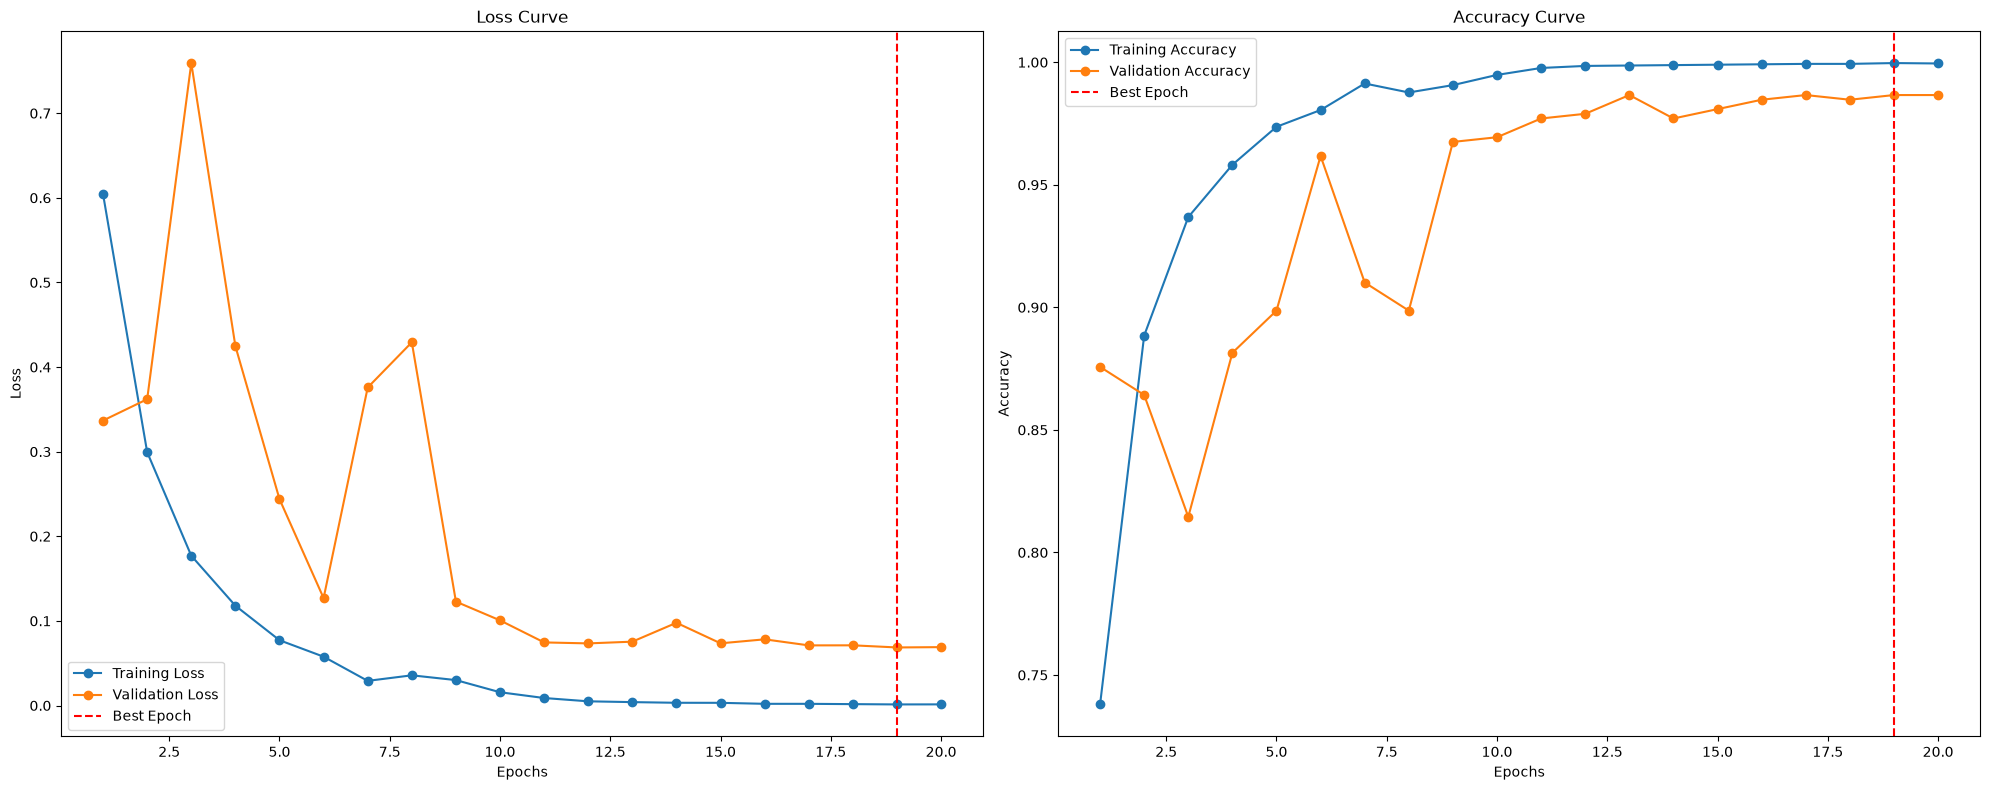


Training Report:
Total training time: 00:12:42
Total epochs run: 20
Best Training Loss: 0.0013 at epoch 19
Best Training Accuracy: 0.9997

Validation Report:
Best Validation Loss: 0.0686 at epoch 19
Best Validation Accuracy: 0.9866
Final Validation Loss: 0.0690
Final Validation Accuracy: 0.9866

Inference Report:
Total Inference Time (Validation only): 00:01:28
Accuracy:    0.98662
Recall:      0.98559
Precision:   0.98438
F1 Score:    0.98497
MCC:         0.97545
PR AUC:      0.99653
Kappa:       0.97544
Specificity: 0.99180
Saved fold 1 checkpoint -> densenet169_fold1.pth

FOLD 2/5  (train=2091, val=523)

Processing class: Bengin cases
Original images saved: 469


 81%|████████▏ | 382/469 [00:23<00:05, 16.58it/s]


Augmented images created: 1531
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1289


 55%|█████▌    | 710/1289 [00:09<00:08, 72.05it/s] 


Augmented images created: 711
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:27<00:05, 10.11it/s]


... (12 outputs left out)

Validation Loss: 0.1335, Validation Accuracy: 0.9694
Training Loss: 0.0052, Training Accuracy: 0.9983
Patience Counter: 2/5

Epoch 13/20
------------------------------


Validation Loss: 0.1718, Validation Accuracy: 0.9637
Training Loss: 0.0036, Training Accuracy: 0.9992
Patience Counter: 3/5

Epoch 14/20
------------------------------


Validation Loss: 0.1768, Validation Accuracy: 0.9541
Training Loss: 0.0051, Training Accuracy: 0.9988
Patience Counter: 4/5

Epoch 15/20
------------------------------


Validation Loss: 0.1346, Validation Accuracy: 0.9694
Training Loss: 0.0021, Training Accuracy: 0.9995
Patience Counter: 5/5
Early stopping triggered at epoch 15.


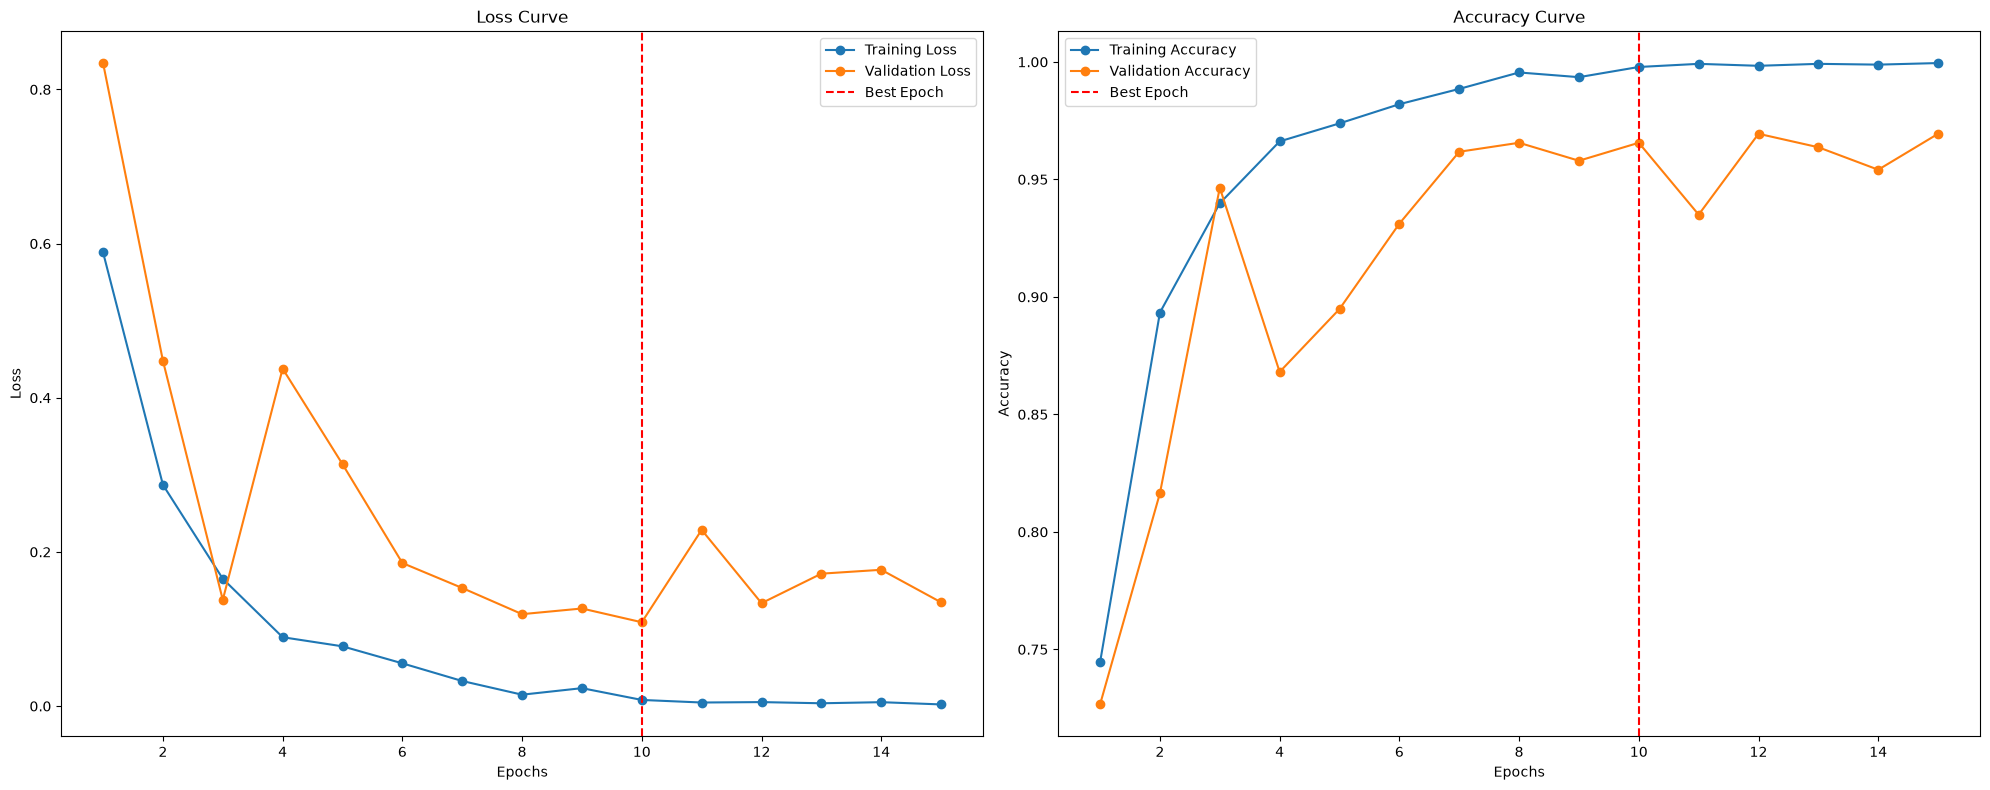


Training Report:
Total training time: 00:09:31
Total epochs run: 15
Best Training Loss: 0.0080 at epoch 10
Best Training Accuracy: 0.9978

Validation Report:
Best Validation Loss: 0.1088 at epoch 10
Best Validation Accuracy: 0.9656
Final Validation Loss: 0.1346
Final Validation Accuracy: 0.9694

Inference Report:
Total Inference Time (Validation only): 00:01:06
Accuracy:    0.96941
Recall:      0.96853
Precision:   0.96519
F1 Score:    0.96660
MCC:         0.94432
PR AUC:      0.99198
Kappa:       0.94413
Specificity: 0.98265
Saved fold 2 checkpoint -> densenet169_fold2.pth

FOLD 3/5  (train=2091, val=523)

Processing class: Bengin cases
Original images saved: 470


 81%|████████▏ | 382/470 [00:23<00:05, 16.32it/s]


Augmented images created: 1530
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1288


 55%|█████▌    | 711/1288 [00:10<00:08, 65.14it/s]


Augmented images created: 712
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:25<00:05, 10.67it/s]


... (15 outputs left out)

Validation Loss: 0.0835, Validation Accuracy: 0.9790
Training Loss: 0.0022, Training Accuracy: 0.9993
Patience Counter: 2/5

Epoch 16/20
------------------------------


Validation Loss: 0.0875, Validation Accuracy: 0.9828
Training Loss: 0.0023, Training Accuracy: 0.9990
Patience Counter: 3/5

Epoch 17/20
------------------------------


Validation Loss: 0.0888, Validation Accuracy: 0.9828
Training Loss: 0.0016, Training Accuracy: 0.9993
Patience Counter: 4/5

Epoch 18/20
------------------------------


Validation Loss: 0.0873, Validation Accuracy: 0.9790
Training Loss: 0.0019, Training Accuracy: 0.9993
Patience Counter: 5/5
Early stopping triggered at epoch 18.


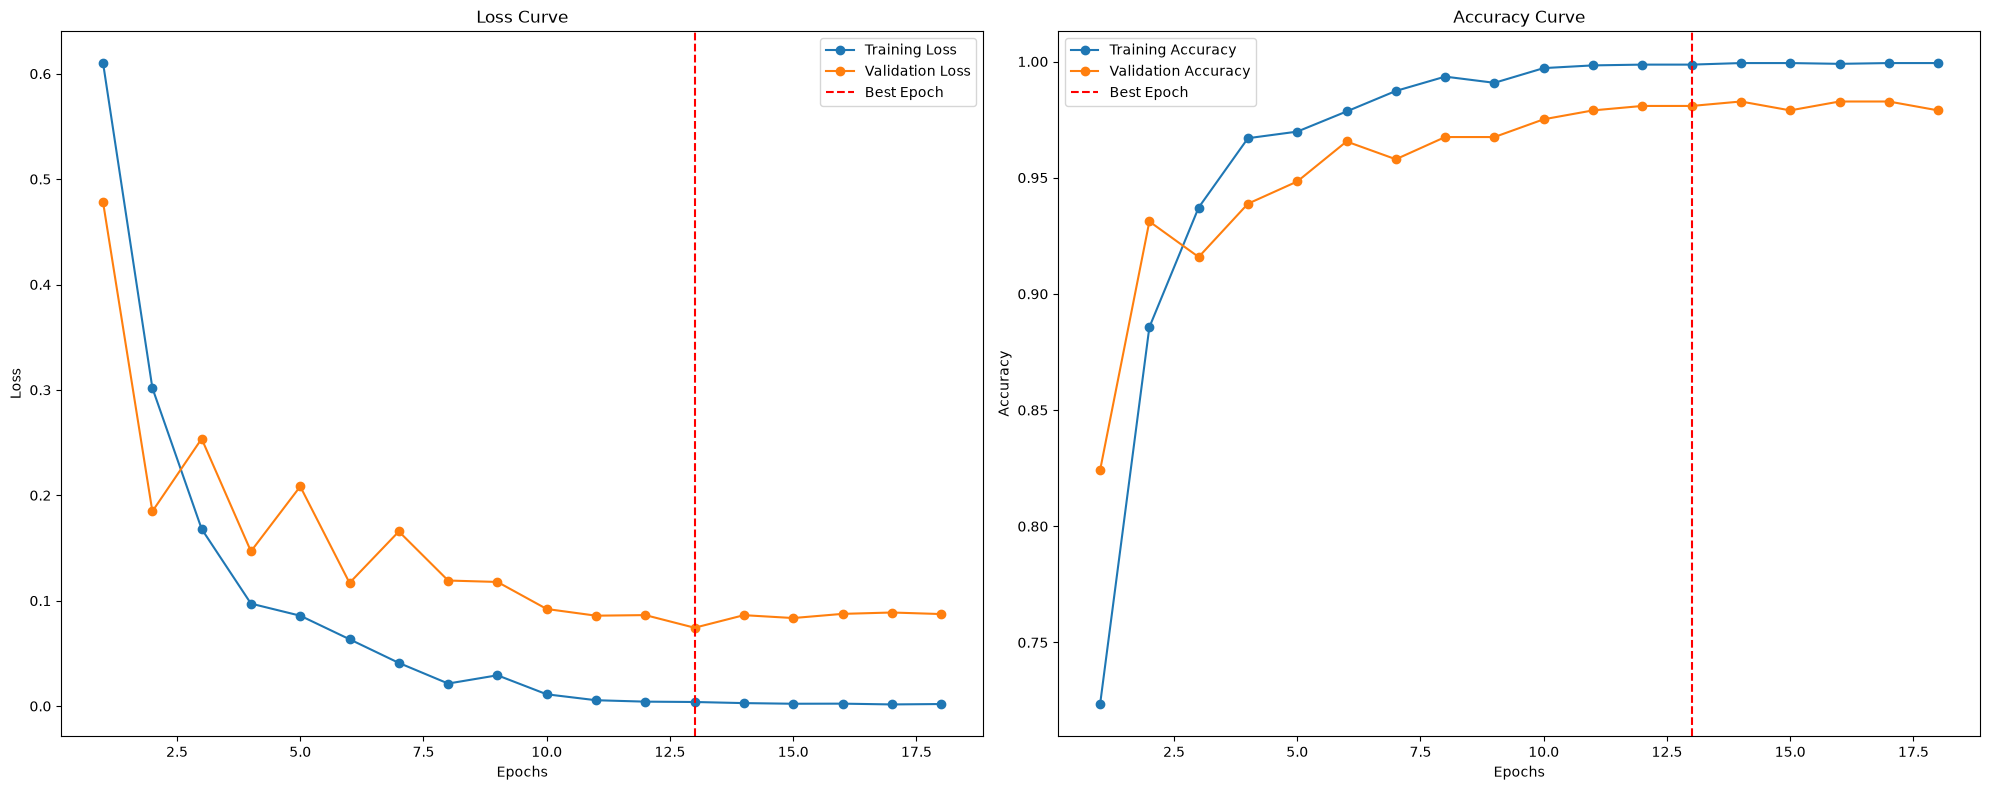


Training Report:
Total training time: 00:11:20
Total epochs run: 18
Best Training Loss: 0.0039 at epoch 13
Best Training Accuracy: 0.9987

Validation Report:
Best Validation Loss: 0.0743 at epoch 13
Best Validation Accuracy: 0.9809
Final Validation Loss: 0.0873
Final Validation Accuracy: 0.9790

Inference Report:
Total Inference Time (Validation only): 00:01:19
Accuracy:    0.97897
Recall:      0.97775
Precision:   0.97650
F1 Score:    0.97711
MCC:         0.96131
PR AUC:      0.99558
Kappa:       0.96130
Specificity: 0.98680
Saved fold 3 checkpoint -> densenet169_fold3.pth

FOLD 4/5  (train=2091, val=523)

Processing class: Bengin cases
Original images saved: 470


 81%|████████▏ | 382/470 [00:22<00:05, 17.33it/s]


Augmented images created: 1530
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1289


 55%|█████▌    | 710/1289 [00:12<00:09, 59.15it/s]


Augmented images created: 711
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 332


 83%|████████▎ | 277/332 [00:26<00:05, 10.29it/s]


... (8 outputs left out)

Validation Loss: 0.1332, Validation Accuracy: 0.9618
Training Loss: 0.0210, Training Accuracy: 0.9937
Patience Counter: 2/5

Epoch 9/20
------------------------------


Validation Loss: 0.1866, Validation Accuracy: 0.9522
Training Loss: 0.0184, Training Accuracy: 0.9945
Patience Counter: 3/5

Epoch 10/20
------------------------------


Validation Loss: 0.1947, Validation Accuracy: 0.9541
Training Loss: 0.0154, Training Accuracy: 0.9943
Patience Counter: 4/5

Epoch 11/20
------------------------------


Validation Loss: 0.2691, Validation Accuracy: 0.9465
Training Loss: 0.0092, Training Accuracy: 0.9973
Patience Counter: 5/5
Early stopping triggered at epoch 11.


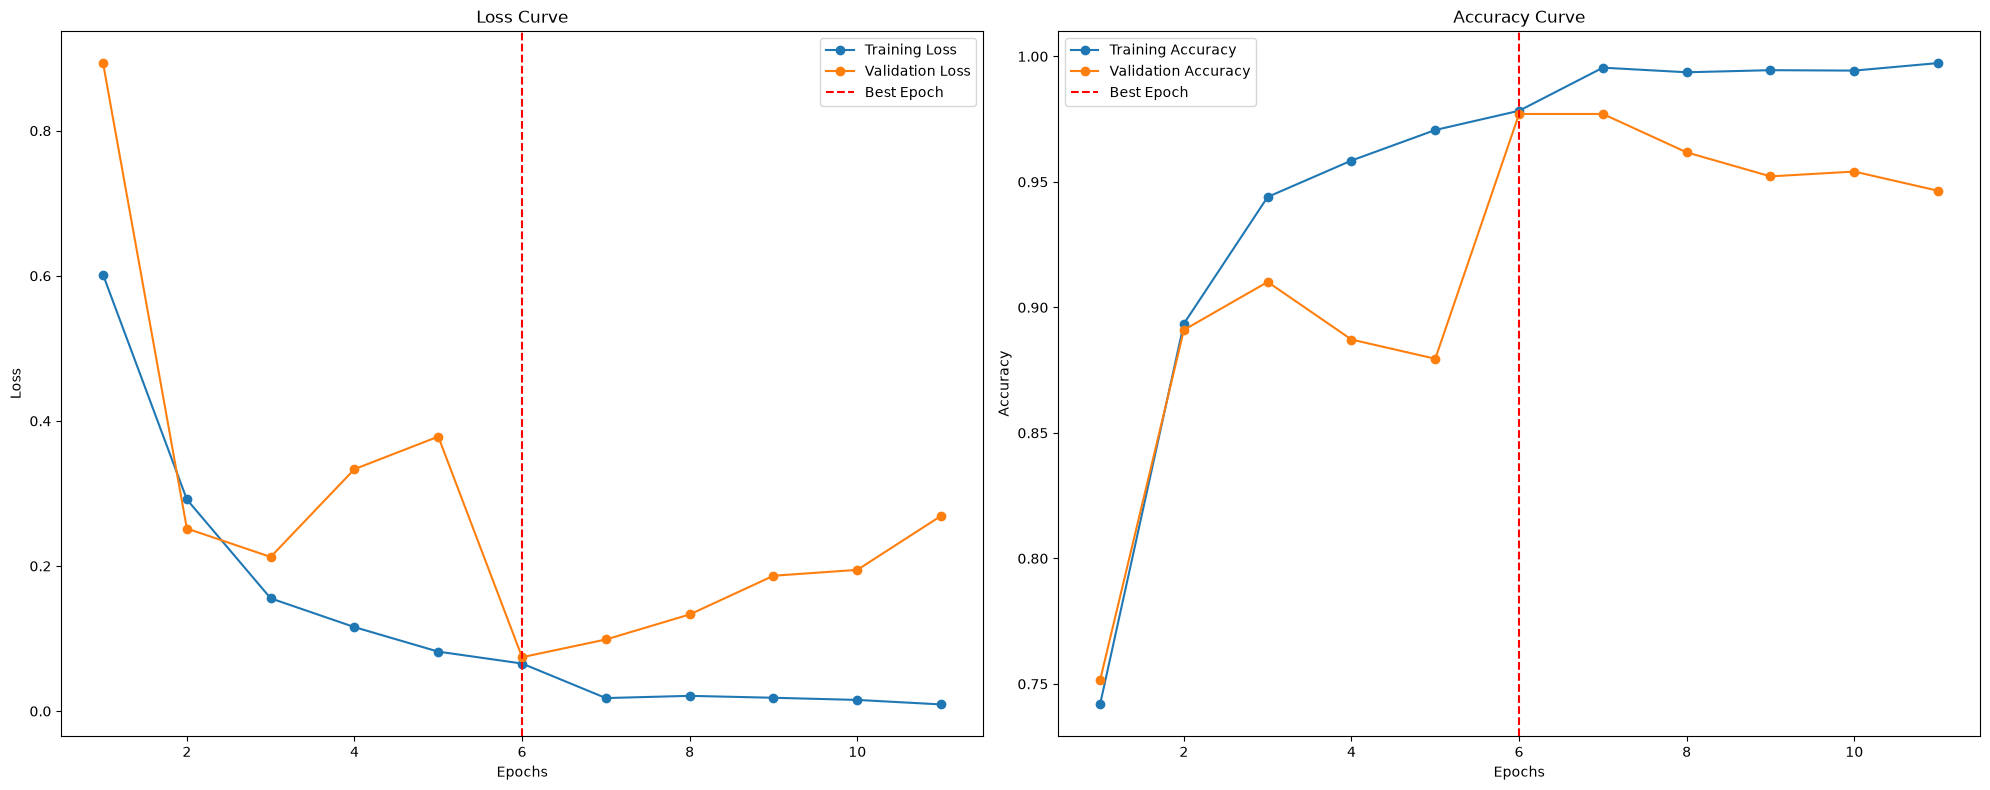


Training Report:
Total training time: 00:06:56
Total epochs run: 11
Best Training Loss: 0.0656 at epoch 6
Best Training Accuracy: 0.9783

Validation Report:
Best Validation Loss: 0.0743 at epoch 6
Best Validation Accuracy: 0.9771
Final Validation Loss: 0.2691
Final Validation Accuracy: 0.9465

Inference Report:
Total Inference Time (Validation only): 00:00:48
Accuracy:    0.94646
Recall:      0.90915
Precision:   0.94017
F1 Score:    0.91914
MCC:         0.90293
PR AUC:      0.98376
Kappa:       0.90112
Specificity: 0.97115
Saved fold 4 checkpoint -> densenet169_fold4.pth

FOLD 5/5  (train=2092, val=522)

Processing class: Bengin cases
Original images saved: 470


 81%|████████▏ | 382/470 [00:22<00:05, 16.70it/s]


Augmented images created: 1530
Total images in class 'Bengin cases': 2000

Processing class: Malignant cases
Original images saved: 1289


 55%|█████▌    | 710/1289 [00:10<00:08, 69.03it/s] 


Augmented images created: 711
Total images in class 'Malignant cases': 2000

Processing class: Normal cases
Original images saved: 333


 83%|████████▎ | 277/333 [00:27<00:05, 10.23it/s]


... (8 outputs left out)

Validation Loss: 0.1712, Validation Accuracy: 0.9483
Training Loss: 0.0245, Training Accuracy: 0.9923
Patience Counter: 2/5

Epoch 9/20
------------------------------


Validation Loss: 0.1652, Validation Accuracy: 0.9655
Training Loss: 0.0140, Training Accuracy: 0.9962
Patience Counter: 3/5

Epoch 10/20
------------------------------


Validation Loss: 0.1157, Validation Accuracy: 0.9732
Training Loss: 0.0106, Training Accuracy: 0.9970
Patience Counter: 4/5

Epoch 11/20
------------------------------


Validation Loss: 0.1372, Validation Accuracy: 0.9693
Training Loss: 0.0088, Training Accuracy: 0.9973
Patience Counter: 5/5
Early stopping triggered at epoch 11.


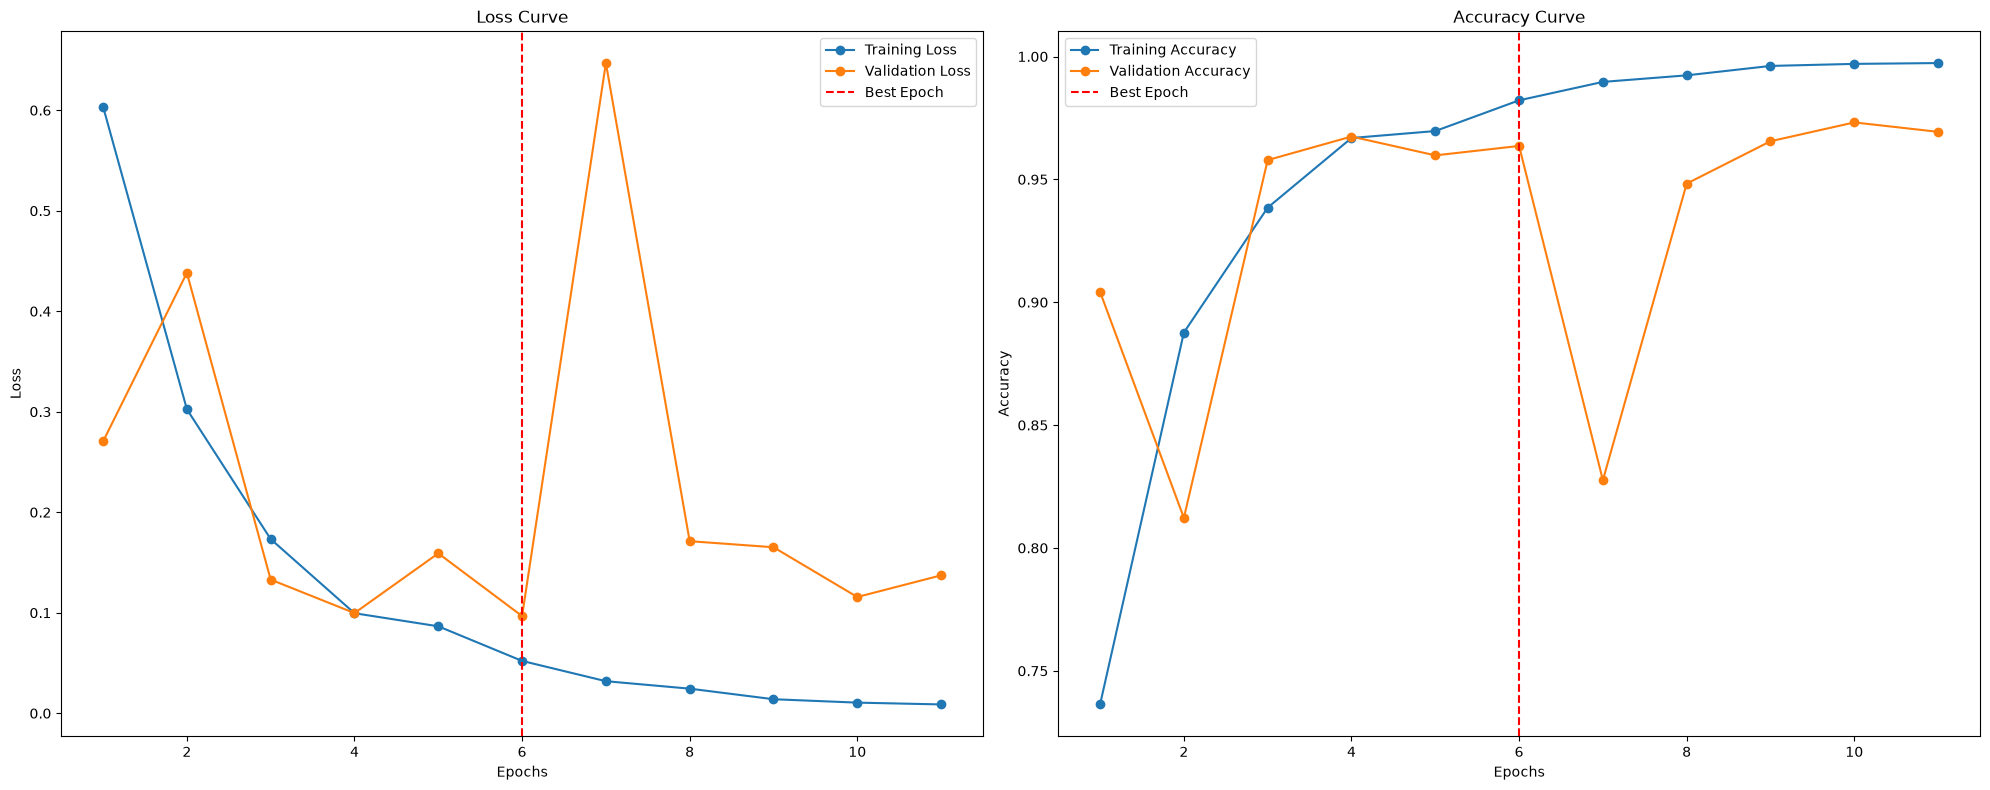


Training Report:
Total training time: 00:06:54
Total epochs run: 11
Best Training Loss: 0.0521 at epoch 6
Best Training Accuracy: 0.9822

Validation Report:
Best Validation Loss: 0.0967 at epoch 6
Best Validation Accuracy: 0.9636
Final Validation Loss: 0.1372
Final Validation Accuracy: 0.9693

Inference Report:
Total Inference Time (Validation only): 00:00:48
Accuracy:    0.96935
Recall:      0.96348
Precision:   0.96174
F1 Score:    0.96204
MCC:         0.94381
PR AUC:      0.99460
Kappa:       0.94356
Specificity: 0.98124
Saved fold 5 checkpoint -> densenet169_fold5.pth

Per-fold results:
      accuracy  recall  precision      f1     mcc  pr_auc   kappa  specificity
fold                                                                          
1       0.9866  0.9856     0.9844  0.9850  0.9754  0.9965  0.9754       0.9918
2       0.9694  0.9685     0.9652  0.9666  0.9443  0.9920  0.9441       0.9827
3       0.9790  0.9777     0.9765  0.9771  0.9613  0.9956  0.9613       0.9868
4     

In [12]:
import gc
import os
import shutil
import numpy as np
import pandas as pd
import timm
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import StratifiedKFold
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader

# Ensure CustomImageDataset, offline_augment_train, loading_the_data, data_transform,
# evaluate_model_with_metrics, and train_model are imported from your modules
from my_dataset import CustomImageDataset

# ──────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────
MODEL_NAME = "densenet169"
PRETRAINED = False
N_FOLDS = 5
TARGET_PER_CLASS = 2000
RANDOM_STATE = 42
BASE_AUG_DIR = r"D:\lung cancer dataset\CV_TrainAug"
CLEANUP_BETWEEN_FOLDS = True

NUM_EPOCHS = 20
PATIENCE = 5
MIN_DELTA = 0.001
BASE_LR = 1e-4
WEIGHT_DECAY = 1e-4
BATCH_SIZE = 32
NUM_WORKERS = 4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ──────────────────────────────────────────────────────────────────────────
# LABEL MAPPING
# ──────────────────────────────────────────────────────────────────────────
# Assuming df is loaded here
# df = pd.read_csv('...')

label_mapping = {label: idx for idx, label in enumerate(df["labels"].unique())}
num_classes = len(label_mapping)

df = df.reset_index(drop=True)
print(f"Full dataset: {len(df)} images across {num_classes} classes")
print(
    f"Running {N_FOLDS}-fold CV using {MODEL_NAME} (no held-out test set)"
)


# ──────────────────────────────────────────────────────────────────────────
# MODEL LOADER
# ──────────────────────────────────────────────────────────────────────────
def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)

    # Check layer attribute naming for DenseNet / ResNet / Vision Transformers
    if hasattr(model, "classifier"):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    elif hasattr(model, "fc"):
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    elif hasattr(model, "head"):
        in_features = model.head.in_features
        model.head = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes),
            nn.LogSoftmax(dim=1),
        )
    else:
        raise ValueError(f"Unexpected classifier layer structure in {model_name}")

    return model


# ──────────────────────────────────────────────────────────────────────────
# SINGLE-FOLD ROUTINE
# ──────────────────────────────────────────────────────────────────────────
def run_single_fold(fold_idx, fold_train_df, fold_val_df):
    print(
        f"\n{'='*70}\nFOLD {fold_idx}/{N_FOLDS}"
        f"  (train={len(fold_train_df)}, val={len(fold_val_df)})\n{'='*70}"
    )

    # ---- offline augmentation, isolated per fold ----
    fold_aug_dir = os.path.join(BASE_AUG_DIR, f"fold_{fold_idx}")
    if os.path.exists(fold_aug_dir):
        shutil.rmtree(fold_aug_dir)

    offline_augment_train(
        fold_train_df, fold_aug_dir, target_per_class=TARGET_PER_CLASS
    )
    fold_train_expanded_df = loading_the_data(fold_aug_dir)

    # ---- datasets / loaders ----
    fold_train_labels = (
        fold_train_expanded_df["labels"].map(label_mapping).values
    )
    fold_val_labels = fold_val_df["labels"].map(label_mapping).values

    fold_train_dataset = CustomImageDataset(
        fold_train_expanded_df["filepaths"].values,
        fold_train_labels,
        transform=data_transform,
    )
    fold_val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values,
        fold_val_labels,
        transform=data_transform,
    )

    fold_train_loader = DataLoader(
        fold_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )
    fold_val_loader = DataLoader(
        fold_val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
    )

    # ---- fresh model, optimizer, scheduler, criterion ----
    model = load_model(
        MODEL_NAME, num_classes=num_classes, pretrained=PRETRAINED
    ).to(device)

    # Since load_model includes nn.LogSoftmax, nn.NLLLoss is used as the target criterion
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.AdamW(
        model.parameters(), lr=BASE_LR, weight_decay=WEIGHT_DECAY
    )
    scheduler = CosineAnnealingLR(
        optimizer, T_max=NUM_EPOCHS, eta_min=1e-6
    )

    train_model(
        model,
        fold_train_loader,
        fold_val_loader,
        criterion,
        optimizer,
        scheduler,
        num_epochs=NUM_EPOCHS,
        patience=PATIENCE,
        min_delta=MIN_DELTA,
    )

    fold_metrics = evaluate_model_with_metrics(model, fold_val_loader)
    if fold_metrics is None:
        raise ValueError(
            "evaluate_model_with_metrics returned None - ensure it returns a dictionary of scalar metrics."
        )

    checkpoint_path = f"{MODEL_NAME}_fold{fold_idx}.pth"
    torch.save(model.state_dict(), checkpoint_path)
    print(f"Saved fold {fold_idx} checkpoint -> {checkpoint_path}")

    # ---- cleanup ----
    if CLEANUP_BETWEEN_FOLDS:
        shutil.rmtree(fold_aug_dir)

    del model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()

    return fold_metrics


# ──────────────────────────────────────────────────────────────────────────
# MAIN CV LOOP
# ──────────────────────────────────────────────────────────────────────────
skf = StratifiedKFold(
    n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE
)

fold_results = []
for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df["filepaths"], df["labels"]), start=1
):
    fold_train_df = df.iloc[train_idx].reset_index(drop=True)
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)

    metrics = run_single_fold(fold_idx, fold_train_df, fold_val_df)
    metrics["fold"] = fold_idx
    fold_results.append(metrics)


# ──────────────────────────────────────────────────────────────────────────
# AGGREGATE RESULTS
# ──────────────────────────────────────────────────────────────────────────
def summarize_cv_results(fold_results):
    results_df = pd.DataFrame(fold_results).set_index("fold")
    summary = results_df.agg(["mean", "std"])

    print("\nPer-fold results:")
    print(results_df.round(4))
    print(f"\nMean ± Std across {len(results_df)} folds:")
    for col in results_df.columns:
        print(
            f"  {col}: {summary.loc['mean', col]:.4f} ± {summary.loc['std', col]:.4f}"
        )

    return results_df, summary


cv_results_df, cv_summary = summarize_cv_results(fold_results)
cv_results_df.to_csv(f"cv_fold_results_{MODEL_NAME}.csv")

# MC Nemar's Test Result

In [26]:
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import StratifiedKFold
from statsmodels.stats.contingency_tables import mcnemar


# ──────────────────────────────────────────────────────────────────────────
# 1. PREDICTION EXTRACTION FUNCTION
# ──────────────────────────────────────────────────────────────────────────
@torch.no_grad()
def get_model_predictions(model, dataloader, device="cuda"):
    """Collects ground-truth targets and predicted class indices from a PyTorch model."""
    model.to(device)
    model.eval()

    all_preds = []
    all_targets = []

    for images, targets in dataloader:
        images = images.to(device)
        outputs = model(images)

        # Handle log-probabilities / logits by picking the highest-confidence index
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.numpy())

    return np.array(all_targets), np.array(all_preds)


# ──────────────────────────────────────────────────────────────────────────
# 2. MCNEMAR TEST OOF EVALUATION LOOP
# ──────────────────────────────────────────────────────────────────────────
oof_y_true = []
oof_pred_proposed = []
oof_pred_densenet = []

skf = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)

for fold_idx, (train_idx, val_idx) in enumerate(
    skf.split(df["filepaths"], df["labels"]), start=1
):
    print(f"Evaluating Fold {fold_idx}/5 for McNemar Test...")
    fold_val_df = df.iloc[val_idx].reset_index(drop=True)
    val_labels = fold_val_df["labels"].map(label_mapping).values

    # Validation DataLoader
    val_dataset = CustomImageDataset(
        fold_val_df["filepaths"].values, val_labels, transform=data_transform
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
    )

    # Load Proposed Model Checkpoint
    proposed_model = FetleSwinHybrid(num_classes=num_classes).to(device)
    proposed_model.load_state_dict(
        torch.load(f"model_fold{fold_idx}.pth", map_location=device)
    )

    # Load Baseline DenseNet169 Checkpoint
    densenet_model = load_model("densenet169", num_classes=num_classes).to(
        device
    )
    densenet_model.load_state_dict(
        torch.load(f"densenet169_fold{fold_idx}.pth", map_location=device)
    )

    # Get Out-Of-Fold Predictions
    _, preds_prop = get_model_predictions(
        proposed_model, val_loader, device=device
    )
    _, preds_dense = get_model_predictions(
        densenet_model, val_loader, device=device
    )

    oof_y_true.extend(val_labels)
    oof_pred_proposed.extend(preds_prop)
    oof_pred_densenet.extend(preds_dense)


# ──────────────────────────────────────────────────────────────────────────
# 3. STATISTICAL ANALYSIS & CONTINGENCY TABLE
# ──────────────────────────────────────────────────────────────────────────
y_true = np.array(oof_y_true)
correct_proposed = np.array(oof_pred_proposed) == y_true
correct_densenet = np.array(oof_pred_densenet) == y_true

# Matrix Cells
n00 = np.sum(correct_proposed & correct_densenet)
n01 = np.sum(
    correct_proposed & ~correct_densenet
)  # Proposed correct, DenseNet wrong
n10 = np.sum(
    ~correct_proposed & correct_densenet
)  # Proposed wrong, DenseNet correct
n11 = np.sum(~correct_proposed & ~correct_densenet)

contingency_table = [[n00, n01], [n10, n11]]

# Run McNemar test (Edwards' continuity correction)
result = mcnemar(contingency_table, exact=False, correction=True)

df_table = pd.DataFrame(
    contingency_table,
    index=["FetleSwin Correct", "FetleSwin Incorrect"],
    columns=["DenseNet169 Correct", "DenseNet169 Incorrect"],
)

print(
    "\n========================================================================="
)
print(
    "            MCNEMAR'S TEST ON AGGREGATED OUT-OF-FOLD (OOF) DATA          "
)
print(
    "========================================================================="
)
print("\n2x2 Contingency Table:")
print(df_table.to_string())
print("-" * 73)
print(f"Total Samples Analyzed (N)           : {len(y_true)}")
print(f"FetleSwin Correct / DenseNet Wrong   : {n01}")
print(f"FetleSwin Wrong / DenseNet Correct   : {n10}")
print(f"Chi-Squared Statistic (χ²)          : {result.statistic:.4f}")
print(f"p-value                             : {result.pvalue:.6e}")
print("-" * 73)

if result.pvalue < 0.05:
    print(
        "Result: STATISTICALLY SIGNIFICANT DIFFERENCE (p < 0.05)\n"
        "Interpretation: FetleSwinHybrid demonstrates statistically significant\n"
        "performance gains over DenseNet169."
    )
else:
    print(
        "Result: NO STATISTICALLY SIGNIFICANT DIFFERENCE (p >= 0.05)\n"
        "Interpretation: Performance difference between models is not statistically significant."
    )
print(
    "=========================================================================\n"
)

Evaluating Fold 1/5 for McNemar Test...
Evaluating Fold 2/5 for McNemar Test...
Evaluating Fold 3/5 for McNemar Test...
Evaluating Fold 4/5 for McNemar Test...
Evaluating Fold 5/5 for McNemar Test...

            MCNEMAR'S TEST ON AGGREGATED OUT-OF-FOLD (OOF) DATA          

2x2 Contingency Table:
                     DenseNet169 Correct  DenseNet169 Incorrect
FetleSwin Correct                   2511                     48
FetleSwin Incorrect                   25                     30
-------------------------------------------------------------------------
Total Samples Analyzed (N)           : 2614
FetleSwin Correct / DenseNet Wrong   : 48
FetleSwin Wrong / DenseNet Correct   : 25
Chi-Squared Statistic (χ²)          : 6.6301
p-value                             : 1.002676e-02
-------------------------------------------------------------------------
Result: STATISTICALLY SIGNIFICANT DIFFERENCE (p < 0.05)
Interpretation: FetleSwinHybrid demonstrates statistically significant
performanc

# FelaSwin-Net performance before and after using data augmentation


Epoch 1/30
------------------------------


Validation Loss: 1.0349, Validation Accuracy: 0.5747
Training Loss: 1.0737, Training Accuracy: 0.4448

Epoch 2/30
------------------------------


Validation Loss: 0.8850, Validation Accuracy: 0.6628
Training Loss: 0.9563, Training Accuracy: 0.6341

Epoch 3/30
------------------------------


Validation Loss: 0.7316, Validation Accuracy: 0.7088
Training Loss: 0.8176, Training Accuracy: 0.7025

Epoch 4/30
------------------------------


Validation Loss: 0.6136, Validation Accuracy: 0.8084
Training Loss: 0.6884, Training Accuracy: 0.7604

Epoch 5/30
------------------------------


Validation Loss: 0.4942, Validation Accuracy: 0.9080
Training Loss: 0.5486, Training Accuracy: 0.8651

Epoch 6/30
------------------------------


... (9 outputs left out)

Validation Loss: 0.3592, Validation Accuracy: 0.9732
Training Loss: 0.3031, Training Accuracy: 0.9976
Patience Counter: 2/5

Epoch 16/30
------------------------------


Validation Loss: 0.3754, Validation Accuracy: 0.9617
Training Loss: 0.3021, Training Accuracy: 0.9971
Patience Counter: 3/5

Epoch 17/30
------------------------------


Validation Loss: 0.3575, Validation Accuracy: 0.9693
Training Loss: 0.3011, Training Accuracy: 0.9976
Patience Counter: 4/5

Epoch 18/30
------------------------------


Validation Loss: 0.3568, Validation Accuracy: 0.9732
Training Loss: 0.2996, Training Accuracy: 0.9981
Patience Counter: 5/5
Early stopping triggered at epoch 18.


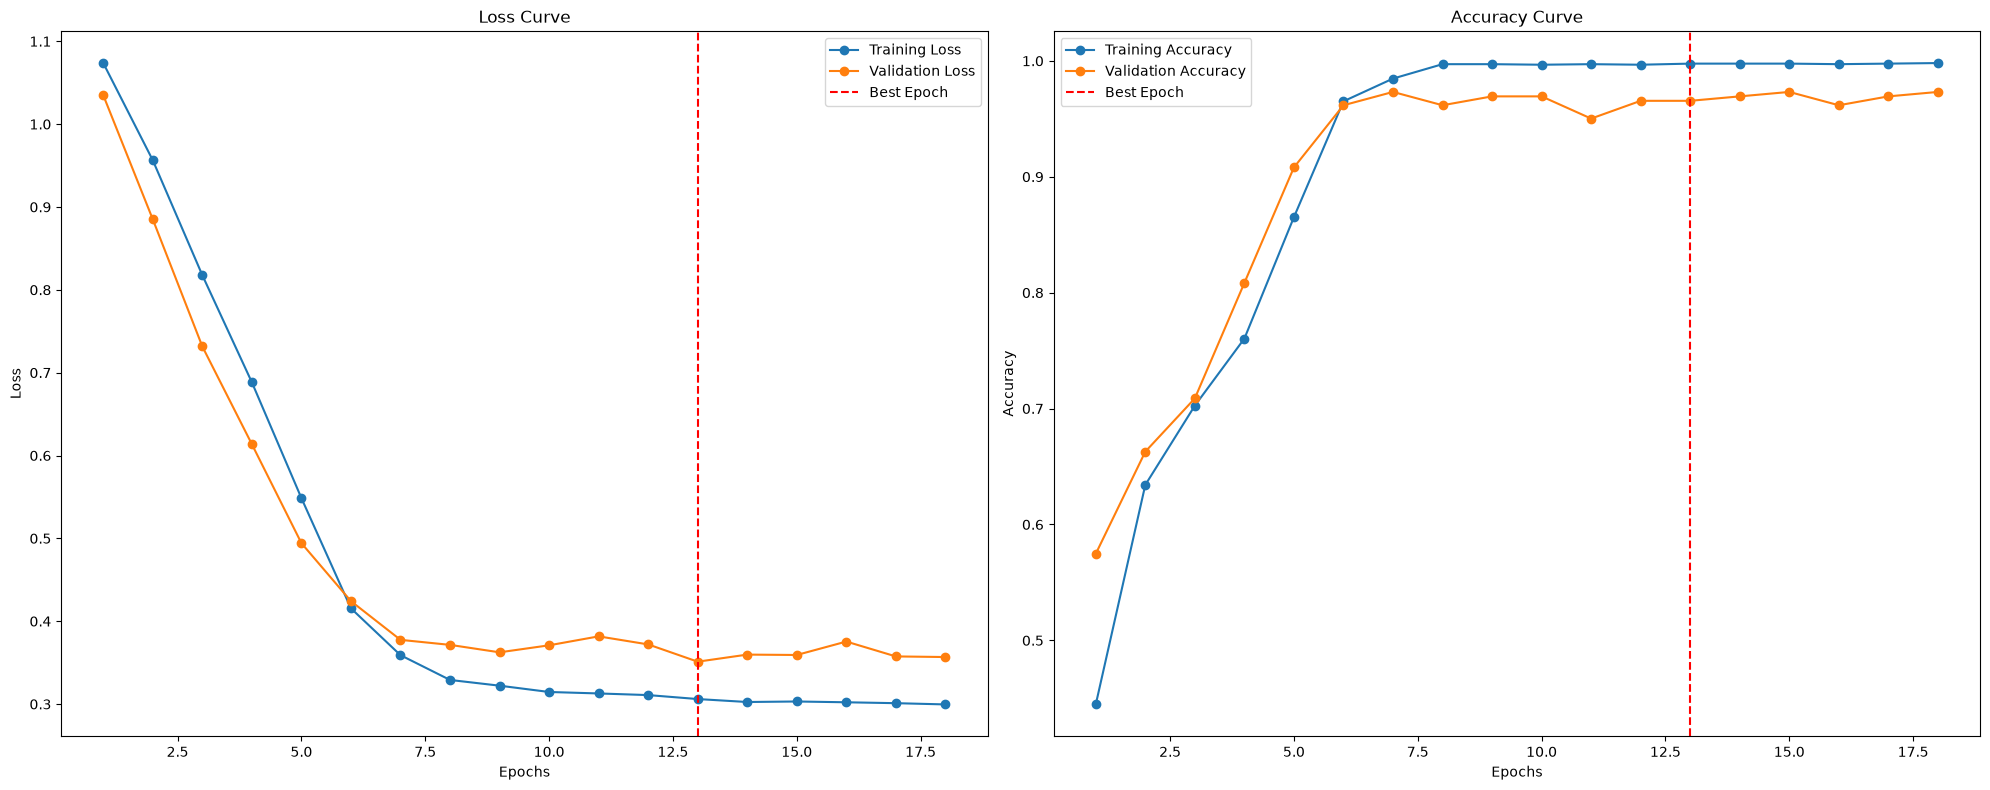


Training Report:
Total training time: 00:04:52
Total epochs run: 18
Best Training Loss: 0.3061 at epoch 13
Best Training Accuracy: 0.9976

Validation Report:
Best Validation Loss: 0.3512 at epoch 13
Best Validation Accuracy: 0.9655
Final Validation Loss: 0.3568
Final Validation Accuracy: 0.9732

Inference Report:
Total Inference Time (Validation only): 00:01:16


In [22]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [23]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98092
Recall:      0.97304
Precision:   0.98008
F1 Score:    0.97645
MCC:         0.96497
PR AUC:      0.99806
Kappa:       0.96485
Specificity: 0.98694


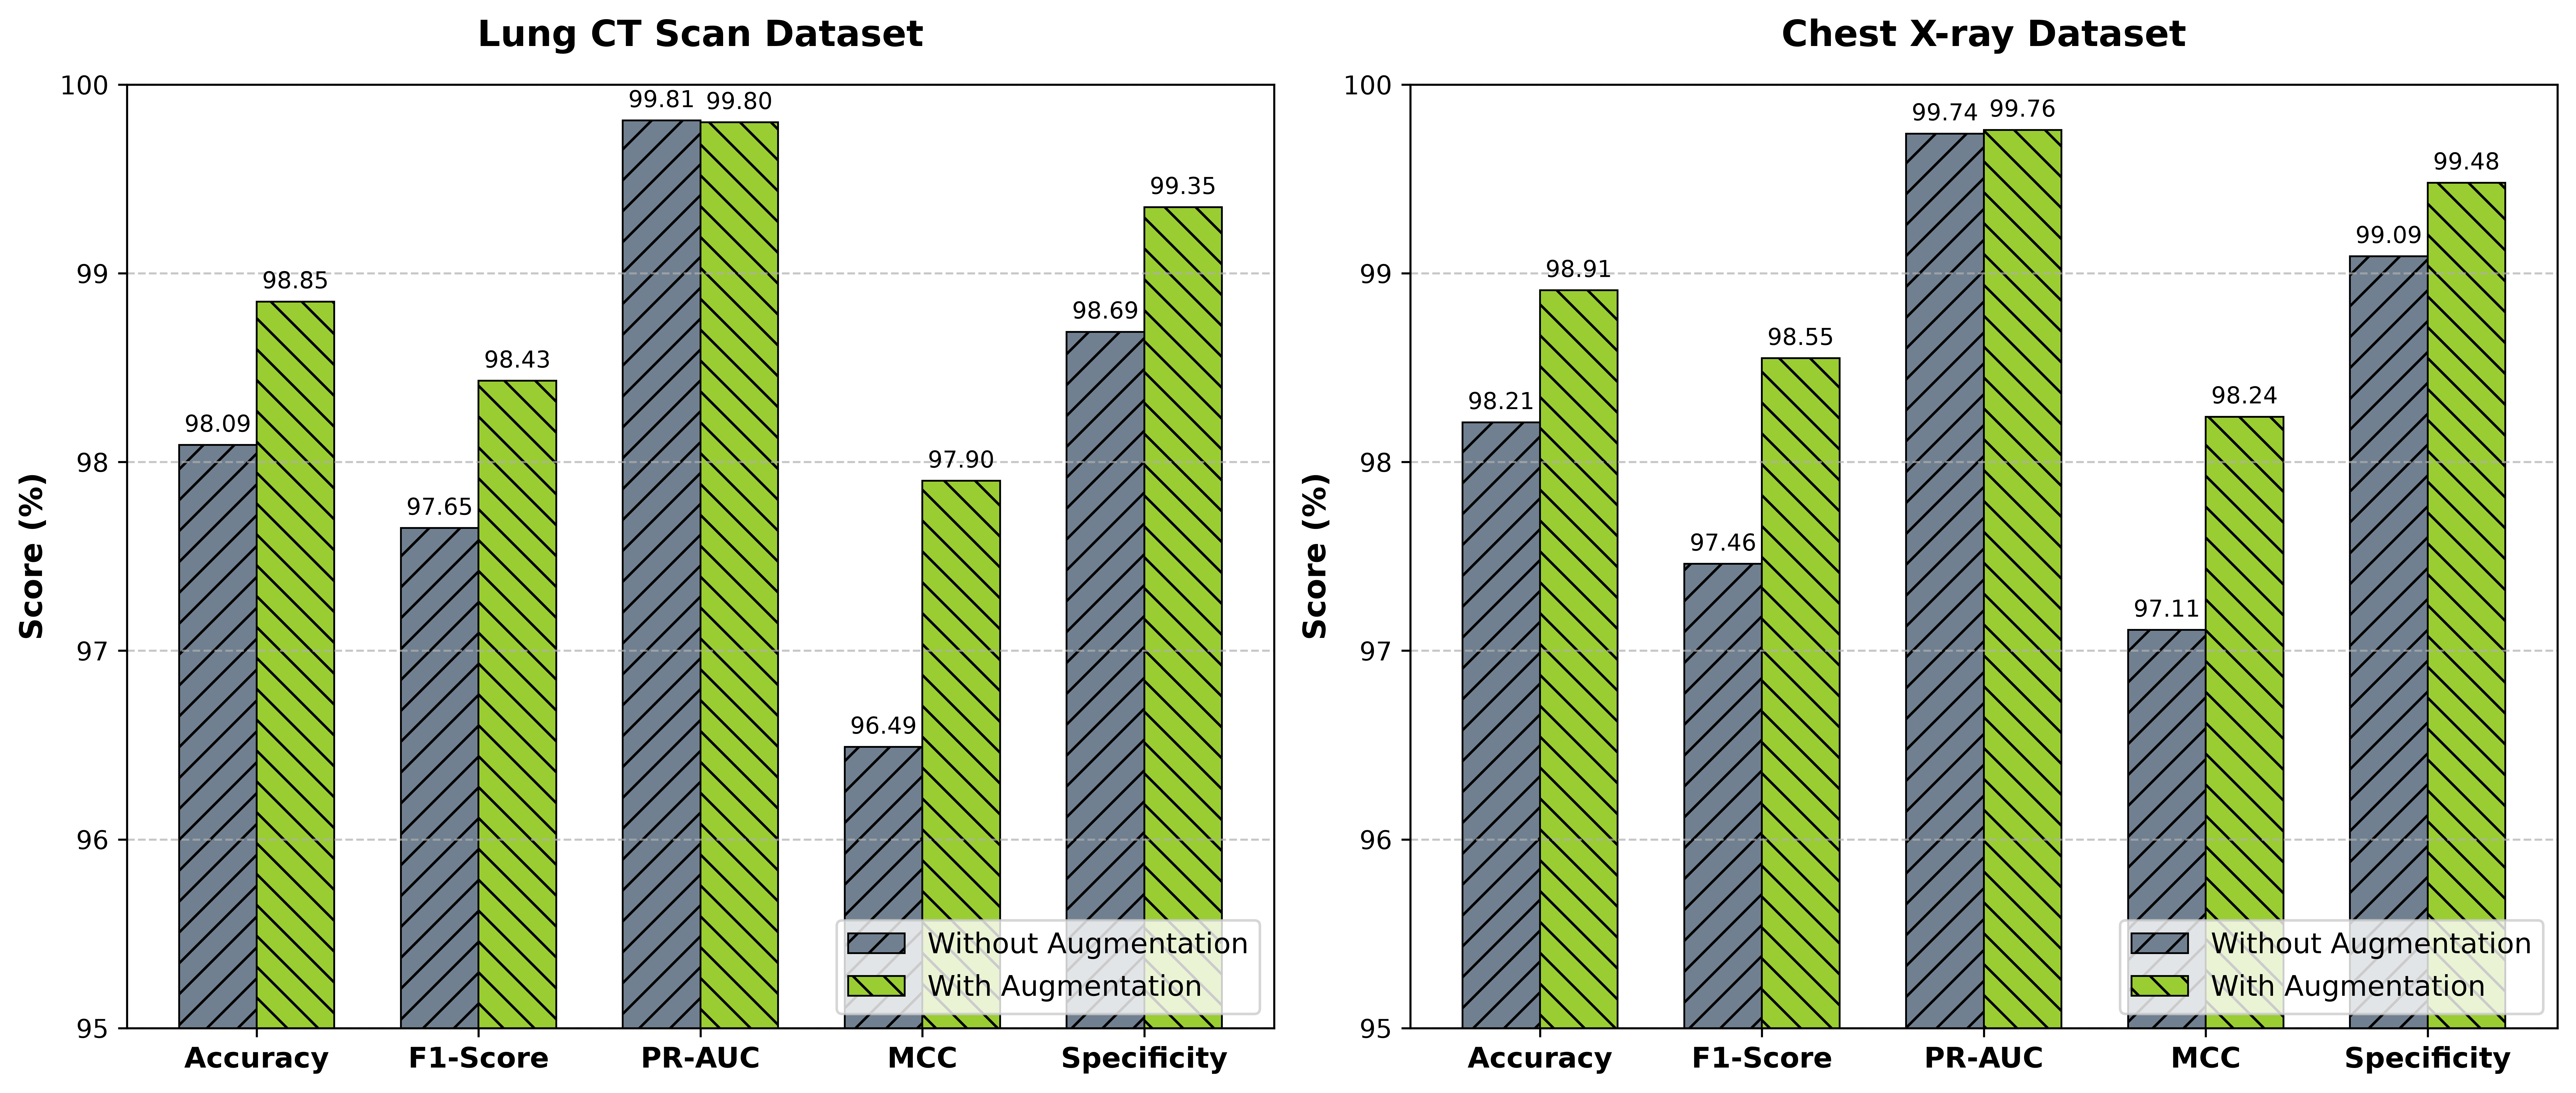

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def generate_augmentation_comparison_plot(output_path="Figure8_Augmentation_Comparison.png"):
    # Define the metrics and data
    metrics = ['Accuracy', 'F1-Score', 'PR-AUC', 'MCC', 'Specificity']
    
    # CT Scan Data
    ct_no_aug = [98.09, 97.65, 99.81, 96.49, 98.69]
    ct_aug = [98.85, 98.43, 99.80, 97.90, 99.35]
    
    # X-ray Data
    xray_no_aug = [98.21, 97.46, 99.74, 97.11, 99.09]
    xray_aug = [98.91, 98.55, 99.76, 98.24, 99.48]

    x = np.arange(len(metrics))
    width = 0.35  # the width of the bars

    # Create figure and subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), dpi=600)

    # Plot CT Scan Data with hatch patterns
    rects1_ct = ax1.bar(x - width/2, ct_no_aug, width, label='Without Augmentation', 
                        color='slategray', edgecolor='black', linewidth=0.7, hatch='//')
    rects2_ct = ax1.bar(x + width/2, ct_aug, width, label='With Augmentation', 
                        color='yellowgreen', edgecolor='black', linewidth=0.7, hatch='\\\\')

    # Plot X-ray Data with hatch patterns
    rects1_xray = ax2.bar(x - width/2, xray_no_aug, width, label='Without Augmentation', 
                          color='slategray', edgecolor='black', linewidth=0.7, hatch='//')
    rects2_xray = ax2.bar(x + width/2, xray_aug, width, label='With Augmentation', 
                          color='yellowgreen', edgecolor='black', linewidth=0.7, hatch='\\\\')

    # Formatting function
    def format_axes(ax, title):
        ax.set_ylabel('Score (%)', fontsize=12, fontweight='bold')
        ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
        ax.set_xticks(x)
        ax.set_xticklabels(metrics, fontsize=11, fontweight='bold')
        ax.set_ylim(95, 100) # Zoomed in to highlight the subtle differences
        ax.legend(loc='lower right', fontsize=11)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        
        # Add data labels on top of the bars
        for rect in ax.patches:
            height = rect.get_height()
            ax.annotate(f'{height:.2f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3),  # 3 points vertical offset
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9, rotation=0)

    # Apply formatting
    format_axes(ax1, 'Lung CT Scan Dataset')
    format_axes(ax2, 'Chest X-ray Dataset')

    plt.tight_layout()
    plt.savefig(output_path, dpi=600, bbox_inches='tight')
    plt.show()

# Generate the plot
generate_augmentation_comparison_plot()

# Baseline Model's Classification Performance

In [21]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("resnext101_32x4d", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.4481, Validation Accuracy: 0.7701
Training Loss: 0.7931, Training Accuracy: 0.6328

Epoch 2/30
------------------------------


Validation Loss: 0.2633, Validation Accuracy: 0.8774
Training Loss: 0.5148, Training Accuracy: 0.7883

Epoch 3/30
------------------------------


Validation Loss: 0.2971, Validation Accuracy: 0.8812
Training Loss: 0.3319, Training Accuracy: 0.8735
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.1817, Validation Accuracy: 0.9272
Training Loss: 0.2195, Training Accuracy: 0.9210

Epoch 5/30
------------------------------


Validation Loss: 0.1775, Validation Accuracy: 0.9272
Training Loss: 0.1256, Training Accuracy: 0.9557

Epoch 6/30
------------------------------


... (13 outputs left out)

Validation Loss: 0.1001, Validation Accuracy: 0.9732
Training Loss: 0.0058, Training Accuracy: 0.9990
Patience Counter: 2/5

Epoch 20/30
------------------------------


Validation Loss: 0.1168, Validation Accuracy: 0.9693
Training Loss: 0.0037, Training Accuracy: 0.9990
Patience Counter: 3/5

Epoch 21/30
------------------------------


Validation Loss: 0.1226, Validation Accuracy: 0.9732
Training Loss: 0.0083, Training Accuracy: 0.9973
Patience Counter: 4/5

Epoch 22/30
------------------------------


Validation Loss: 0.1136, Validation Accuracy: 0.9770
Training Loss: 0.0056, Training Accuracy: 0.9987
Patience Counter: 5/5
Early stopping triggered at epoch 22.


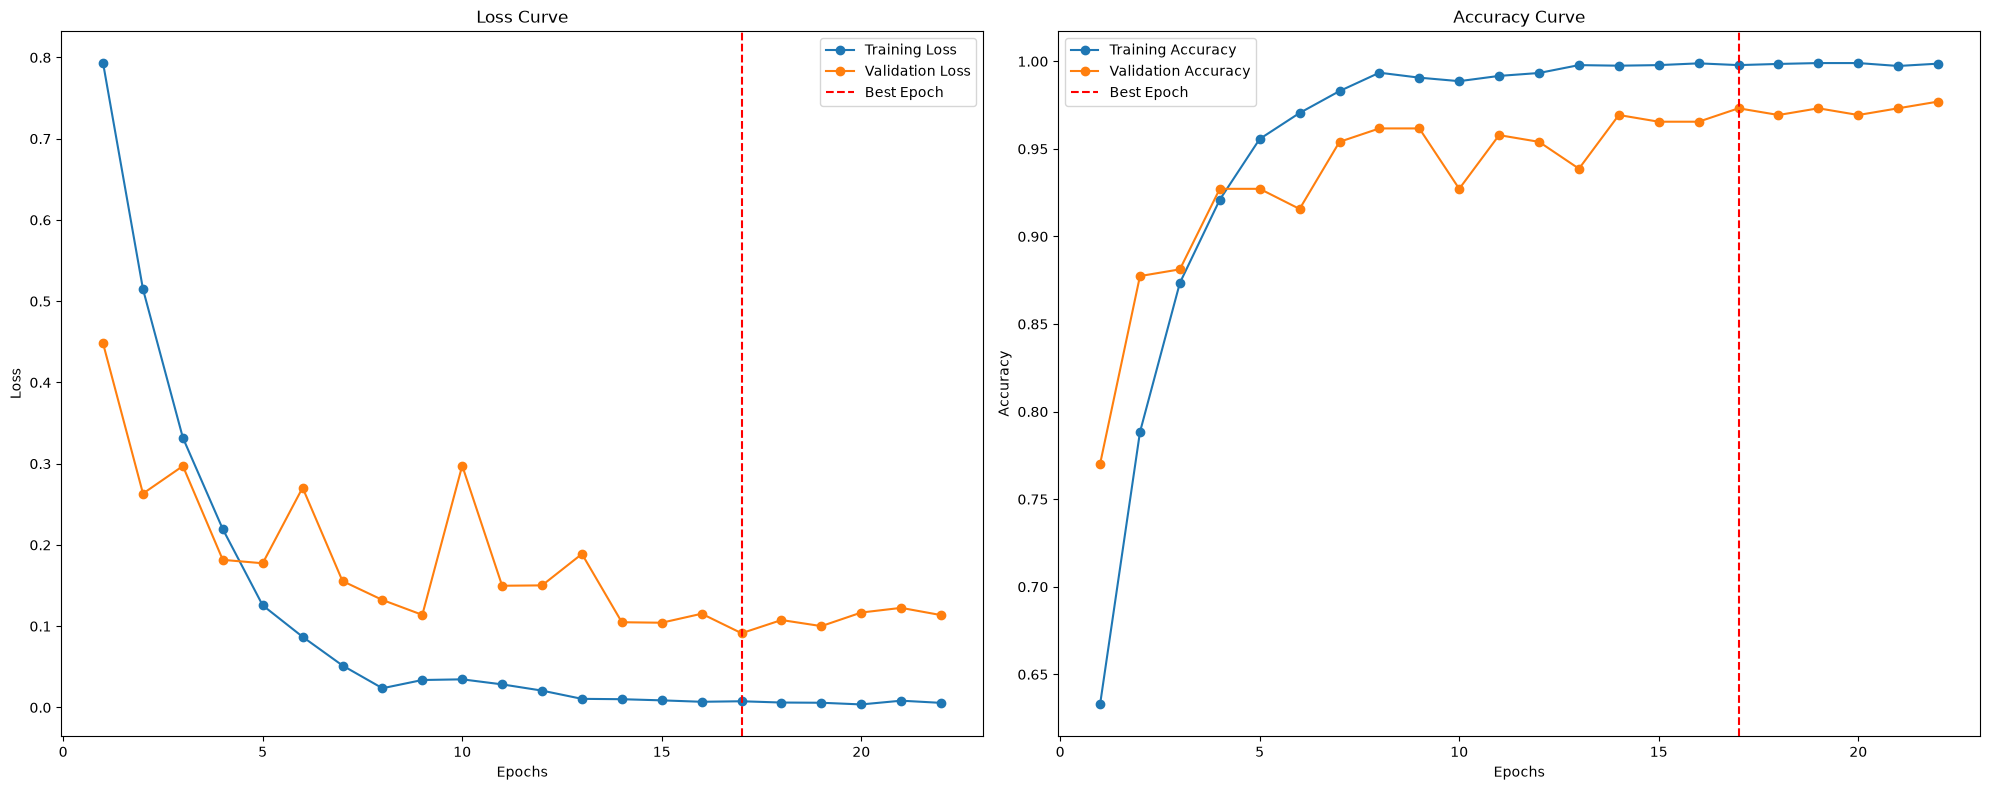


Training Report:
Total training time: 00:17:41
Total epochs run: 22
Best Training Loss: 0.0076 at epoch 17
Best Training Accuracy: 0.9978

Validation Report:
Best Validation Loss: 0.0914 at epoch 17
Best Validation Accuracy: 0.9732
Final Validation Loss: 0.1136
Final Validation Accuracy: 0.9770

Inference Report:
Total Inference Time (Validation only): 00:01:41


In [22]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [27]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97710
Recall:      0.96511
Precision:   0.97424
F1 Score:    0.96959
MCC:         0.95790
PR AUC:      0.99853
Kappa:       0.95781
Specificity: 0.98530


In [25]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained)
    
    # Check if the model uses 'classifier' or 'head' as the classification layer
    if hasattr(model, 'classifier'):
        in_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    elif hasattr(model, 'fc'):  # For models like ResNeSt
        in_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    else:
        raise ValueError("Unexpected classifier layer name in model")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("densenet169", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

In [35]:
torch.cuda.empty_cache()


Epoch 1/30
------------------------------


Validation Loss: 0.3954, Validation Accuracy: 0.8429
Training Loss: 0.6163, Training Accuracy: 0.7373

Epoch 2/30
------------------------------


Validation Loss: 0.2342, Validation Accuracy: 0.9080
Training Loss: 0.3339, Training Accuracy: 0.8727

Epoch 3/30
------------------------------


Validation Loss: 0.9523, Validation Accuracy: 0.6820
Training Loss: 0.1905, Training Accuracy: 0.9340
Patience Counter: 1/5

Epoch 4/30
------------------------------


Validation Loss: 0.3755, Validation Accuracy: 0.8736
Training Loss: 0.1209, Training Accuracy: 0.9570
Patience Counter: 2/5

Epoch 5/30
------------------------------


Validation Loss: 0.3049, Validation Accuracy: 0.8966
Training Loss: 0.0916, Training Accuracy: 0.9688
Patience Counter: 3/5

Epoch 6/30
------------------------------


... (13 outputs left out)

Validation Loss: 0.0945, Validation Accuracy: 0.9732
Training Loss: 0.0041, Training Accuracy: 0.9982
Patience Counter: 2/5

Epoch 20/30
------------------------------


Validation Loss: 0.0683, Validation Accuracy: 0.9693
Training Loss: 0.0032, Training Accuracy: 0.9987
Patience Counter: 3/5

Epoch 21/30
------------------------------


Validation Loss: 0.0750, Validation Accuracy: 0.9732
Training Loss: 0.0019, Training Accuracy: 0.9990
Patience Counter: 4/5

Epoch 22/30
------------------------------


Validation Loss: 0.1064, Validation Accuracy: 0.9693
Training Loss: 0.0025, Training Accuracy: 0.9988
Patience Counter: 5/5
Early stopping triggered at epoch 22.


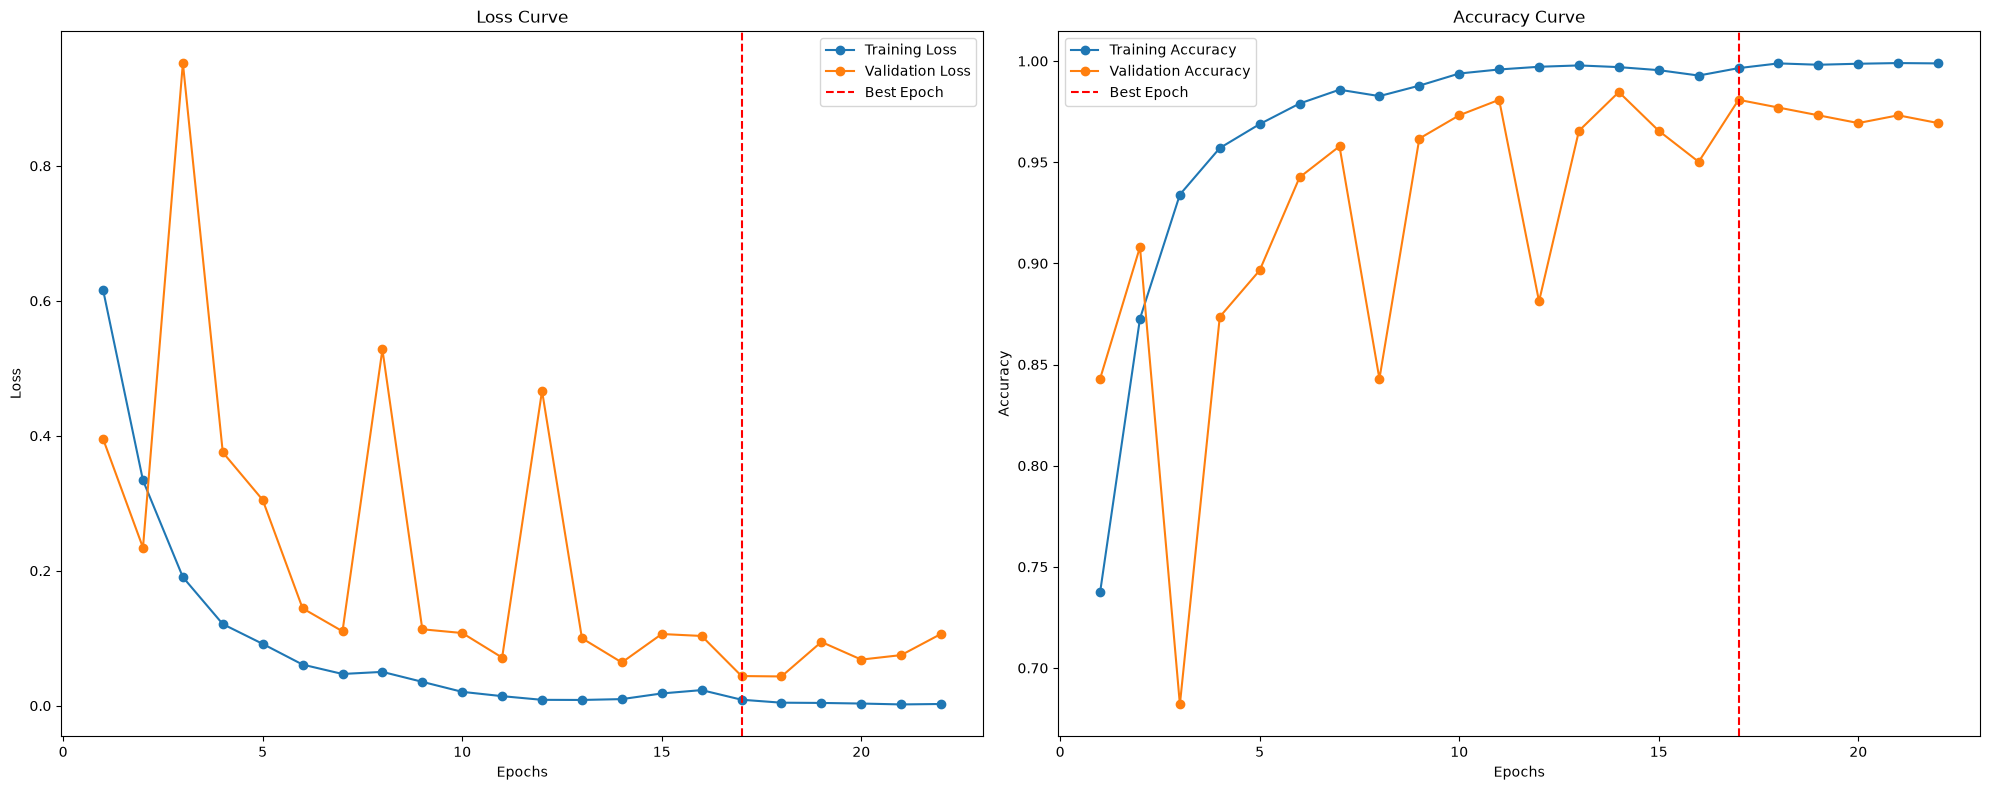


Training Report:
Total training time: 00:14:22
Total epochs run: 22
Best Training Loss: 0.0089 at epoch 17
Best Training Accuracy: 0.9965

Validation Report:
Best Validation Loss: 0.0439 at epoch 17
Best Validation Accuracy: 0.9808
Final Validation Loss: 0.1064
Final Validation Accuracy: 0.9693

Inference Report:
Total Inference Time (Validation only): 00:01:39


In [26]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [27]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.98473
Recall:      0.98456
Precision:   0.97887
F1 Score:    0.98166
MCC:         0.97216
PR AUC:      0.99541
Kappa:       0.97213
Specificity: 0.99190


In [30]:
import timm

def load_model(model_name, num_classes, pretrained=False):
    model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)
    
    # Check if the classification layer is a simple linear head, then replace it
    if hasattr(model, 'get_classifier'):
        in_features = model.get_classifier().in_features
        model.reset_classifier(0)  # Remove the existing head
        model.classifier = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )
    else:
        raise ValueError(f"Model {model_name} does not support get_classifier method.")

    return model


# Number of classes (adjust to your problem)
num_classes = len(label_mapping)  # Replace label_mapping with the actual class labels

# Load EfficientNetV2-M without pre-trained weights
model = load_model("efficientnet_b4", num_classes, pretrained=False)

model = model.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
# Define Learning Rate Scheduler (e.g., Cosine Annealing)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)


Epoch 1/30
------------------------------


Validation Loss: 0.5726, Validation Accuracy: 0.7931
Training Loss: 0.7884, Training Accuracy: 0.6225

Epoch 2/30
------------------------------


Validation Loss: 0.3266, Validation Accuracy: 0.8774
Training Loss: 0.4322, Training Accuracy: 0.8332

Epoch 3/30
------------------------------


Validation Loss: 0.2442, Validation Accuracy: 0.9042
Training Loss: 0.2638, Training Accuracy: 0.9072

Epoch 4/30
------------------------------


Validation Loss: 0.1929, Validation Accuracy: 0.9310
Training Loss: 0.1597, Training Accuracy: 0.9473

Epoch 5/30
------------------------------


Validation Loss: 0.1570, Validation Accuracy: 0.9540
Training Loss: 0.1321, Training Accuracy: 0.9573

Epoch 6/30
------------------------------


... (6 outputs left out)

Validation Loss: 0.1381, Validation Accuracy: 0.9579
Training Loss: 0.0191, Training Accuracy: 0.9938
Patience Counter: 2/5

Epoch 13/30
------------------------------


Validation Loss: 0.2113, Validation Accuracy: 0.9579
Training Loss: 0.0308, Training Accuracy: 0.9907
Patience Counter: 3/5

Epoch 14/30
------------------------------


Validation Loss: 0.1731, Validation Accuracy: 0.9655
Training Loss: 0.0245, Training Accuracy: 0.9910
Patience Counter: 4/5

Epoch 15/30
------------------------------


Validation Loss: 0.1127, Validation Accuracy: 0.9655
Training Loss: 0.0138, Training Accuracy: 0.9955
Patience Counter: 5/5
Early stopping triggered at epoch 15.


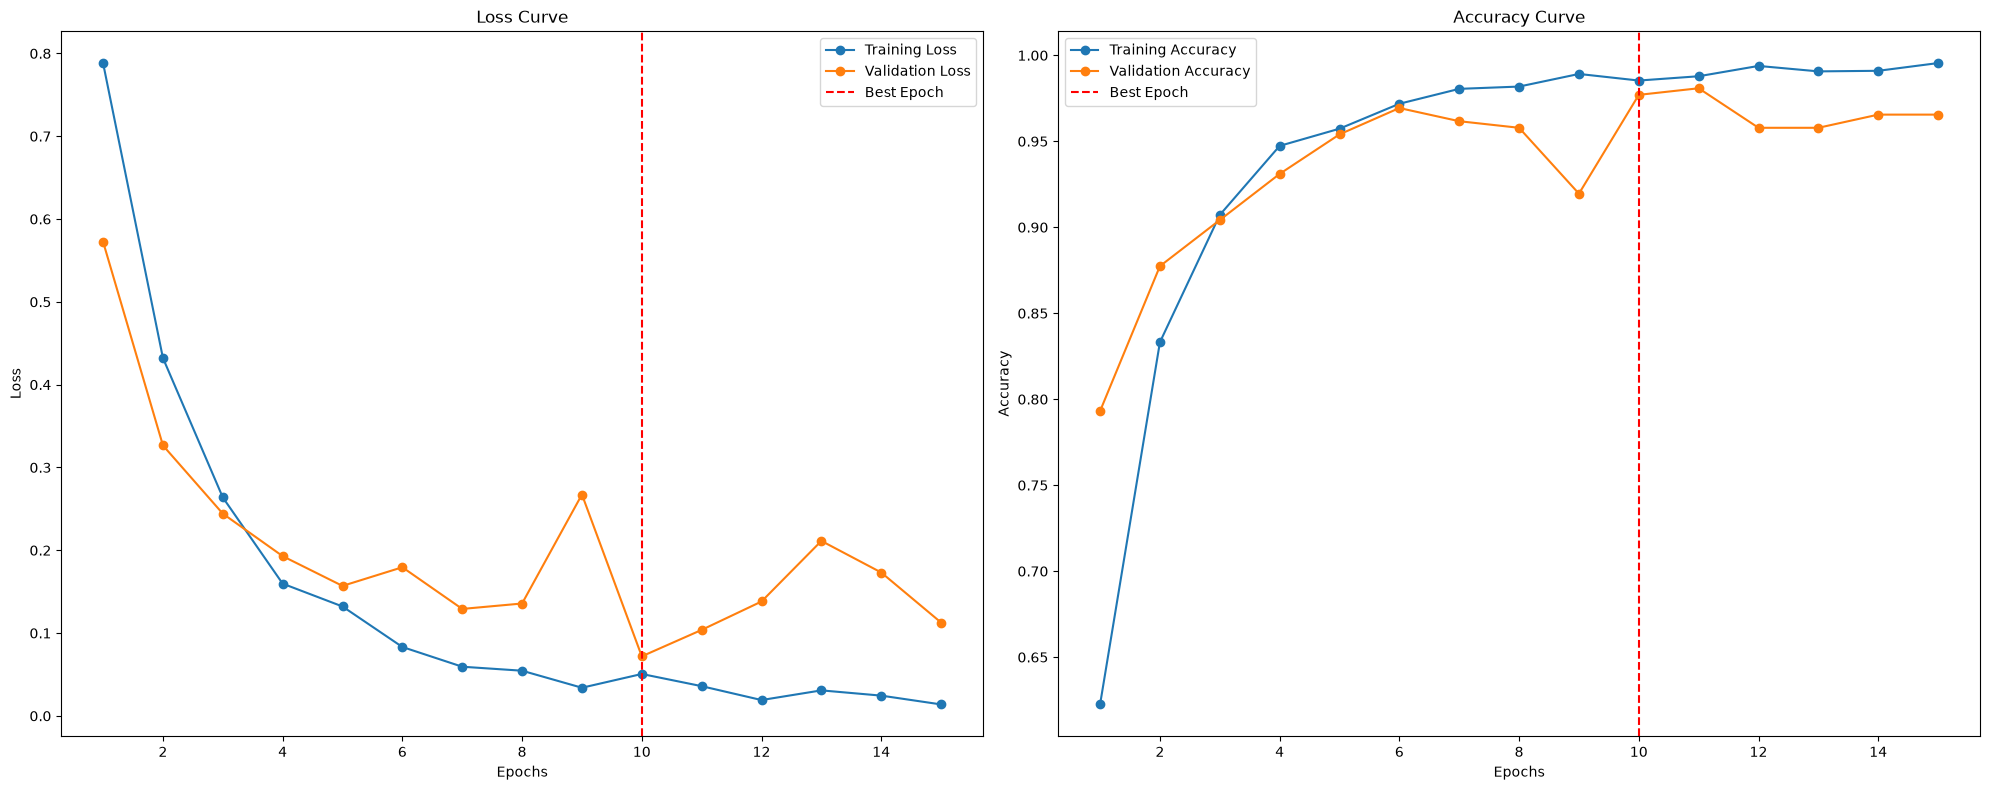


Training Report:
Total training time: 00:09:48
Total epochs run: 15
Best Training Loss: 0.0506 at epoch 10
Best Training Accuracy: 0.9853

Validation Report:
Best Validation Loss: 0.0719 at epoch 10
Best Validation Accuracy: 0.9770
Final Validation Loss: 0.1127
Final Validation Accuracy: 0.9655

Inference Report:
Total Inference Time (Validation only): 00:01:07


In [31]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [32]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.96565
Recall:      0.95760
Precision:   0.96084
F1 Score:    0.95920
MCC:         0.93694
PR AUC:      0.98992
Kappa:       0.93691
Specificity: 0.97872


In [36]:
import ssl, urllib
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

def load_convnext_atto(num_classes, pretrained=False):
    model = timm.create_model('convnextV2_tiny', pretrained=pretrained, num_classes=num_classes)
    
    in_features = model.get_classifier().in_features
    model.reset_classifier(0)
    
    model.head.fc = nn.Sequential(
        nn.Linear(in_features, 512),
        nn.GELU(),
        nn.Dropout(0.4),
        nn.Linear(512, num_classes)
    )
    return model

model = load_convnext_atto(num_classes=len(label_mapping), pretrained=False).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# 5. Scheduler fix: Force T_max to equal your actual total epochs.
# This prevents the learning rate from climbing back up and destroying your model's weights.
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)



Epoch 1/30
------------------------------


Validation Loss: 0.9588, Validation Accuracy: 0.5096
Training Loss: 0.9937, Training Accuracy: 0.4693

Epoch 2/30
------------------------------


Validation Loss: 0.5912, Validation Accuracy: 0.7280
Training Loss: 0.6945, Training Accuracy: 0.6853

Epoch 3/30
------------------------------


Validation Loss: 0.3873, Validation Accuracy: 0.8314
Training Loss: 0.5113, Training Accuracy: 0.7820

Epoch 4/30
------------------------------


Validation Loss: 0.2593, Validation Accuracy: 0.8774
Training Loss: 0.3876, Training Accuracy: 0.8487

Epoch 5/30
------------------------------


Validation Loss: 0.2619, Validation Accuracy: 0.9004
Training Loss: 0.2753, Training Accuracy: 0.9005
Patience Counter: 1/5

Epoch 6/30
------------------------------


... (5 outputs left out)

Validation Loss: 0.1795, Validation Accuracy: 0.9540
Training Loss: 0.0625, Training Accuracy: 0.9783
Patience Counter: 2/5

Epoch 12/30
------------------------------


Validation Loss: 0.2571, Validation Accuracy: 0.9464
Training Loss: 0.0191, Training Accuracy: 0.9953
Patience Counter: 3/5

Epoch 13/30
------------------------------


Validation Loss: 0.2385, Validation Accuracy: 0.9579
Training Loss: 0.0105, Training Accuracy: 0.9970
Patience Counter: 4/5

Epoch 14/30
------------------------------


Validation Loss: 0.2660, Validation Accuracy: 0.9425
Training Loss: 0.0064, Training Accuracy: 0.9985
Patience Counter: 5/5
Early stopping triggered at epoch 14.


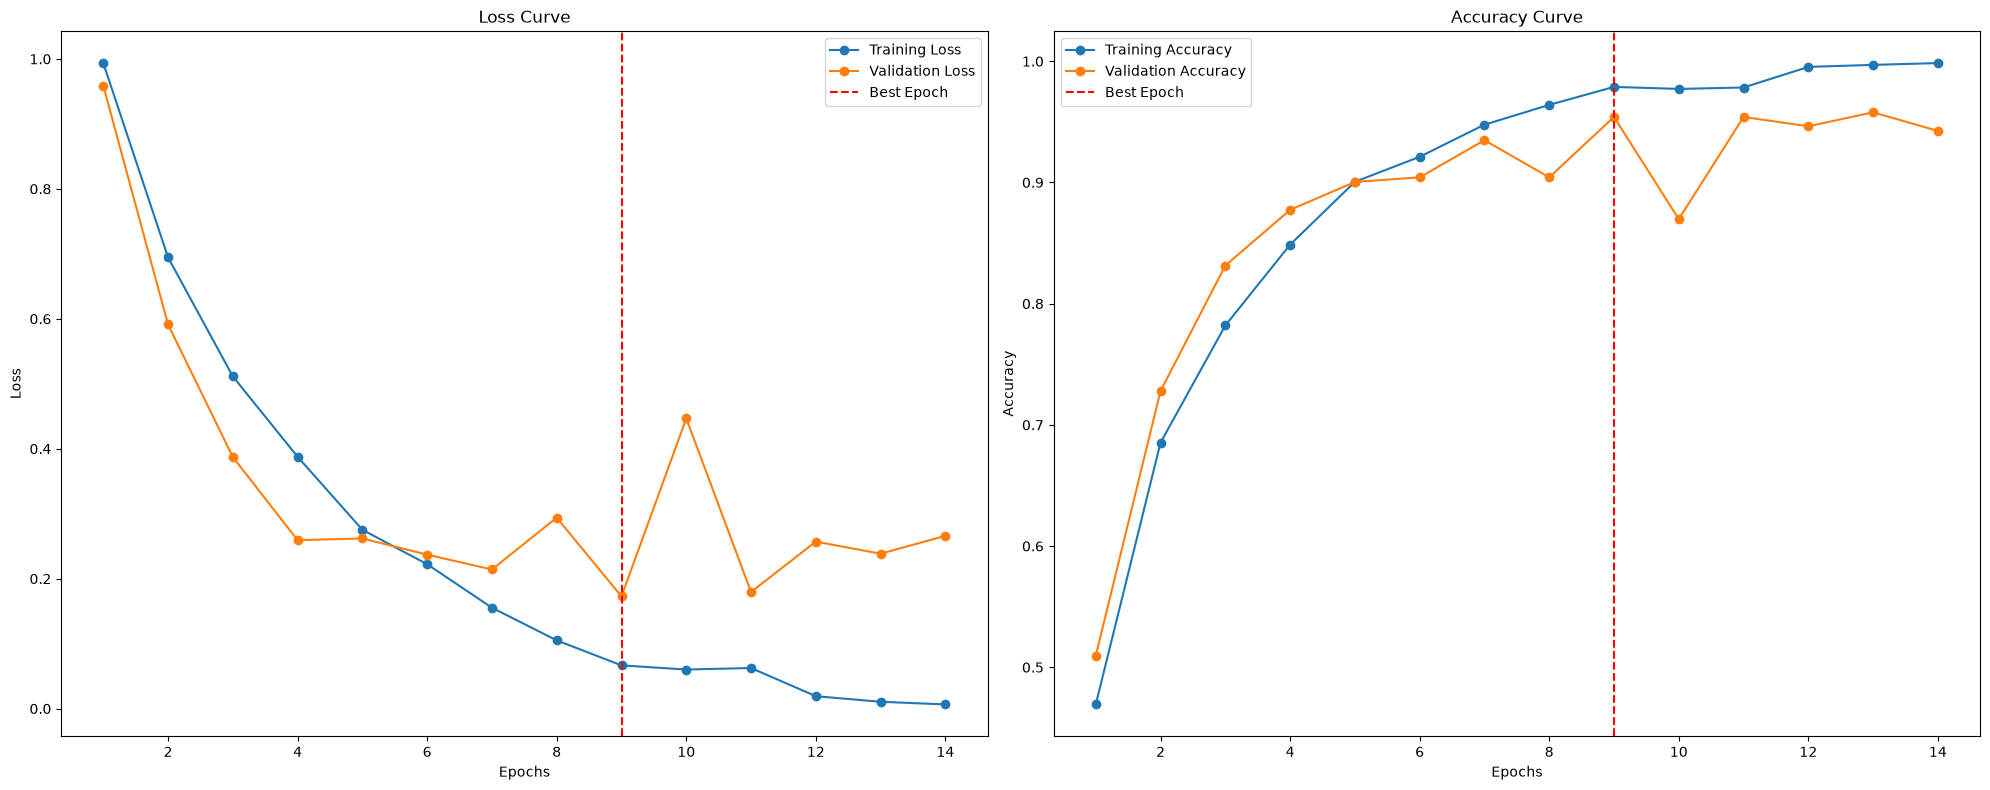


Training Report:
Total training time: 00:08:04
Total epochs run: 14
Best Training Loss: 0.0666 at epoch 9
Best Training Accuracy: 0.9788

Validation Report:
Best Validation Loss: 0.1727 at epoch 9
Best Validation Accuracy: 0.9540
Final Validation Loss: 0.2660
Final Validation Accuracy: 0.9425

Inference Report:
Total Inference Time (Validation only): 00:01:04


In [37]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [119]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.95802
Recall:      0.95605
Precision:   0.93896
F1 Score:    0.94606
MCC:         0.92602
PR AUC:      0.99092
Kappa:       0.92451
Specificity: 0.98219


In [26]:
import ssl, urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Create LeViT (pick size: levit_128s / 128 / 192 / 256)
num_classes = len(label_mapping)
model = timm.create_model('levit_192', pretrained=False, num_classes=num_classes)
# LeViT-192 head has 384 input features
in_features = 384  

# Replace the head with dropout + linear
model.head = nn.Sequential(
    nn.Dropout(p=0.4),
    nn.Linear(in_features, num_classes)
)

model = model.to(device)

# Loss & optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing
# T_max = total number of epochs (full cycle)
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)




Epoch 1/30
------------------------------


Validation Loss: 0.3045, Validation Accuracy: 0.8927
Training Loss: 0.6517, Training Accuracy: 0.7030

Epoch 2/30
------------------------------


Validation Loss: 0.3111, Validation Accuracy: 0.8774
Training Loss: 0.4044, Training Accuracy: 0.8387
Patience Counter: 1/5

Epoch 3/30
------------------------------


Validation Loss: 0.3558, Validation Accuracy: 0.8851
Training Loss: 0.2781, Training Accuracy: 0.8862
Patience Counter: 2/5

Epoch 4/30
------------------------------


Validation Loss: 0.3028, Validation Accuracy: 0.8774
Training Loss: 0.1872, Training Accuracy: 0.9308

Epoch 5/30
------------------------------


Validation Loss: 0.2439, Validation Accuracy: 0.9119
Training Loss: 0.1198, Training Accuracy: 0.9582

Epoch 6/30
------------------------------


... (4 outputs left out)

Validation Loss: 0.2808, Validation Accuracy: 0.9195
Training Loss: 0.0327, Training Accuracy: 0.9897
Patience Counter: 2/5

Epoch 11/30
------------------------------


Validation Loss: 0.2177, Validation Accuracy: 0.9425
Training Loss: 0.0201, Training Accuracy: 0.9952
Patience Counter: 3/5

Epoch 12/30
------------------------------


Validation Loss: 0.2271, Validation Accuracy: 0.9349
Training Loss: 0.0122, Training Accuracy: 0.9978
Patience Counter: 4/5

Epoch 13/30
------------------------------


Validation Loss: 0.2073, Validation Accuracy: 0.9272
Training Loss: 0.0161, Training Accuracy: 0.9958
Patience Counter: 5/5
Early stopping triggered at epoch 13.


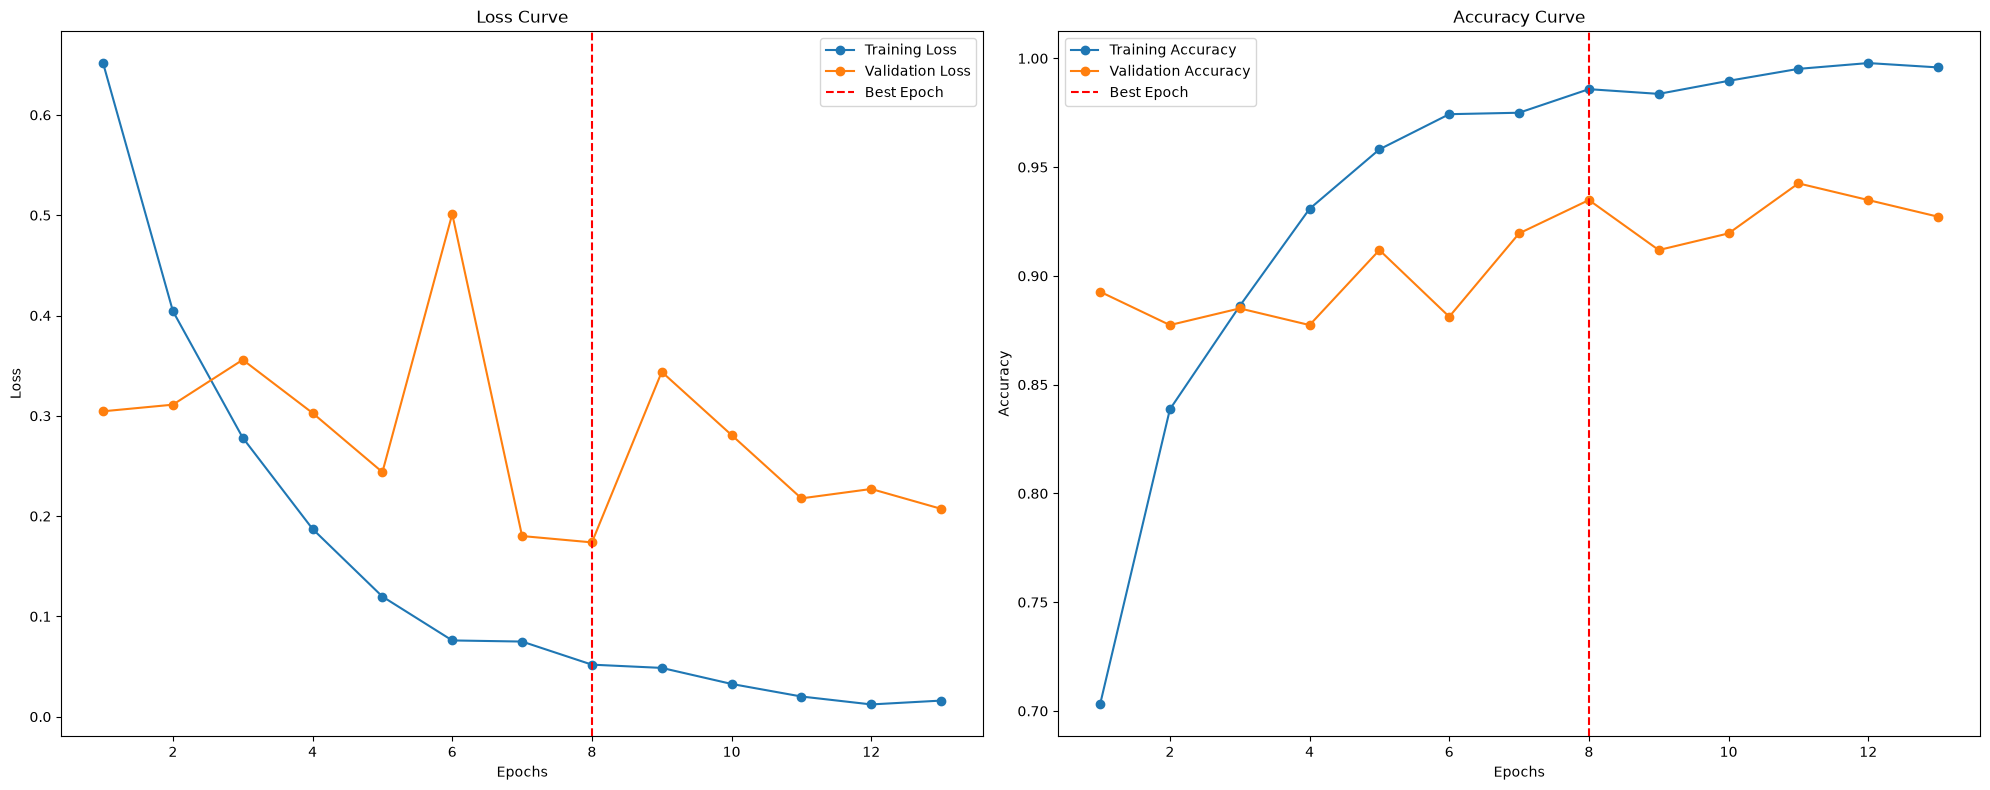


Training Report:
Total training time: 00:04:54
Total epochs run: 13
Best Training Loss: 0.0519 at epoch 8
Best Training Accuracy: 0.9858

Validation Report:
Best Validation Loss: 0.1738 at epoch 8
Best Validation Accuracy: 0.9349
Final Validation Loss: 0.2073
Final Validation Accuracy: 0.9272

Inference Report:
Total Inference Time (Validation only): 00:00:57


In [27]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)

In [28]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.95802
Recall:      0.96062
Precision:   0.95137
F1 Score:    0.95578
MCC:         0.92397
PR AUC:      0.98400
Kappa:       0.92372
Specificity: 0.97543



Epoch 1/30
------------------------------


Validation Loss: 0.6215, Validation Accuracy: 0.7548
Training Loss: 0.9694, Training Accuracy: 0.5225

Epoch 2/30
------------------------------


Validation Loss: 0.5368, Validation Accuracy: 0.8314
Training Loss: 0.6134, Training Accuracy: 0.7182

Epoch 3/30
------------------------------


Validation Loss: 0.3148, Validation Accuracy: 0.8582
Training Loss: 0.3818, Training Accuracy: 0.8587

Epoch 4/30
------------------------------


Validation Loss: 0.2165, Validation Accuracy: 0.9234
Training Loss: 0.2202, Training Accuracy: 0.9247

Epoch 5/30
------------------------------


Validation Loss: 0.2034, Validation Accuracy: 0.9157
Training Loss: 0.1279, Training Accuracy: 0.9578

Epoch 6/30
------------------------------


... (5 outputs left out)

Validation Loss: 0.1430, Validation Accuracy: 0.9502
Training Loss: 0.0242, Training Accuracy: 0.9925
Patience Counter: 2/5

Epoch 12/30
------------------------------


Validation Loss: 0.2365, Validation Accuracy: 0.9387
Training Loss: 0.0094, Training Accuracy: 0.9973
Patience Counter: 3/5

Epoch 13/30
------------------------------


Validation Loss: 0.2128, Validation Accuracy: 0.9195
Training Loss: 0.0081, Training Accuracy: 0.9972
Patience Counter: 4/5

Epoch 14/30
------------------------------


Validation Loss: 0.1321, Validation Accuracy: 0.9579
Training Loss: 0.0068, Training Accuracy: 0.9980
Patience Counter: 5/5
Early stopping triggered at epoch 14.


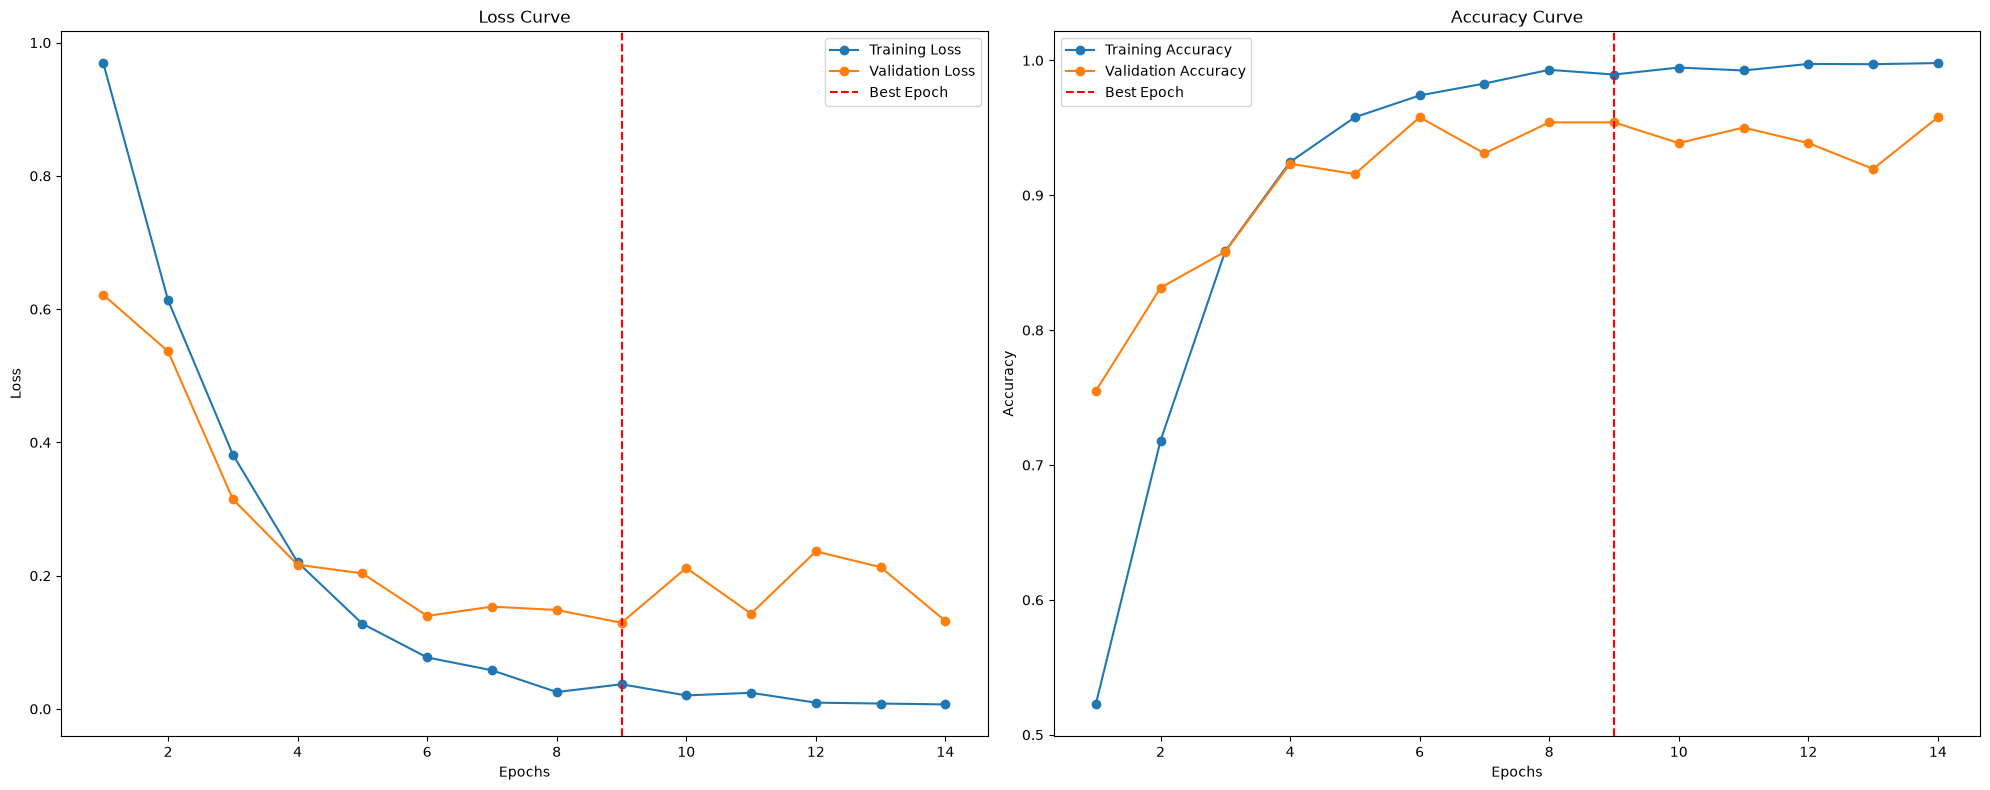


Training Report:
Total training time: 00:11:10
Total epochs run: 14
Best Training Loss: 0.0370 at epoch 9
Best Training Accuracy: 0.9895

Validation Report:
Best Validation Loss: 0.1293 at epoch 9
Best Validation Accuracy: 0.9540
Final Validation Loss: 0.1321
Final Validation Accuracy: 0.9579

Inference Report:
Total Inference Time (Validation only): 00:01:06


In [29]:
import ssl
import urllib
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# Target model identification
model_name = 'swinv2_cr_tiny_224'
num_classes = len(label_mapping)

# Create SwinV2 model (Set pretrained=True for massive accuracy gains on small leaf datasets)
model = timm.create_model(model_name, pretrained=False, num_classes=num_classes)

# Modify the head properly according to SwinV2's internal architecture structure
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )
elif hasattr(model, 'head') and isinstance(model.head, nn.Linear):
    in_features = model.head.in_features
    model.head = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# Loss & optimizer (Kept the same, AdamW is great for Swin architectures)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# Scheduler: Cosine Annealing 
scheduler = CosineAnnealingLR(optimizer, T_max=30, eta_min=1e-6)

# Training execution loop
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=30, patience=5, min_delta=0.001)


In [30]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.94275
Recall:      0.93574
Precision:   0.92237
F1 Score:    0.92884
MCC:         0.89628
PR AUC:      0.98303
Kappa:       0.89608
Specificity: 0.96924


In [29]:
import ssl
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import timm

ssl._create_default_https_context = ssl._create_unverified_context

# 1. Instantiate MaxViT Tiny (TF 224 variant)
num_classes = len(label_mapping)

# Option A: Built-in timm drop_rate (recommended for MaxViT)
model = timm.create_model(
    'maxvit_tiny_tf_224', 
    pretrained=False, 
    num_classes=num_classes,
    drop_rate=0.4  # Applies dropout directly to the head
)

# Option B: Explicit manual head modification (if you prefer manual control)
if hasattr(model, 'head') and hasattr(model.head, 'fc'):
    in_features = model.head.fc.in_features
    model.head.fc = nn.Sequential(
        nn.Dropout(p=0.4),
        nn.Linear(in_features, num_classes)
    )

model = model.to(device)

# 2. Loss & Optimizer
# Reduced label smoothing slightly to protect fine opacity classification confidence
criterion = nn.CrossEntropyLoss()

# MaxViT converges better with a slightly lower LR (3e-4 to 5e-4) and higher weight decay
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

# 3. Scheduler: Cosine Annealing
scheduler = CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)


Epoch 1/20
------------------------------


Validation Loss: 0.6346, Validation Accuracy: 0.6897
Training Loss: 0.8340, Training Accuracy: 0.6010

Epoch 2/20
------------------------------


Validation Loss: 0.3263, Validation Accuracy: 0.8582
Training Loss: 0.5815, Training Accuracy: 0.7603

Epoch 3/20
------------------------------


Validation Loss: 0.3065, Validation Accuracy: 0.8966
Training Loss: 0.4351, Training Accuracy: 0.8382

Epoch 4/20
------------------------------


Validation Loss: 0.6189, Validation Accuracy: 0.8046
Training Loss: 0.3140, Training Accuracy: 0.8833
Patience Counter: 1/5

Epoch 5/20
------------------------------


Validation Loss: 0.3457, Validation Accuracy: 0.8889
Training Loss: 0.2145, Training Accuracy: 0.9258
Patience Counter: 2/5

Epoch 6/20
------------------------------


... (8 outputs left out)

Validation Loss: 0.1708, Validation Accuracy: 0.9655
Training Loss: 0.0063, Training Accuracy: 0.9980
Patience Counter: 2/5

Epoch 15/20
------------------------------


Validation Loss: 0.1867, Validation Accuracy: 0.9693
Training Loss: 0.0030, Training Accuracy: 0.9990
Patience Counter: 3/5

Epoch 16/20
------------------------------


Validation Loss: 0.1579, Validation Accuracy: 0.9655
Training Loss: 0.0050, Training Accuracy: 0.9985
Patience Counter: 4/5

Epoch 17/20
------------------------------


Validation Loss: 0.1697, Validation Accuracy: 0.9693
Training Loss: 0.0030, Training Accuracy: 0.9987
Patience Counter: 5/5
Early stopping triggered at epoch 17.


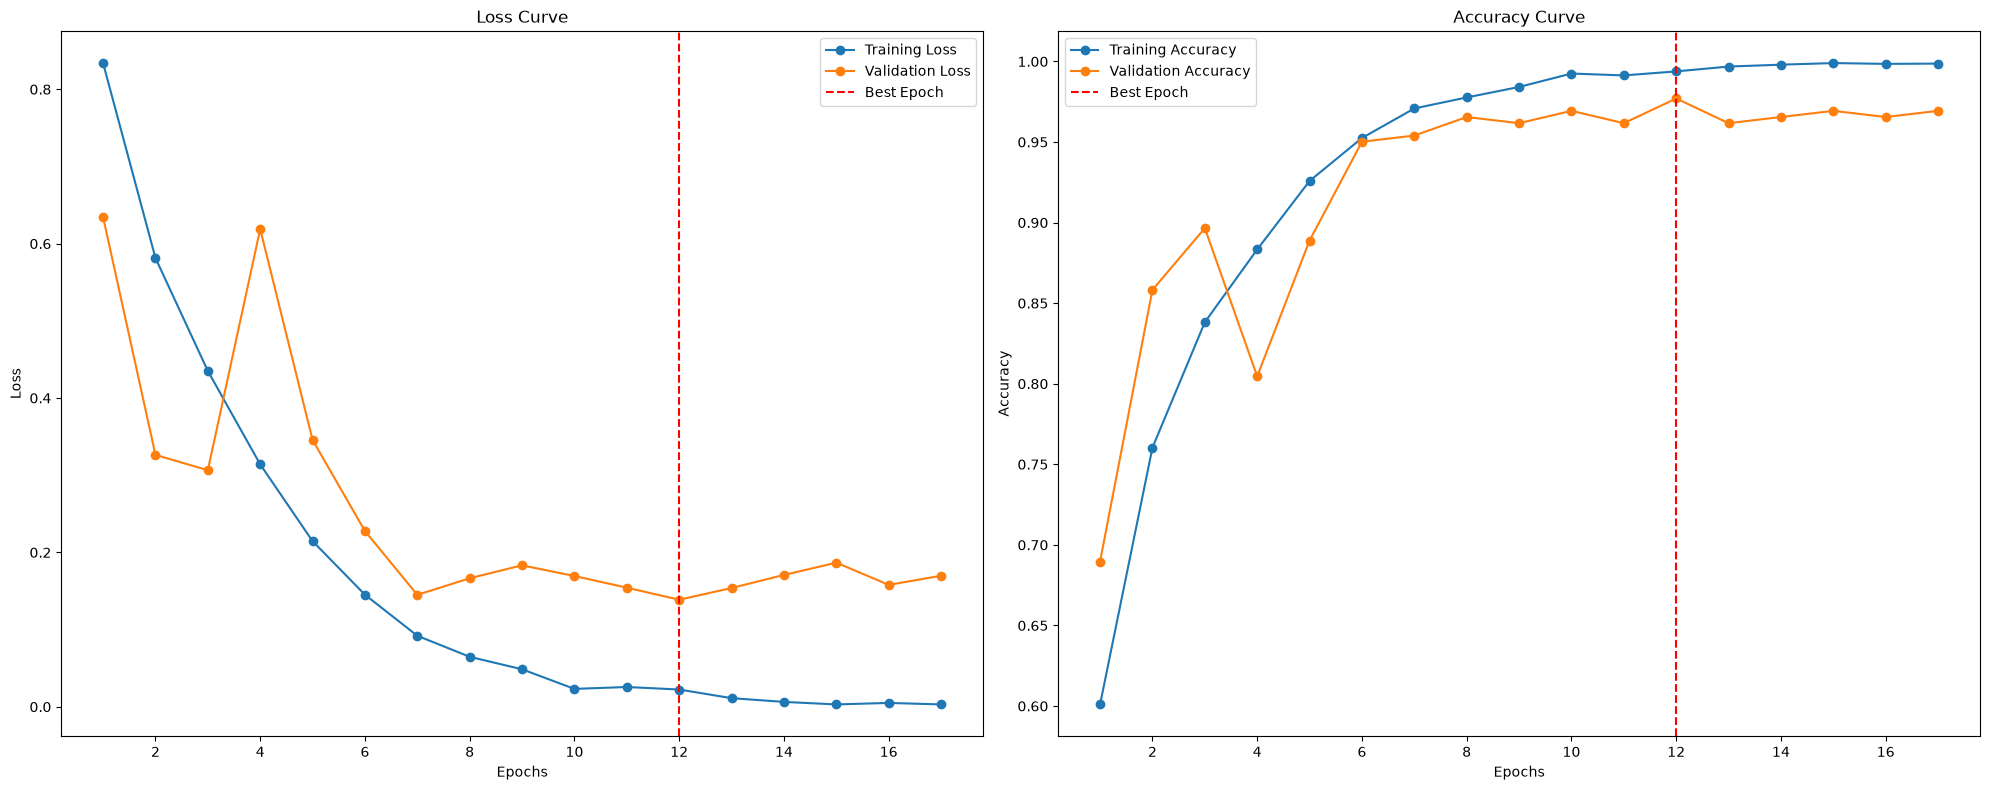


Training Report:
Total training time: 00:16:42
Total epochs run: 17
Best Training Loss: 0.0223 at epoch 12
Best Training Accuracy: 0.9938

Validation Report:
Best Validation Loss: 0.1387 at epoch 12
Best Validation Accuracy: 0.9770
Final Validation Loss: 0.1697
Final Validation Accuracy: 0.9693

Inference Report:
Total Inference Time (Validation only): 00:01:17


In [30]:
train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, num_epochs=20, patience=5, min_delta=0.001)

In [31]:
evaluate_model_with_metrics(model, test_loader)

Accuracy:    0.97328
Recall:      0.97248
Precision:   0.96307
F1 Score:    0.96756
MCC:         0.95172
PR AUC:      0.99465
Kappa:       0.95146
Specificity: 0.98697


# Comparison of FeLASwin-Net and Baseline Model's Computational Requirements

In [1]:
import torch
import timm
from fvcore.nn import FlopCountAnalysis

def profile_model(model_name, input_size=(1, 3, 224, 224)):
    """
    Calculates total parameters, GFLOPs, and estimated model size for a given timm model name.
    """
    # 1. Initialize model in evaluation mode
    model = timm.create_model(model_name, pretrained=False)
    model.eval()
    
    # 2. Count parameters using native PyTorch
    # Total parameters (including non-trainable ones)
    total_params = sum(p.numel() for p in model.parameters())
    # Trainable parameters only
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    # 3. Calculate Model Size (Parameters + Buffers) in Megabytes
    param_size = sum(p.nelement() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.nelement() * b.element_size() for b in model.buffers())
    size_mb = (param_size + buffer_size) / (1024 ** 2)
    
    # 4. Create dummy input tensor matching the specified size
    dummy_input = torch.randn(*input_size)
    
    # 5. Calculate FLOPs using fvcore
    flop_analyzer = FlopCountAnalysis(model, dummy_input)
    # Turn off warnings for unsupported operators (like some custom activations)
    flop_analyzer.unsupported_ops_warnings(False) 
    
    total_flops = flop_analyzer.total()
    gflops = total_flops / 1e9 # Convert to GigaFLOPs
    
    # 6. Format outputs for easier reading
    print(f"=== Profile Report for: {model_name} ===")
    print(f"Total Parameters     : {total_params:,} ({total_params / 1e6:.2f} M)")
    print(f"Trainable Parameters : {trainable_params:,} ({trainable_params / 1e6:.2f} M)")
    print(f"Estimated Model Size : {size_mb:.2f} MB")
    print(f"Computational Complexity: {gflops:.3f} GFLOPs")
    print("=" * (24 + len(model_name)))
    print()
    
    return {
        "model_name": model_name,
        "params_m": total_params / 1e6,
        "size_mb": size_mb,
        "gflops": gflops
    }

# --- Execution Example ---
if __name__ == "__main__":
    profile_model('coatnet_0_rw_224')
    profile_model('densenet201')
    profile_model('levit_192')
    profile_model('resnext101_32x4d')
    profile_model('efficientnet_b4')
    profile_model('swin_small_patch4_window7_224')
    profile_model('efficientvit_l1')

C:\Users\Samiz\anaconda3\envs\torch_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
stages.2.blocks.0.attn.attn_drop, stages.2.blocks.0.attn.rel_pos, stages.2.blocks.1.attn.attn_drop, stages.2.blocks.1.attn.rel_pos, stages.2.blocks.2.attn.attn_drop, stages.2.blocks.2.attn.rel_pos, stages.2.blocks.3.attn.attn_drop, stages.2.blocks.3.attn.rel_pos, stages.2.blocks.4.attn.attn_drop, stages.2.blocks.4.attn.rel_pos, stages.2.blocks.5.attn.attn_drop, stages.2.blocks.5.attn.rel_pos, stages.2.blocks.6.a

=== Profile Report for: coatnet_0_rw_224 ===
Total Parameters     : 27,435,562 (27.44 M)
Trainable Parameters : 27,435,562 (27.44 M)
Estimated Model Size : 106.79 MB
Computational Complexity: 4.234 GFLOPs

=== Profile Report for: densenet201 ===
Total Parameters     : 20,013,928 (20.01 M)
Trainable Parameters : 20,013,928 (20.01 M)
Estimated Model Size : 77.22 MB
Computational Complexity: 4.341 GFLOPs

=== Profile Report for: levit_192 ===
Total Parameters     : 10,947,069 (10.95 M)
Trainable Parameters : 10,947,069 (10.95 M)
Estimated Model Size : 43.30 MB
Computational Complexity: 0.662 GFLOPs

=== Profile Report for: resnext101_32x4d ===
Total Parameters     : 44,177,704 (44.18 M)
Trainable Parameters : 44,177,704 (44.18 M)
Estimated Model Size : 169.05 MB
Computational Complexity: 8.013 GFLOPs

=== Profile Report for: efficientnet_b4 ===
Total Parameters     : 19,341,616 (19.34 M)
Trainable Parameters : 19,341,616 (19.34 M)
Estimated Model Size : 74.26 MB
Computational Complexity: 

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
layers.0.blocks.1.drop_path1, layers.0.blocks.1.drop_path2, layers.1.blocks.0.drop_path1, layers.1.blocks.0.drop_path2, layers.1.blocks.1.drop_path1, layers.1.blocks.1.drop_path2, layers.2.blocks.0.drop_path1, layers.2.blocks.0.drop_path2, layers.2.blocks.1.drop_path1, layers.2.blocks.1.drop_path2, layers.2.blocks.10.drop_path1, layers.2.blocks.10.drop_path2, layers.2.blocks.11.drop_path1, layers.2.blocks.11.drop_path2, layers.2.blocks.12.drop_path1, layers.2.blocks.12.drop_path2, layers.2.blocks.13.drop_path1, layers.2.blocks.13.drop_path2, layers.2.blocks.14.drop_path1, layers.2.blocks.14.drop_path2, layers.2.blocks.15.drop_path1, layers.2.blocks.15.drop_path2, layers

=== Profile Report for: swin_small_patch4_window7_224 ===
Total Parameters     : 49,606,258 (49.61 M)
Trainable Parameters : 49,606,258 (49.61 M)
Estimated Model Size : 190.73 MB
Computational Complexity: 8.769 GFLOPs

=== Profile Report for: efficientvit_l1 ===
Total Parameters     : 52,654,088 (52.65 M)
Trainable Parameters : 52,654,088 (52.65 M)
Estimated Model Size : 200.97 MB
Computational Complexity: 5.271 GFLOPs



In [6]:
import torch
from fvcore.nn import FlopCountAnalysis

def profile_custom_model(model, model_name="FeLASwinNet", input_size=(1, 3, 224, 224)):
    """
    Calculates total parameters, GFLOPs, and estimated model size for a custom PyTorch model.
    """
    # 1. Ensure model is in evaluation mode
    model.eval()
    
    # 2. Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    # 3. Calculate Model Size (Parameters + Buffers) in Megabytes
    param_size = sum(p.nelement() * p.element_size() for p in model.parameters())
    buffer_size = sum(b.nelement() * b.element_size() for b in model.buffers())
    size_mb = (param_size + buffer_size) / (1024 ** 2)
    
    # 4. Create dummy input tensor matching the specified size
    dummy_input = torch.randn(*input_size)
    
    # 5. Calculate FLOPs using fvcore
    flop_analyzer = FlopCountAnalysis(model, dummy_input)
    # Turn off warnings for unsupported operators
    flop_analyzer.unsupported_ops_warnings(False) 
    
    total_flops = flop_analyzer.total()
    gflops = total_flops / 1e9 # Convert to GigaFLOPs
    
    # 6. Format outputs for easier reading
    print(f"=== Profile Report for: {model_name} ===")
    print(f"Total Parameters     : {total_params:,} ({total_params / 1e6:.2f} M)")
    print(f"Trainable Parameters : {trainable_params:,} ({trainable_params / 1e6:.2f} M)")
    print(f"Estimated Model Size : {size_mb:.2f} MB")
    print(f"Computational Complexity: {gflops:.3f} GFLOPs")
    print("=" * (24 + len(model_name)))
    print()
    
    return {
        "model_name": model_name,
        "params_m": total_params / 1e6,
        "size_mb": size_mb,
        "gflops": gflops
    }

# --- Execution Example ---
if __name__ == "__main__":
    # Instantiate your proposed model
    proposed_model = FeLASwinNet(num_classes=3, drop_path_rate=0.1, attn_drop_rate=0.1)
    
    # Generate the computational profile
    profile_custom_model(proposed_model)

The following submodules of the model were never called during the trace of the graph. They may be unused, or they were accessed by direct calls to .forward() or via other python methods. In the latter case they will have zeros for statistics, though their statistics will still contribute to their parent calling module.
stage3_swin.1.drop_path, stage3_swin.2.drop_path, stage3_swin.3.drop_path, stage4_swin.0.drop_path, stage4_swin.1.drop_path


=== Profile Report for: FeLASwinNet ===
Total Parameters     : 2,811,225 (2.81 M)
Trainable Parameters : 2,811,225 (2.81 M)
Estimated Model Size : 10.93 MB
Computational Complexity: 0.634 GFLOPs



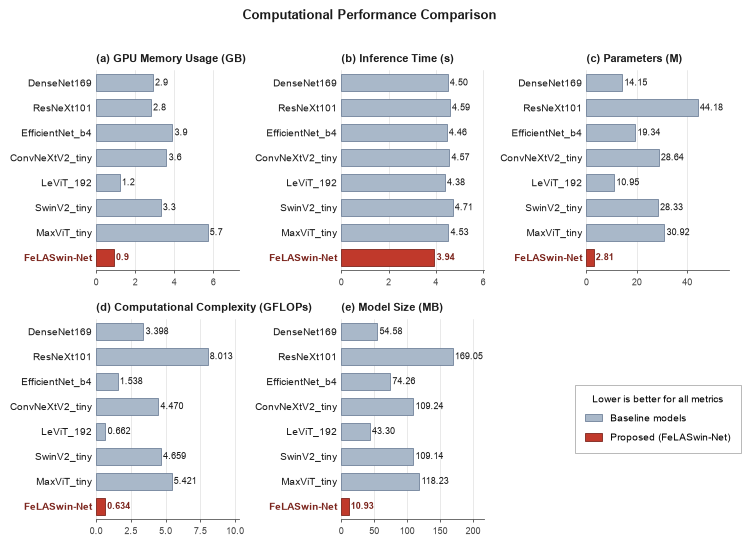

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# ---------------------------------------------------------------
# 1. Data
# ---------------------------------------------------------------
models = [
    'DenseNet169', 'ResNeXt101', 'EfficientNet_b4',
    'ConvNeXtV2_tiny', 'LeViT_192', 'SwinV2_tiny',
    'MaxViT_tiny', 'FeLASwin-Net'
]

# metric name -> (values, decimals for value labels)
metrics = {
    'GPU Memory Usage (GB)':             ([2.9, 2.8, 3.9, 3.6, 1.2, 3.3, 5.7, 0.9], 1),
    'Inference Time (s)':                ([4.50, 4.59, 4.46, 4.57, 4.38, 4.71, 4.53, 3.94], 2),
    'Parameters (M)':                    ([14.15, 44.18, 19.34, 28.64, 10.95, 28.33, 30.92, 2.81], 2),
    'Computational Complexity (GFLOPs)': ([3.398, 8.013, 1.538, 4.470, 0.662, 4.659, 5.421, 0.634], 3),
    'Model Size (MB)':                   ([54.58, 169.05, 74.26, 109.24, 43.30, 109.14, 118.23, 10.93], 2),
}

proposed_model = 'FeLASwin-Net'

# ---------------------------------------------------------------
# 2. Journal style (flat, colour-blind safe, grayscale-friendly)
# ---------------------------------------------------------------
BASE_COLOR = '#A9B8C9'   # light steel blue-grey  -> baselines
BASE_EDGE = '#6F8199'
PROP_COLOR = '#C0392B'   # deep crimson           -> proposed (much darker in grayscale)
PROP_EDGE = '#7B241C'
TEXT_COLOR = '#1A1A1A'
GRID_COLOR = '#D9D9D9'

mpl.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 7,
    'axes.titlesize': 8,
    'axes.titleweight': 'bold',
    'axes.labelsize': 7,
    'xtick.labelsize': 6.5,
    'ytick.labelsize': 7,
    'axes.linewidth': 0.6,
    'xtick.major.width': 0.6,
    'xtick.major.size': 2.5,
    'pdf.fonttype': 42,      # embed TrueType fonts (journal requirement)
    'ps.fonttype': 42,
    'svg.fonttype': 'none',
    'savefig.facecolor': 'white',
})

fig, axes = plt.subplots(2, 3, figsize=(7.4, 5.4), facecolor='white')
axes = axes.flatten()
y_pos = np.arange(len(models))
panel_tags = ['(a)', '(b)', '(c)', '(d)', '(e)']

# ---------------------------------------------------------------
# 3. Panels
# ---------------------------------------------------------------
for idx, (metric_name, (values, dec)) in enumerate(metrics.items()):
    ax = axes[idx]
    ax.set_facecolor('white')

    is_prop = [m == proposed_model for m in models]
    face = [PROP_COLOR if p else BASE_COLOR for p in is_prop]
    edge = [PROP_EDGE if p else BASE_EDGE for p in is_prop]

    bars = ax.barh(y_pos, values, height=0.68, color=face, edgecolor=edge,
                   linewidth=0.6, zorder=3)

    # Value labels
    vmax = max(values)
    for bar, p in zip(bars, is_prop):
        w = bar.get_width()
        ax.text(w + vmax * 0.02, bar.get_y() + bar.get_height() / 2,
                f'{w:.{dec}f}', ha='left', va='center', fontsize=6.2,
                fontweight='bold' if p else 'normal',
                color=PROP_EDGE if p else TEXT_COLOR, zorder=4)

    # Axes cosmetics
    ax.set_xlim(0, vmax * 1.28)          # head-room for value labels
    ax.set_ylim(len(models) - 0.5, -0.5) # first model at the top
    ax.set_yticks(y_pos)
    ax.set_yticklabels(models)
    for lbl, p in zip(ax.get_yticklabels(), is_prop):
        lbl.set_color(PROP_EDGE if p else TEXT_COLOR)
        lbl.set_fontweight('bold' if p else 'normal')

    ax.set_title(f'{panel_tags[idx]} {metric_name}', loc='left', pad=6, color=TEXT_COLOR)

    for s in ('top', 'right', 'left'):
        ax.spines[s].set_visible(False)
    ax.spines['bottom'].set_color('#555555')
    ax.xaxis.grid(True, linestyle='-', linewidth=0.4, color=GRID_COLOR, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0, pad=3)
    ax.tick_params(axis='x', colors='#444444')
    ax.locator_params(axis='x', nbins=5)

# ---------------------------------------------------------------
# 4. Legend in the empty 6th slot
# ---------------------------------------------------------------
axes[5].axis('off')
legend_elements = [
    Patch(facecolor=BASE_COLOR, edgecolor=BASE_EDGE, linewidth=0.6, label='Baseline models'),
    Patch(facecolor=PROP_COLOR, edgecolor=PROP_EDGE, linewidth=0.6, label='Proposed (FeLASwin-Net)'),
]
axes[5].legend(handles=legend_elements, loc='center', fontsize=7.5, frameon=True,
               facecolor='white', edgecolor='#999999', fancybox=False,
               borderpad=1.0, labelspacing=0.9, handlelength=1.6,
               title='Lower is better for all metrics', title_fontsize=7)
axes[5].get_legend().get_frame().set_linewidth(0.6)

# Optional overall title (most journals prefer the title in the caption -> set to None)
FIGURE_TITLE = 'Computational Performance Comparison'
if FIGURE_TITLE:
    fig.suptitle(FIGURE_TITLE, fontsize=9.5, fontweight='bold', color=TEXT_COLOR, y=0.995)

fig.tight_layout(h_pad=1.6, w_pad=1.2, rect=[0, 0, 1, 0.975 if FIGURE_TITLE else 1])

# ---------------------------------------------------------------
# 5. Save (vector + high-resolution raster)
# ---------------------------------------------------------------
base = 'computational_performance_comparison_journal'
fig.savefig(f'{base}.png', dpi=600, bbox_inches='tight')
plt.show()